# Proyecto final — FPCA del uso del Subte de Buenos Aires

## Versión local para VS Code, segmentada y optimizada (2014–2026)

El notebook realiza seis etapas:

1. **Carga y auditoría:** detecta los CSV dentro de `data`, normaliza formatos históricos y revisa fechas, intervalos y faltantes.
2. **Caché persistente:** cada archivo crudo se procesa una sola vez. Las ejecuciones siguientes reutilizan Parquet guardados en `subte_fpca_work`.
3. **Perfiles funcionales:** construye curvas robustas por línea–estación, año y segmento de día.
4. **FPCA y clustering segmentados:** ajusta modelos independientes para **Laborable**, **Sábado** y **Domingo/Feriado**.
5. **Evolución:** estudia composición de clusters, transiciones, trayectorias, pandemia y diferencias entre tipos de día.
6. **MaxVol e interpretación:** selecciona prototipos reales en el espacio FPCA, los destaca gráficamente y genera una lectura narrativa de clusters y casos frontera.

### Cambio metodológico principal

No se mezclan todos los tipos de día en un único K-means. Cada segmento tiene su propia FPCA y sus propios clusters. Así, los grupos describen diferencias **entre estaciones dentro de un mismo contexto temporal**, en vez de limitarse a separar días laborables de no laborables.

Los modelos se ajustan con años completos y no pandémicos como referencia. Los perfiles de 2020–2021 y de años parciales se proyectan después sobre esa referencia, lo que permite medir cuánto se apartan del patrón habitual sin dejar que definan por sí solos los clusters.

### Uso

- Abrí la carpeta `proyecto_subtes` en VS Code.
- Seleccioná el kernel del `.venv` de este proyecto.
- Verificá en la celda **Parámetros** que `CARPETA_DATOS` apunte a `data`.
- Ejecutá todas las celdas.

La primera ejecución es lenta. Después, los CSV correctos se reutilizan desde la caché. No borres `subte_fpca_work` salvo que quieras reconstruir todo.

In [1]:
# Dependencias del kernel local.
# Puede desactivarse la instalación automática con SUBTE_AUTO_INSTALL=0.
import importlib.util
import os
import subprocess
import sys

AUTO_INSTALAR_PAQUETES = os.getenv("SUBTE_AUTO_INSTALL", "1").lower() in {
    "1", "true", "si", "sí"
}

requeridos = {
    "duckdb": "duckdb>=1.1",
    "pyarrow": "pyarrow>=14",
    "holidays": "holidays>=0.40",
    "plotly": "plotly>=5.18",
    "sklearn": "scikit-learn>=1.4",
    "scipy": "scipy>=1.11",
    "psutil": "psutil>=5.9",
}

faltan = [pip_name for modulo, pip_name in requeridos.items()
          if importlib.util.find_spec(modulo) is None]

if faltan:
    if not AUTO_INSTALAR_PAQUETES:
        raise ModuleNotFoundError(
            "Faltan paquetes: " + ", ".join(faltan) +
            ". Instálelos en el kernel seleccionado de VS Code."
        )
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", *faltan
    ])

from collections import Counter, defaultdict
from contextlib import contextmanager
from itertools import combinations
from pathlib import Path
import csv
import gc
import hashlib
import json
import math
import re
import shutil
import unicodedata
import warnings
import zipfile

import duckdb
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import psutil
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from scipy.linalg import qr
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    adjusted_rand_score,
    pairwise_distances,
    silhouette_samples,
    silhouette_score,
)
from sklearn.preprocessing import SplineTransformer, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("Entorno preparado")
print("Python:", sys.version.split()[0])
print("DuckDB:", duckdb.__version__)
print("Pandas:", pd.__version__)
print("PyArrow:", pa.__version__)


Entorno preparado
Python: 3.12.0
DuckDB: 1.5.5
Pandas: 3.0.5
PyArrow: 25.0.1


## 0. Parámetros locales

Editá `CARPETA_DATOS`. En Windows usá una cadena cruda, por ejemplo `Path(r"D:\Datos\subte")`. En Linux o macOS, por ejemplo `Path("/home/usuario/datos/subte")`.

`CARPETA_TRABAJO` contiene cachés y resultados. `CARPETA_TEMP` recibe los archivos temporales de DuckDB. Ambas deberían estar en un SSD local con suficiente espacio libre.

Los parámetros con valor `0` en la configuración de DuckDB se calculan automáticamente a partir de los recursos disponibles.


In [2]:
# ============================================================
# Parámetros
# En la estructura mostrada por el usuario no hace falta cambiar rutas.
# ============================================================

CANDIDATOS_RAIZ = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
RAIZ_PROYECTO = next(
    (ruta for ruta in CANDIDATOS_RAIZ
     if (ruta / "data").is_dir() and (ruta / "subte_fpca_work").is_dir()),
    None,
)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto (data y subte_fpca_work).")
CARPETA_DATOS = RAIZ_PROYECTO / "data"
CARPETA_TRABAJO = RAIZ_PROYECTO / "subte_fpca_work"
CARPETA_TEMP = CARPETA_TRABAJO / "duckdb_tmp"

# Uso normal: dejar ambos valores así.
REPROCESAR_TODO = False
REPROCESAR_ANIOS = []          # Ejemplo: [2026]

# Ajustes de carga y caché.
LIMPIAR_CACHE_FUENTES_ELIMINADAS = True
VALIDAR_CARGA_COMPLETA = True
AUDITAR_DUPLICADOS = True
AUDITAR_MOLINETES = True
CHUNK_SIZE = 300_000
PARQUET_COMPRESSION = "zstd"

# Cambiar esta versión invalida las capas cuya limpieza haya cambiado.
CACHE_VERSION = "vscode-local-v3-fechas-sin-premetro"
NORMALIZACION_ESTACIONES_VERSION = "v2-aliases-inventario-y-mapa-2026-08-31"

# 0 = detección automática.
DUCKDB_THREADS = 0
DUCKDB_MEMORY_GB = 0
DUCKDB_TEMP_GB = 0
RESERVA_DISCO_GB = 3

ANIO_MIN = 2014
ANIO_MAX = 2026
INTERVALO_MIN = 15
TOLERANCIA_MIN = 0.25
USAR_FERIADOS = True
LINEAS_EXCLUIDAS = {"LINEAPM"}  # Premetro fuera del universo analítico.

# Calidad mínima.
UMBRAL_COBERTURA_DIA = 0.80
UMBRAL_COBERTURA_CURVA = 0.80
PRESENCIA_SLOT_ESPERADO = 0.50

# Segmentación previa a FPCA y clustering.
SEGMENTOS_DIA = ["Laborable", "Sábado", "Domingo/Feriado"]
MIN_DIAS_SEGMENTO = {
    "Laborable": 60,
    "Sábado": 18,
    "Domingo/Feriado": 18,
}
ANIOS_EXCLUIR_REFERENCIA = [2020, 2021]
EXCLUIR_ANIOS_PARCIALES_DE_EVOLUCION = True

# FPCA y clustering.
N_KNOTS = 18
VAR_OBJETIVO = 0.90
K_MAX = 8
MIN_PROP_CLUSTER = 0.05
REPETICIONES_K = 10
SEED = 42

assert CARPETA_DATOS.exists(), f"No existe la carpeta de datos: {CARPETA_DATOS}"
assert ANIO_MIN <= ANIO_MAX and INTERVALO_MIN > 0

WORK = CARPETA_TRABAJO.resolve()
CACHE = WORK / "cache_local"
PARTS = CACHE / "estandarizados"
STATION_PARTS = CACHE / "station_slot_parts"
DEDUP_PARTS = CACHE / "dedup_parts"
OUTDIR = WORK / "resultados"
TMP_DUCKDB = CARPETA_TEMP.resolve()
ARCHIVO_FORMATOS_FECHA = WORK / "formato_fechas_por_archivo.csv"
assert ARCHIVO_FORMATOS_FECHA.exists(), (
    f"No existe el catálogo de formatos: {ARCHIVO_FORMATOS_FECHA}"
)

for carpeta in [WORK, CACHE, PARTS, STATION_PARTS, DEDUP_PARTS, OUTDIR, TMP_DUCKDB]:
    carpeta.mkdir(parents=True, exist_ok=True)

print("Datos:", CARPETA_DATOS)
print("Caché y resultados:", WORK)
print("Temporales DuckDB:", TMP_DUCKDB)

Datos: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/data
Caché y resultados: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/subte_fpca_work
Temporales DuckDB: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/subte_fpca_work/duckdb_tmp


In [3]:
# ============================================================
# Descubrimiento de CSV locales y miembros CSV dentro de ZIP
# ============================================================

def _fuente_csv(path: Path) -> dict:
    st = path.stat()
    rid = str(path.resolve())
    return {
        "tipo": "csv",
        "id": rid,
        "path": rid,
        "member": None,
        "nombre": path.name,
        "contenedor": "",
        "tamano": int(st.st_size),
        "mtime_ns": int(st.st_mtime_ns),
        "crc": None,
    }


def _fuente_zip(path: Path, info: zipfile.ZipInfo) -> dict:
    st = path.stat()
    zpath = str(path.resolve())
    rid = f"{zpath}::{info.filename}"
    return {
        "tipo": "zip",
        "id": rid,
        "path": zpath,
        "member": info.filename,
        "nombre": Path(info.filename).name,
        "contenedor": path.name,
        "tamano": int(info.file_size),
        "mtime_ns": int(st.st_mtime_ns),
        "crc": int(info.CRC),
    }


def _esta_dentro(path: Path, root: Path) -> bool:
    try:
        path.resolve().relative_to(root.resolve())
        return True
    except ValueError:
        return False


def localizar_fuentes() -> list[dict]:
    base = CARPETA_DATOS.resolve()
    if not base.exists():
        raise FileNotFoundError(
            f"No existe {base}. Edite CARPETA_DATOS en la celda de parámetros."
        )

    # Búsqueda case-insensitive y exclusión de las carpetas generadas por el notebook.
    candidatos = [
        p for p in base.rglob("*")
        if p.is_file()
        and not _esta_dentro(p, WORK)
        and not _esta_dentro(p, TMP_DUCKDB)
    ]
    csv_paths = sorted(p for p in candidatos if p.suffix.lower() == ".csv")
    zip_paths = sorted(p for p in candidatos if p.suffix.lower() == ".zip")

    fuentes = [_fuente_csv(p) for p in csv_paths]

    for zpath in zip_paths:
        try:
            with zipfile.ZipFile(zpath) as zf:
                for info in zf.infolist():
                    if not info.is_dir() and info.filename.lower().endswith(".csv"):
                        fuentes.append(_fuente_zip(zpath, info))
        except zipfile.BadZipFile:
            print("ZIP inválido, omitido:", zpath)

    fuentes = sorted(fuentes, key=lambda x: x["id"])
    if not fuentes:
        raise FileNotFoundError("No se encontraron CSV ni ZIP con CSV")
    return fuentes


@contextmanager
def abrir_fuente(fuente: dict):
    if fuente["tipo"] == "csv":
        with open(fuente["path"], "rb") as fh:
            yield fh
    else:
        with zipfile.ZipFile(fuente["path"]) as zf:
            with zf.open(fuente["member"], "r") as fh:
                yield fh


def leer_muestra_fuente(fuente: dict, n: int = 131_072) -> bytes:
    with abrir_fuente(fuente) as fh:
        return fh.read(n)


FORMATOS_FECHA_PANDAS = {
    "yyyy-mm-dd": "%Y-%m-%d",
    "dd/mm/yyyy": "%d/%m/%Y",
    "mixed_iso_dmy": "mixed_iso_dmy",
    "mixed_2020_blocks": "mixed_2020_blocks",
}


def _clave_relativa_fuente(fuente: dict) -> str:
    if fuente["tipo"] != "csv":
        raise ValueError(f"El catálogo no contempla ZIP: {fuente['id']}")
    return Path(fuente["path"]).resolve().relative_to(RAIZ_PROYECTO).as_posix()


def cargar_catalogo_formatos_fecha() -> dict[str, dict]:
    catalogo = pd.read_csv(ARCHIVO_FORMATOS_FECHA, dtype="string")
    requeridas = {"archivo", "columna_fecha", "tipo"}
    if not requeridas.issubset(catalogo.columns):
        raise ValueError(f"Columnas requeridas en catálogo: {sorted(requeridas)}")
    catalogo["archivo"] = (
        catalogo["archivo"].str.replace(r"\\", "/", regex=True).str.strip()
    )
    catalogo["tipo"] = catalogo["tipo"].str.strip().str.lower()
    desconocidos = set(catalogo["tipo"].dropna()) - set(FORMATOS_FECHA_PANDAS)
    if desconocidos:
        raise ValueError(f"Tipos de fecha no soportados: {sorted(desconocidos)}")
    if catalogo["archivo"].duplicated().any():
        raise ValueError("Hay rutas duplicadas en formato_fechas_por_archivo.csv")
    return {
        fila.archivo: {
            "columna": str(fila.columna_fecha).strip().lower(),
            "tipo": fila.tipo,
            "formato": FORMATOS_FECHA_PANDAS[fila.tipo],
        }
        for fila in catalogo.itertuples(index=False)
    }


CATALOGO_FORMATOS_FECHA = cargar_catalogo_formatos_fecha()


def firma_fuente(fuente: dict) -> str:
    datos = {
        "id": fuente["id"],
        "tamano": fuente["tamano"],
        "mtime_ns": fuente["mtime_ns"],
        "crc": fuente["crc"],
        "cache_version": CACHE_VERSION,
        "intervalo": INTERVALO_MIN,
        "tolerancia": TOLERANCIA_MIN,
        "formato_fecha": fuente.get("formato_fecha", {}),
        "lineas_excluidas": sorted(LINEAS_EXCLUIDAS),
    }
    if fuente.get("excluir_fuente_pm", False):
        # Solo altera la firma de los seis archivos PM.
        datos["exclusion_fuente"] = "PREMETRO_PM"
    return hashlib.sha256(
        json.dumps(datos, sort_keys=True).encode("utf-8")
    ).hexdigest()


fuentes = localizar_fuentes()
for fuente in fuentes:
    clave = _clave_relativa_fuente(fuente)
    if clave not in CATALOGO_FORMATOS_FECHA:
        raise ValueError(f"Falta formato de fecha para: {clave}")
    fuente["formato_fecha"] = CATALOGO_FORMATOS_FECHA[clave]
    fuente["excluir_fuente_pm"] = "-PM-" in fuente["nombre"].upper()

sobran_formatos = sorted(set(CATALOGO_FORMATOS_FECHA) - {
    _clave_relativa_fuente(f) for f in fuentes
})
if sobran_formatos:
    print("Entradas del catálogo sin fuente local:", sobran_formatos)
inventario = pd.DataFrame({
    "nombre": [f["nombre"] for f in fuentes],
    "contenedor_zip": [f["contenedor"] for f in fuentes],
    "tipo": [f["tipo"] for f in fuentes],
    "tamano_MB": [f["tamano"] / 1024**2 for f in fuentes],
    "origen": [f["id"] for f in fuentes],
})

print(
    f"Fuentes CSV: {len(fuentes):,} | "
    f"Tamaño descomprimido aproximado: {inventario.tamano_MB.sum():,.1f} MB"
)
display(inventario.head(50))


Fuentes CSV: 122 | Tamaño descomprimido aproximado: 12,031.9 MB


,nombre,contenedor_zip,tipo,tamano_MB,origen
0,molinetes-2014.csv,,csv,914.620,/Users/nadinasoler/Documents/documentos/Nari/p...
1,molinetes-2015.csv,,csv,"1,036.824",/Users/nadinasoler/Documents/documentos/Nari/p...
2,molinetes-2016.csv,,csv,"1,026.788",/Users/nadinasoler/Documents/documentos/Nari/p...
3,molinetes-2017.csv,,csv,"1,185.536",/Users/nadinasoler/Documents/documentos/Nari/p...
4,molinetes-2018.csv,,csv,"1,125.816",/Users/nadinasoler/Documents/documentos/Nari/p...
5,molinetes-2019.csv,,csv,"1,181.318",/Users/nadinasoler/Documents/documentos/Nari/p...
6,molinetes-2020.csv,,csv,443.662,/Users/nadinasoler/Documents/documentos/Nari/p...
7,molinetes-2021.csv,,csv,657.464,/Users/nadinasoler/Documents/documentos/Nari/p...
8,202201_PAX15min-ABC.csv,,csv,42.722,/Users/nadinasoler/Documents/documentos/Nari/p...
9,202201_PAX15min-DEH.csv,,csv,32.959,/Users/nadinasoler/Documents/documentos/Nari/p...


## 1. Carga incremental y control de calidad

Esta sección reconoce las distintas variantes de CSV, procesa cada fuente por bloques y guarda un Parquet persistente. Los archivos ya válidos se reutilizan; los omitidos, fallidos o sin intervalos de 15 minutos se vuelven a intentar automáticamente.


In [4]:
# ============================================================
# Normalización de columnas, detección robusta de formato y limpieza
# ============================================================

def sin_acentos(x):
    return "".join(
        c for c in unicodedata.normalize("NFKD", str(x))
        if not unicodedata.combining(c)
    )


def token(x):
    """Normaliza nombres incluso si quedaron BOM, NUL, comillas o sufijos '(1)'."""
    s = (
        str(x)
        .replace("\x00", "")
        .replace("\ufeff", "")
        .strip()
        .strip('"')
        .strip("'")
    )
    s = re.sub(r"\s*\(\s*\d+\s*\)\s*$", "", s)
    s = re.sub(r"\.\d+\s*$", "", s)
    s = re.sub(
        r"[^a-z0-9]+",
        "_",
        sin_acentos(s).lower(),
    ).strip("_")
    s = re.sub(r"_(?:1|2)$", "", s)
    return s


ALIASES = {
    "periodo": "periodo",
    "period": "periodo",
    "mes": "periodo",
    "fecha": "fecha",
    "date": "fecha",
    "fecha_hora": "fecha",
    "datetime": "fecha",
    "desde": "desde",
    "hora_desde": "desde",
    "fecha_desde": "desde",
    "inicio": "desde",
    "hasta": "hasta",
    "hora_hasta": "hasta",
    "fecha_hasta": "hasta",
    "fin": "hasta",
    "linea": "linea",
    "line": "linea",
    "linea_subte": "linea",
    "molinete": "molinete",
    "turnstile": "molinete",
    "id_molinete": "molinete",
    "estacion": "estacion",
    "station": "estacion",
    "nombre_estacion": "estacion",
    "pax_pago": "pax_pago",
    "pax_pagos": "pax_pago",
    "paxpagos": "pax_pago",
    "pax_pagantes": "pax_pago",
    "pax_pase_pago": "pax_pases_pagos",
    "pax_pases_pago": "pax_pases_pagos",
    "pax_pases_pagos": "pax_pases_pagos",
    "pax_franq": "pax_franq",
    "pax_franquicia": "pax_franq",
    "pax_franquicias": "pax_franq",
    "pax_total": "pax_total",
    "pasajeros_total": "pax_total",
    "cantidad_total": "pax_total",
    "total": "pax_total",
}

CANON = [
    "periodo", "fecha", "desde", "hasta", "linea", "molinete",
    "estacion", "pax_pago", "pax_pases_pagos", "pax_franq", "pax_total",
]
MINIMAS_SIN_FECHA = ["desde", "hasta", "linea", "estacion"]


def canon_columna(x):
    k = token(x)
    return ALIASES.get(k, k)


def _candidatos_encoding(b: bytes) -> list[str]:
    if b.startswith(b"\xef\xbb\xbf"):
        return ["utf-8-sig", "utf-8", "cp1252", "latin-1"]
    if b.startswith(b"\xff\xfe"):
        return ["utf-16", "utf-16-le", "cp1252", "latin-1"]
    if b.startswith(b"\xfe\xff"):
        return ["utf-16", "utf-16-be", "cp1252", "latin-1"]

    muestra = b[:8192]
    ratio_nulos = muestra.count(b"\x00") / max(1, len(muestra))
    if ratio_nulos > 0.10:
        return [
            "utf-16", "utf-16-le", "utf-16-be",
            "utf-8-sig", "cp1252", "latin-1",
        ]
    return ["utf-8-sig", "utf-8", "cp1252", "latin-1"]


def _decodificar_muestra(b: bytes, encoding: str) -> str:
    """Tolera que la muestra termine en medio de un carácter multibyte."""
    cortes = range(0, 5) if encoding.startswith("utf-8") else range(0, 3)
    ultimo_error = None
    for corte in cortes:
        datos = b if corte == 0 else b[:-corte]
        if encoding.startswith("utf-16") and len(datos) % 2:
            datos = datos[:-1]
        try:
            return datos.decode(encoding)
        except UnicodeDecodeError as e:
            ultimo_error = e
    raise ultimo_error  # type: ignore[misc]


def _campos_encabezado(linea: str, sep: str):
    """Separa un encabezado normal o una fila completa encerrada entre comillas.

    Algunos archivos recientes tienen esta forma:
        "FECHA;DESDE;...;PAX_TOTAL";;;
    En ese caso csv.reader ve una sola columna útil y varias vacías. Se quitan
    las vacías finales y se vuelve a separar el contenido interno.
    """
    try:
        campos = next(csv.reader([linea], delimiter=sep))
    except Exception:
        campos = linea.split(sep)

    while campos and not str(campos[-1]).strip():
        campos.pop()

    no_vacios = [str(c).strip() for c in campos if str(c).strip()]
    envuelta = False

    if len(no_vacios) == 1 and sep in no_vacios[0]:
        interior = no_vacios[0]
        if (
            len(interior) >= 2
            and interior[0] == interior[-1]
            and interior[0] in {'"', "'"}
        ):
            interior = interior[1:-1]

        try:
            internos = next(csv.reader([interior], delimiter=sep))
        except Exception:
            internos = interior.split(sep)

        while internos and not str(internos[-1]).strip():
            internos.pop()

        if len(internos) > 1:
            campos = internos
            envuelta = True

    return campos, envuelta


def _puntuar_encabezado(campos):
    canon = [canon_columna(c) for c in campos]
    presentes = set(canon)
    requeridas = set(MINIMAS_SIN_FECHA)
    tiene_fecha = "fecha" in presentes or "periodo" in presentes
    n_requeridas = len(requeridas & presentes) + int(tiene_fecha)

    puntaje = 20 * n_requeridas
    puntaje += 5 * len({"molinete", "pax_total"} & presentes)
    puntaje += 2 * len(
        {"pax_pago", "pax_pases_pagos", "pax_franq"} & presentes
    )
    puntaje += 0.1 * min(len(campos), 20)
    if len(campos) <= 1:
        puntaje -= 50
    return puntaje, canon, n_requeridas


def formato_fuente(fuente):
    """
    Detecta encoding, separador y fila del encabezado puntuando el esquema.
    Esto evita que una coma dentro de un valor o una línea `sep=;` engañe a Sniffer.
    """
    b = leer_muestra_fuente(fuente, n=262_144)
    mejor = None

    for enc in _candidatos_encoding(b):
        try:
            txt = _decodificar_muestra(b, enc)
        except (UnicodeDecodeError, LookupError):
            continue

        lineas = txt.splitlines()
        for fila_header, linea in enumerate(lineas[:60]):
            if not linea.strip():
                continue
            if linea.strip().lower().startswith("sep="):
                continue

            for sep in (";", ",", "\t", "|"):
                campos, envuelta = _campos_encabezado(linea, sep)
                puntaje, canon, n_requeridas = _puntuar_encabezado(campos)
                candidato = {
                    "puntaje": float(puntaje),
                    "n_requeridas": int(n_requeridas),
                    "n_columnas": int(len(campos)),
                    "encoding": enc,
                    "sep": sep,
                    "header_row": int(fila_header),
                    "quoting": csv.QUOTE_NONE if envuelta else csv.QUOTE_MINIMAL,
                    "columnas_muestra": campos,
                    "canon_muestra": canon,
                }
                clave = (
                    candidato["puntaje"],
                    candidato["n_requeridas"],
                    candidato["n_columnas"],
                )
                if mejor is None or clave > mejor[0]:
                    mejor = (clave, candidato)

    if mejor is None or mejor[1]["n_requeridas"] < 5:
        detalle = None if mejor is None else mejor[1]
        raise ValueError(
            "No se pudo localizar un encabezado con fecha/periodo, "
            "desde, hasta, linea y estacion. "
            f"Mejor candidato: {detalle}"
        )
    return mejor[1]


def unir_alias(raw):
    d = {}
    for c in raw.columns:
        k = canon_columna(c)
        d[k] = d[k].combine_first(raw[c]) if k in d else raw[c]
    return pd.DataFrame(d)


def _limpiar_comillas(s):
    return (
        s.astype("string")
        .str.strip()
        .str.strip('"')
        .str.strip("'")
    )


def texto(s, default):
    return (
        _limpiar_comillas(s)
        .str.replace(r"\s+", " ", regex=True)
        .str.upper()
        .fillna(default)
        .replace("", default)
    )


def numero(s):
    r = _limpiar_comillas(s).str.replace(r"\s+", "", regex=True)
    out = pd.to_numeric(r, errors="coerce")
    m = out.isna() & r.str.contains(",", regex=False, na=False)
    if m.any():
        out.loc[m] = pd.to_numeric(
            r.loc[m].str.replace(",", ".", regex=False),
            errors="coerce",
        )
    return out.astype(float)


def _to_datetime_mixed(s, *, dayfirst=True):
    try:
        return pd.to_datetime(
            s,
            errors="coerce",
            format="mixed",
            dayfirst=dayfirst,
        )
    except (TypeError, ValueError):
        return s.map(
            lambda v: pd.to_datetime(
                v,
                errors="coerce",
                dayfirst=dayfirst,
            )
        )


def parsear_datetime_completo(s):
    """Parsea datetimes completos y seriales de Excel, pero no horas aisladas."""
    r = _limpiar_comillas(s)
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")

    parece_excel = r.str.fullmatch(r"\d{5}(?:[\.,]\d+)?", na=False)
    parece_fecha = r.str.contains(
        r"(?:\d{4}[-/]\d{1,2}[-/]\d{1,2}|"
        r"\d{1,2}[-/]\d{1,2}[-/]\d{2,4})",
        regex=True, na=False,
    )
    if not (parece_excel | parece_fecha).any():
        return out

    num = pd.Series(np.nan, index=s.index, dtype=float)
    if parece_excel.any():
        num.loc[parece_excel] = pd.to_numeric(
            r.loc[parece_excel].str.replace(",", ".", regex=False),
            errors="coerce",
        ).astype(float)
    excel = parece_excel & num.between(20_000, 80_000, inclusive="both")
    if excel.any():
        out.loc[excel] = (
            pd.Timestamp("1899-12-30")
            + pd.to_timedelta(num.loc[excel], unit="D")
        )

    rem = out.isna() & parece_fecha
    if rem.any():
        idx = r.index[rem]
        if len(idx):
            out.loc[idx] = _to_datetime_mixed(r.loc[idx], dayfirst=True)
    return out


def parsear_fecha(s, formato_explicito=None):
    r = _limpiar_comillas(s)

    if formato_explicito == "mixed_iso_dmy":
        out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
        iso = r.str.fullmatch(r"\d{4}-\d{1,2}-\d{1,2}", na=False)
        if iso.any():
            out.loc[iso] = pd.to_datetime(
                r.loc[iso], format="%Y-%m-%d", errors="coerce"
            )
        dmy = ~iso & r.notna() & r.ne("")
        if dmy.any():
            out.loc[dmy] = pd.to_datetime(
                r.loc[dmy], format="%d/%m/%Y", errors="coerce"
            )
        return out.dt.normalize()

    if formato_explicito == "mixed_2020_blocks":
        # molinetes-2020 concatena tres bloques: ene-feb D/M,
        # mar-oct M/D y nov-dic D/M. Los límites son índices de datos
        # (0-based, sin el encabezado) del archivo fuente auditado.
        INICIO_MDY_2020 = 2_041_691
        FIN_MDY_2020 = 4_960_771
        posicion = pd.Series(s.index.to_numpy(), index=s.index)
        mdy = posicion.ge(INICIO_MDY_2020) & posicion.lt(FIN_MDY_2020)
        out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
        if mdy.any():
            out.loc[mdy] = pd.to_datetime(
                r.loc[mdy], format="%m/%d/%Y", errors="coerce"
            )
        dmy = ~mdy & r.notna() & r.ne("")
        if dmy.any():
            out.loc[dmy] = pd.to_datetime(
                r.loc[dmy], format="%d/%m/%Y", errors="coerce"
            )
        return out.dt.normalize()

    if formato_explicito is not None:
        return pd.to_datetime(
            r, format=formato_explicito, errors="coerce"
        ).dt.normalize()

    out = parsear_datetime_completo(s)

    ymd = out.isna() & r.str.fullmatch(r"\d{8}", na=False)
    if ymd.any():
        out.loc[ymd] = pd.to_datetime(
            r.loc[ymd],
            format="%Y%m%d",
            errors="coerce",
        )

    rem = out.isna() & r.notna() & r.ne("")
    if rem.any():
        out.loc[rem] = _to_datetime_mixed(r.loc[rem], dayfirst=True)
    return out.dt.normalize()


def segundos_hora(s):
    r = _limpiar_comillas(s)
    out = pd.Series(np.nan, index=s.index, dtype=float)

    # Camino rápido vectorizado para los formatos habituales.
    r_reloj = r.fillna("")
    largo = r_reloj.str.len()
    dos_puntos_2 = r_reloj.str.get(2).eq(":").fillna(False)
    dos_puntos_5 = r_reloj.str.get(5).eq(":").fillna(False)
    reloj = (
        largo.isin([5, 8])
        & dos_puntos_2
        & (largo.eq(5) | dos_puntos_5)
    )
    if reloj.any():
        idx = r.index[reloj]
        h0 = pd.to_numeric(r.loc[idx].str.slice(0, 2), errors="coerce")
        m0 = pd.to_numeric(r.loc[idx].str.slice(3, 5), errors="coerce")
        s0 = pd.Series(0.0, index=idx)
        con_segundos = largo.loc[idx].eq(8)
        if con_segundos.any():
            idx_s = idx[con_segundos]
            s0.loc[idx_s] = pd.to_numeric(
                r.loc[idx_s].str.slice(6, 8), errors="coerce"
            )
        ok0 = (
            (h0.between(0, 23) & m0.between(0, 59) & s0.between(0, 59))
            | ((h0 == 24) & (m0 == 0) & (s0 == 0))
        )
        idx_ok = idx[ok0]
        out.loc[idx_ok] = (
            h0.loc[idx_ok] * 3600 + m0.loc[idx_ok] * 60 + s0.loc[idx_ok]
        )

    num = pd.Series(np.nan, index=s.index, dtype=float)
    rem_num = out.isna() & r.notna() & r.ne("")
    if rem_num.any():
        num.loc[rem_num] = pd.to_numeric(
            r.loc[rem_num].str.replace(",", ".", regex=False),
            errors="coerce",
        ).astype(float)

    # Fracción de día de Excel.
    m = num.between(0, 1, inclusive="both")
    out.loc[m] = num.loc[m] * 86400

    # Hora decimal (por ejemplo 5.25 = 05:15).
    m = (
        out.isna()
        & num.gt(1)
        & num.le(24)
        & ~r.str.contains(":", na=False)
    )
    out.loc[m] = num.loc[m] * 3600

    # Notación HHMM sin dos puntos.
    hhmm = out.isna() & r.str.fullmatch(r"\d{3,4}", na=False)
    if hhmm.any():
        z = pd.to_numeric(r.loc[hhmm], errors="coerce")
        h = np.floor(z / 100)
        mi = z % 100
        ok = h.between(0, 24) & mi.between(0, 59)
        idx = z.index[ok]
        out.loc[idx] = h.loc[ok] * 3600 + mi.loc[ok] * 60

    # Segundos desde medianoche, si se entregaron como entero.
    segundos = (
        out.isna()
        & num.between(0, 86400, inclusive="both")
        & (num - np.rint(num)).abs().le(1e-9)
    )
    out.loc[segundos] = num.loc[segundos]

    # Serial datetime de Excel: usar la fracción del día.
    excel = out.isna() & num.between(20_000, 80_000, inclusive="both")
    out.loc[excel] = (num.loc[excel] % 1) * 86400

    p = r.where(out.isna()).str.extract(
        r"^(?P<h>\d{1,2}):(?P<m>\d{1,2})"
        r"(?::(?P<s>\d{1,2}(?:[\.,]\d+)?))?$"
    )
    h = pd.to_numeric(p.h, errors="coerce")
    mi = pd.to_numeric(p.m, errors="coerce")
    se = pd.to_numeric(
        p.s.str.replace(",", ".", regex=False),
        errors="coerce",
    ).fillna(0)
    ok = (
        (h.between(0, 23) & mi.between(0, 59) & se.between(0, 59.999))
        | ((h == 24) & (mi == 0) & (se == 0))
    )
    out.loc[ok] = h.loc[ok] * 3600 + mi.loc[ok] * 60 + se.loc[ok]

    rem = out.isna() & r.notna() & r.ne("")
    if rem.any():
        dt = _to_datetime_mixed(r.loc[rem], dayfirst=True)
        out.loc[rem] = (
            dt.dt.hour * 3600
            + dt.dt.minute * 60
            + dt.dt.second
            + dt.dt.microsecond / 1e6
        )

    out[(out < 0) | (out > 86400)] = np.nan
    return out


def _segundos_desde_datetime(dt):
    return (
        dt.dt.hour * 3600
        + dt.dt.minute * 60
        + dt.dt.second
        + dt.dt.microsecond / 1e6
    )


def limpiar_chunk(
    raw, origen, formato_fecha=None, excluir_fuente_pm=False
):
    d = unir_alias(raw)
    for c in CANON:
        if c not in d:
            d[c] = pd.NA

    dt_fecha = parsear_fecha(d["fecha"], formato_fecha)
    periodo_txt = _limpiar_comillas(d["periodo"])
    periodo_es_fecha = (
        periodo_txt.str.contains(r"[-/]", regex=True, na=False)
        | periodo_txt.str.fullmatch(r"\d{8}", na=False)
    )
    dt_periodo = parsear_fecha(d["periodo"]).where(periodo_es_fecha)
    dt_desde = parsear_datetime_completo(d["desde"])
    dt_hasta = parsear_datetime_completo(d["hasta"])

    fecha = (
        dt_fecha
        .combine_first(dt_periodo)
        .combine_first(dt_desde.dt.normalize())
    )

    desde = segundos_hora(d["desde"])
    hasta0 = segundos_hora(d["hasta"])

    # Cuando el campo incluye fecha o serial Excel, su hora es más confiable.
    m = dt_desde.notna()
    desde.loc[m] = _segundos_desde_datetime(dt_desde.loc[m])
    m = dt_hasta.notna()
    hasta0.loc[m] = _segundos_desde_datetime(dt_hasta.loc[m])

    hasta = hasta0.copy()
    hasta.loc[hasta <= desde] = hasta.loc[hasta <= desde] + 86400
    dur_clock = (hasta - desde) / 60

    dur_full = (dt_hasta - dt_desde).dt.total_seconds() / 60
    full_ok = dur_full.gt(0) & dur_full.le(1440)
    dur = dur_clock.copy()
    dur.loc[full_ok] = dur_full.loc[full_ok]

    # En 2014 el extremo final es inclusivo: 09:15--09:29 representa
    # 15 minutos aunque la resta aritmética sea 14. Solo se corrige cuando
    # ambos extremos caen exactamente en un minuto entero.
    inclusivo = (
        (dur - (INTERVALO_MIN - 1)).abs().le(TOLERANCIA_MIN)
        & desde.mod(60).abs().le(1e-9)
        & hasta0.mod(60).abs().le(1e-9)
    )
    dur.loc[inclusivo] = dur.loc[inclusivo] + 1.0

    minuto = desde / 60
    slot = np.rint(minuto / INTERVALO_MIN) * INTERVALO_MIN
    grilla = (minuto - slot).abs() <= TOLERANCIA_MIN
    slot = slot.mod(1440)

    linea = texto(d["linea"], "SIN_LINEA")
    linea_excluida = linea.isin(LINEAS_EXCLUIDAS)
    if excluir_fuente_pm:
        # Se descarta el archivo PM completo, incluida cualquier fila PRUEBA.
        linea_excluida = pd.Series(True, index=linea.index, dtype=bool)
    est = texto(d["estacion"], "SIN_ESTACION")
    mol = texto(d["molinete"], "SIN_MOLINETE")
    est_id = linea + " | " + est
    mol_id = est_id + " | " + mol

    pp, pps, pf, pt = [
        numero(d[c])
        for c in ["pax_pago", "pax_pases_pagos", "pax_franq", "pax_total"]
    ]
    comp = pd.concat([pp, pps, pf], axis=1).sum(axis=1, min_count=3)
    pt = pt.combine_first(comp)
    dif = (pt - comp).abs()
    mismatch = pt.notna() & comp.notna() & (dif > 0.5)

    nuc = (
        fecha.notna()
        & desde.notna()
        & hasta0.notna()
        & linea.ne("SIN_LINEA")
        & est.ne("SIN_ESTACION")
        & pt.notna()
        & ~linea_excluida
    )
    dur_ok = (dur - INTERVALO_MIN).abs() <= TOLERANCIA_MIN
    valid = nuc & dur_ok & grilla

    out = pd.DataFrame({
        "fecha": fecha,
        "anio": fecha.dt.year.astype("Int16"),
        "desde_seg": desde,
        "hasta_seg": hasta0,
        "duracion_min": dur,
        "slot_min": slot,
        "linea": linea,
        "estacion": est,
        "estacion_id": est_id,
        "molinete": mol,
        "molinete_id": mol_id,
        "pax_pago": pp,
        "pax_pases_pagos": pps,
        "pax_franq": pf,
        "pax_total": pt,
        "suma_componentes": comp,
        "diferencia_componentes": dif,
        "mismatch_componentes": mismatch,
        "linea_excluida": linea_excluida,
        "en_grilla": grilla,
        "duracion_objetivo": dur_ok,
        "valido_nucleo": nuc,
        "valido_15": valid,
        "archivo_origen": origen,
    })

    for c in [
        "linea", "estacion", "estacion_id", "molinete",
        "molinete_id", "archivo_origen",
    ]:
        out[c] = out[c].astype("string")

    for c in [
        "desde_seg", "hasta_seg", "duracion_min", "slot_min",
        "pax_pago", "pax_pases_pagos", "pax_franq", "pax_total",
        "suma_componentes", "diferencia_componentes",
    ]:
        out[c] = pd.to_numeric(out[c], errors="coerce").astype(float)

    for c in [
        "mismatch_componentes", "en_grilla", "duracion_objetivo",
        "linea_excluida", "valido_nucleo", "valido_15",
    ]:
        out[c] = out[c].fillna(False).astype(bool)
    return out


### Formatos especiales contemplados

- Archivos con toda la fila encerrada entre comillas, por ejemplo `"FECHA;DESDE;...";;;`.
- Intervalos históricos inclusivos de 2014, por ejemplo `09:15:00` a `09:29:00`, tratados como 15 minutos.


In [5]:
# ============================================================
# Caché persistente por fuente
# ============================================================

MANIFEST_PATH = CACHE / "manifest_fuentes.json"
AUDIT_PATH = CACHE / "audit_archivos.csv"

if MANIFEST_PATH.exists() and not REPROCESAR_TODO:
    try:
        manifest_prev = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    except json.JSONDecodeError:
        manifest_prev = {"version": CACHE_VERSION, "sources": {}}
else:
    manifest_prev = {"version": CACHE_VERSION, "sources": {}}

if manifest_prev.get("version") != CACHE_VERSION:
    manifest_prev = {"version": CACHE_VERSION, "sources": {}}

prev_sources = manifest_prev.get("sources", {})
manifest_new = {"version": CACHE_VERSION, "sources": {}}
ANIOS_CAMBIADOS = set(int(x) for x in REPROCESAR_ANIOS)
actuales = {f["id"] for f in fuentes}
reutilizadas = 0
reprocesadas = 0

# Eliminar solo temporales antiguos; los recientes pueden ser de otro kernel.
for tmp in PARTS.glob("*.tmp"):
    if pd.Timestamp.now().timestamp() - tmp.stat().st_mtime > 86_400:
        tmp.unlink(missing_ok=True)


def _anios_de_entry(entry: dict | None) -> set[int]:
    if not entry:
        return set()
    return {int(x) for x in entry.get("years", [])}


def _auditoria_base(fuente: dict, fmt: dict | None = None) -> dict:
    fmt = fmt or {}
    return {
        "archivo": fuente["id"],
        "nombre": fuente["nombre"],
        "contenedor_zip": fuente["contenedor"],
        "tamano_MB": fuente["tamano"] / 1024**2,
        "separador": repr(fmt.get("sep", "")) if fmt.get("sep") else "",
        "encoding": fmt.get("encoding", ""),
        "header_row": fmt.get("header_row", None),
        "quoting": fmt.get("quoting", None),
        "columna_fecha_catalogo": fuente.get("formato_fecha", {}).get("columna", ""),
        "formato_fecha_catalogo": fuente.get("formato_fecha", {}).get("tipo", ""),
        "exclusion_fuente": (
            "PREMETRO_PM" if fuente.get("excluir_fuente_pm", False) else ""
        ),
        "filas": 0,
        "filas_linea_excluida": 0,
        "nucleo_valido": 0,
        "valido_15": 0,
        "fecha_invalida": 0,
        "hora_invalida": 0,
        "pax_faltante": 0,
        "pax_negativo": 0,
        "fuera_grilla": 0,
        "comparables": 0,
        "mismatch": 0,
        "fecha_min": None,
        "fecha_max": None,
        "anios": [],
        "columnas": "",
        "faltantes_minimas": "",
        "estado": "OK",
        "error": "",
    }


def _guardar_checkpoint(final=False):
    """Guarda progreso después de cada fuente para poder reanudar."""
    if final:
        sources = dict(manifest_new["sources"])
    else:
        sources = {
            fid: entry
            for fid, entry in prev_sources.items()
            if fid in actuales
        }
        sources.update(manifest_new["sources"])

    payload = {"version": CACHE_VERSION, "sources": sources}
    tmp = MANIFEST_PATH.with_name(
        MANIFEST_PATH.name + f".{os.getpid()}.tmp"
    )
    tmp.write_text(
        json.dumps(payload, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )
    os.replace(tmp, MANIFEST_PATH)

    filas = [e.get("audit", {}) for e in sources.values()]
    if filas:
        pd.DataFrame(filas).to_csv(AUDIT_PATH, index=False)


for i, fuente in enumerate(fuentes, start=1):
    fid = fuente["id"]
    firma = firma_fuente(fuente)
    nombre_cache = hashlib.sha1(fid.encode("utf-8")).hexdigest()[:18] + ".parquet"
    cache_path = PARTS / nombre_cache
    prev = prev_sources.get(fid)

    prev_years = _anios_de_entry(prev)
    audit_prev = (prev or {}).get("audit", {})
    cache_sospechosa = bool(
        prev
        and prev.get("status") == "OK"
        and int(audit_prev.get("filas", 0) or 0) > 0
        and int(audit_prev.get("valido_15", 0) or 0) == 0
    )
    forzar_por_anio = bool(prev_years & set(REPROCESAR_ANIOS))

    estado_prev = (prev or {}).get("status")
    cache_prev_existe = (
        prev is not None
        and (PARTS / prev.get("cache_file", nombre_cache)).exists()
    )
    estado_reutilizable = (
        (estado_prev == "OK" and cache_prev_existe)
        or estado_prev in {"EXCLUIDO_LINEA", "EXCLUIDO_PREMETRO"}
    )

    # Los archivos excluidos también se reutilizan: no necesitan Parquet.
    reutilizable = (
        not REPROCESAR_TODO
        and not forzar_por_anio
        and not cache_sospechosa
        and prev is not None
        and prev.get("signature") == firma
        and estado_reutilizable
    )

    if reutilizable:
        manifest_new["sources"][fid] = prev
        reutilizadas += 1
        print(f"[{i}/{len(fuentes)}] reutilizada: {fuente['nombre']}")
        continue

    ANIOS_CAMBIADOS.update(prev_years)
    reprocesadas += 1
    motivo = "caché sospechosa" if cache_sospechosa else "procesando"
    print(f"[{i}/{len(fuentes)}] {motivo}: {fuente['nombre']}")

    temp_path = cache_path.with_name(
        cache_path.name + f".{os.getpid()}.tmp"
    )
    temp_path.unlink(missing_ok=True)
    writer = None
    arrow_schema = None
    duraciones_por_anio = defaultdict(Counter)

    try:
        fmt = formato_fuente(fuente)
        st = _auditoria_base(fuente, fmt)
        print(
            "   formato:",
            fmt["encoding"],
            "sep=", repr(fmt["sep"]),
            "header=", fmt["header_row"] + 1,
        )

        read_kwargs = {
            "sep": fmt["sep"],
            "encoding": fmt["encoding"],
            "skiprows": fmt["header_row"],
            "quoting": fmt["quoting"],
            "encoding_errors": "replace",
        }

        with abrir_fuente(fuente) as fh:
            head = pd.read_csv(
                fh,
                nrows=0,
                **read_kwargs,
            )

        st["columnas"] = " | ".join(map(str, head.columns))
        canon_head = [canon_columna(c) for c in head.columns]
        presentes = set(canon_head)
        columna_catalogo = fuente["formato_fecha"]["columna"]
        if columna_catalogo not in presentes:
            raise ValueError(
                f"La columna de fecha del catálogo ({columna_catalogo}) "
                f"no existe en {fuente['nombre']}: {sorted(presentes)}"
            )
        faltantes = [
            c for c in MINIMAS_SIN_FECHA
            if c not in presentes
        ]
        if not ({"fecha", "periodo"} & presentes):
            faltantes.insert(0, "fecha_o_periodo")
        st["faltantes_minimas"] = " | ".join(faltantes)

        if faltantes:
            st["estado"] = "OMITIDO_ESQUEMA"
            st["error"] = str(faltantes)
            # El manifiesto excluye esta fuente sin borrar salidas ajenas.
        else:
            usecols = [
                c for c in head.columns
                if canon_columna(c) in CANON
            ]
            anios_archivo = set()
            fecha_min = pd.NaT
            fecha_max = pd.NaT

            with abrir_fuente(fuente) as fh:
                lector = pd.read_csv(
                    fh,
                    usecols=usecols,
                    dtype="string",
                    chunksize=CHUNK_SIZE,
                    low_memory=False,
                    on_bad_lines="skip",
                    **read_kwargs,
                )

                for raw in lector:
                    x = limpiar_chunk(
                        raw,
                        fid,
                        fuente["formato_fecha"]["formato"],
                        excluir_fuente_pm=fuente["excluir_fuente_pm"],
                    )
                    n = len(x)
                    st["filas"] += int(n)
                    st["filas_linea_excluida"] += int(x.linea_excluida.sum())
                    st["nucleo_valido"] += int(x.valido_nucleo.sum())
                    st["valido_15"] += int(x.valido_15.sum())
                    st["fecha_invalida"] += int(x.fecha.isna().sum())
                    st["hora_invalida"] += int(
                        (x.desde_seg.isna() | x.hasta_seg.isna()).sum()
                    )
                    st["pax_faltante"] += int(x.pax_total.isna().sum())
                    st["pax_negativo"] += int(
                        x.pax_total.lt(0).fillna(False).sum()
                    )
                    st["fuera_grilla"] += int(
                        (~x.en_grilla & x.desde_seg.notna()).sum()
                    )
                    st["comparables"] += int(x.suma_componentes.notna().sum())
                    st["mismatch"] += int(x.mismatch_componentes.sum())

                    if x.fecha.notna().any():
                        mn, mx = x.fecha.min(), x.fecha.max()
                        fecha_min = mn if pd.isna(fecha_min) else min(fecha_min, mn)
                        fecha_max = mx if pd.isna(fecha_max) else max(fecha_max, mx)
                        anios_archivo.update(
                            x.anio.dropna().astype(int).unique().tolist()
                        )

                    dtmp = x.loc[
                        x.anio.notna() & x.duracion_min.notna() & ~x.linea_excluida,
                        ["anio", "duracion_min"],
                    ].copy()
                    if not dtmp.empty:
                        dtmp["anio"] = dtmp["anio"].astype(int)
                        dtmp["duracion_min"] = dtmp["duracion_min"].round(2)
                        for (anio, dur), cantidad in dtmp.groupby(
                            ["anio", "duracion_min"],
                            observed=True,
                        ).size().items():
                            duraciones_por_anio[int(anio)][str(float(dur))] += int(cantidad)

                    y = x.loc[x.valido_nucleo].copy()
                    if not y.empty:
                        table = pa.Table.from_pandas(y, preserve_index=False)
                        if writer is None:
                            arrow_schema = table.schema
                            writer = pq.ParquetWriter(
                                temp_path,
                                arrow_schema,
                                compression=PARQUET_COMPRESSION,
                                use_dictionary=True,
                            )
                        elif table.schema != arrow_schema:
                            table = table.cast(arrow_schema, safe=False)

                        writer.write_table(
                            table,
                            row_group_size=min(128_000, len(table)),
                        )

                    del raw, x, y

            if writer is not None:
                writer.close()
                writer = None
                os.replace(temp_path, cache_path)
                st["estado"] = "OK"
            else:
                temp_path.unlink(missing_ok=True)
                if (
                    st["filas"] > 0
                    and st["filas_linea_excluida"] == st["filas"]
                ):
                    st["estado"] = (
                        "EXCLUIDO_PREMETRO"
                        if fuente["excluir_fuente_pm"]
                        else "EXCLUIDO_LINEA"
                    )
                else:
                    st["estado"] = "SIN_FILAS_VALIDAS"

            st["fecha_min"] = (
                None if pd.isna(fecha_min)
                else pd.Timestamp(fecha_min).strftime("%Y-%m-%d")
            )
            st["fecha_max"] = (
                None if pd.isna(fecha_max)
                else pd.Timestamp(fecha_max).strftime("%Y-%m-%d")
            )
            st["anios"] = sorted(int(a) for a in anios_archivo)

        entry = {
            "signature": firma,
            "cache_file": nombre_cache,
            "status": st["estado"],
            "years": st["anios"],
            "audit": st,
            "duration_counts_by_year": {
                str(anio): dict(contador)
                for anio, contador in duraciones_por_anio.items()
            },
        }
        manifest_new["sources"][fid] = entry
        ANIOS_CAMBIADOS.update(_anios_de_entry(entry))

    except Exception as e:
        if writer is not None:
            writer.close()
        temp_path.unlink(missing_ok=True)
        # No borrar una salida válida que pudiera pertenecer a otro kernel.
        st = _auditoria_base(fuente)
        st["estado"] = "ERROR"
        st["error"] = repr(e)
        entry = {
            "signature": firma,
            "cache_file": nombre_cache,
            "status": "ERROR",
            "years": [],
            "audit": st,
            "duration_counts_by_year": {},
        }
        manifest_new["sources"][fid] = entry
        print("   ERROR:", repr(e))

    _guardar_checkpoint(final=False)
    gc.collect()

# Fuentes eliminadas: retirar su Parquet para que no quede información obsoleta.
for fid, prev in prev_sources.items():
    if fid in actuales:
        continue
    ANIOS_CAMBIADOS.update(_anios_de_entry(prev))
    if LIMPIAR_CACHE_FUENTES_ELIMINADAS:
        viejo = PARTS / prev.get("cache_file", "")
        if viejo.name:
            viejo.unlink(missing_ok=True)

# Guardado final atómico del manifiesto.
_guardar_checkpoint(final=True)
source_manifest = manifest_new

# Auditoría tabular consolidada.
audit_rows = [
    entry["audit"] for entry in manifest_new["sources"].values()
]
audit_archivos = pd.DataFrame(audit_rows)
if not audit_archivos.empty:
    audit_archivos["anios"] = audit_archivos["anios"].apply(
        lambda xs: ", ".join(map(str, xs)) if isinstance(xs, list) else str(xs)
    )
    audit_archivos.to_csv(AUDIT_PATH, index=False)

PARTES_ACTIVAS = sorted(
    PARTS / entry["cache_file"]
    for entry in manifest_new["sources"].values()
    if entry.get("status") == "OK"
    and (PARTS / entry["cache_file"]).exists()
)
if not PARTES_ACTIVAS:
    raise RuntimeError("No se generaron Parquet estandarizados válidos")

# Fingerprint por año: controla todas las cachés anuales posteriores.
por_anio = defaultdict(list)
for fid, entry in manifest_new["sources"].items():
    if entry.get("status") != "OK":
        continue
    for anio in entry.get("years", []):
        por_anio[int(anio)].append(f"{fid}:{entry['signature']}")

YEAR_FINGERPRINTS = {
    int(anio): hashlib.sha256(
        json.dumps(sorted(componentes)).encode("utf-8")
    ).hexdigest()
    for anio, componentes in por_anio.items()
}
ANIOS_DISPONIBLES = sorted(
    a for a in YEAR_FINGERPRINTS if ANIO_MIN <= a <= ANIO_MAX
)
GLOBAL_FINGERPRINT = hashlib.sha256(
    json.dumps(YEAR_FINGERPRINTS, sort_keys=True).encode("utf-8")
).hexdigest()

print(
    f"Fuentes reutilizadas: {reutilizadas:,} | "
    f"reprocesadas: {reprocesadas:,}"
)
print("Años disponibles:", ANIOS_DISPONIBLES)
print("Años marcados para reconstrucción:", sorted(ANIOS_CAMBIADOS))
print("Parquet estandarizados activos:", len(PARTES_ACTIVAS))

columnas_resumen = [
    "nombre", "estado", "encoding", "separador", "header_row",
    "formato_fecha_catalogo", "exclusion_fuente",
    "filas", "filas_linea_excluida",
    "nucleo_valido", "valido_15",
    "fecha_min", "fecha_max", "anios", "error",
]
display(audit_archivos[columnas_resumen].head(150))

# No continuar con una muestra parcial: la FPCA sería engañosa.
fuentes_no_ok = audit_archivos.loc[
    ~audit_archivos["estado"].isin(
        ["OK", "EXCLUIDO_LINEA", "EXCLUIDO_PREMETRO"]
    )
].copy()
fuentes_sin_15 = audit_archivos.loc[
    audit_archivos["estado"].eq("OK")
    & audit_archivos["nucleo_valido"].gt(0)
    & audit_archivos["valido_15"].eq(0)
].copy()
anios_faltantes = sorted(
    set(range(ANIO_MIN, ANIO_MAX + 1)) - set(ANIOS_DISPONIBLES)
)

if not fuentes_no_ok.empty:
    print("\nFuentes no válidas:")
    display(fuentes_no_ok[[
        "nombre", "estado", "encoding", "separador", "header_row",
        "faltantes_minimas", "columnas", "error",
    ]].head(100))

if not fuentes_sin_15.empty:
    print("\nFuentes sin un solo intervalo válido de 15 minutos:")
    display(fuentes_sin_15[[
        "nombre", "filas", "nucleo_valido", "valido_15",
        "encoding", "separador", "columnas",
    ]])

if VALIDAR_CARGA_COMPLETA and (
    not fuentes_no_ok.empty
    or not fuentes_sin_15.empty
    or anios_faltantes
):
    raise RuntimeError(
        "La caché de fuentes todavía está incompleta. "
        f"Fuentes no OK: {len(fuentes_no_ok)}; "
        f"fuentes sin intervalos válidos: {len(fuentes_sin_15)}; "
        f"años faltantes: {anios_faltantes}. "
        "Revise la tabla mostrada antes de continuar."
    )


[1/122] reutilizada: molinetes-2014.csv
[2/122] reutilizada: molinetes-2015.csv
[3/122] reutilizada: molinetes-2016.csv
[4/122] reutilizada: molinetes-2017.csv
[5/122] reutilizada: molinetes-2018.csv
[6/122] reutilizada: molinetes-2019.csv
[7/122] reutilizada: molinetes-2020.csv
[8/122] reutilizada: molinetes-2021.csv
[9/122] reutilizada: 202201_PAX15min-ABC.csv
[10/122] reutilizada: 202201_PAX15min-DEH.csv
[11/122] reutilizada: 202202_PAX15min-ABC.csv
[12/122] reutilizada: 202202_PAX15min-DEH.csv
[13/122] reutilizada: 202203_PAX15min-ABC.csv
[14/122] reutilizada: 202203_PAX15min-DEH.csv
[15/122] reutilizada: 202204_PAX15min-ABC.csv
[16/122] reutilizada: 202204_PAX15min-DEH.csv
[17/122] reutilizada: 202205_PAX15min-ABC.csv
[18/122] reutilizada: 202205_PAX15min-DEH.csv
[19/122] reutilizada: 202206_PAX15min-ABC.csv
[20/122] reutilizada: 202206_PAX15min-DEH.csv
[21/122] reutilizada: 202207_PAX15min-ABC.csv
[22/122] reutilizada: 202207_PAX15min-DEH.csv
[23/122] reutilizada: 202208_PAX15min

,nombre,estado,encoding,separador,header_row,formato_fecha_catalogo,exclusion_fuente,filas,filas_linea_excluida,nucleo_valido,valido_15,fecha_min,fecha_max,anios,error
0,molinetes-2014.csv,OK,utf-8-sig,"','",0,yyyy-mm-dd,NaN,10857244,0,10857244,10857244,2014-01-02,2014-12-31,2014,
1,molinetes-2015.csv,OK,utf-8-sig,"','",0,yyyy-mm-dd,NaN,10958582,0,10958582,10958582,2015-01-01,2015-12-31,2015,
2,molinetes-2016.csv,OK,utf-8-sig,"','",0,dd/mm/yyyy,NaN,11542322,0,11542322,11542322,2016-01-01,2016-12-31,2016,
3,molinetes-2017.csv,OK,utf-8-sig,"','",0,dd/mm/yyyy,NaN,11938476,0,11938476,11938476,2017-01-01,2017-12-31,2017,
4,molinetes-2018.csv,OK,utf-8-sig,"','",0,yyyy-mm-dd,NaN,12136454,0,12058191,12058191,2018-01-01,2018-12-31,2018,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117,202605_PAX15min-ABC-INCLUYEOTROMODOSDEPAGO.csv,OK,utf-8-sig,';',0,dd/mm/yyyy,NaN,635696,0,635696,635696,2026-05-01,2026-05-31,2026,
118,202605_PAX15min-DEH-INCLUYEOTROMODOSDEPAGO.csv,OK,utf-8-sig,';',0,dd/mm/yyyy,NaN,513975,0,513975,513975,2026-05-01,2026-05-31,2026,
119,202606_PAX15min-ABC-INCLUYEOTROMODOSDEPAGO.csv,OK,utf-8-sig,';',0,dd/mm/yyyy,NaN,655079,0,655079,655079,2026-06-01,2026-06-30,2026,
120,202606_PAX15min-DEH-INCLUYEOTROMODOSDEPAGO.csv,OK,utf-8-sig,';',0,dd/mm/yyyy,NaN,526408,0,277326,277326,2026-06-01,2026-06-30,2026,


### Control de carga

La ejecución puede continuar solamente si el resumen informa **122 Parquet activos**, todos los años entre 2014 y 2026 y ninguna fuente con estado distinto de `OK`. El año 2026 puede estar incompleto en meses, pero debe aparecer como año disponible.


## 2. DuckDB local, duplicados y tabla analítica

DuckDB se configura con un límite de memoria de aproximadamente 50–60% de la RAM total, pocos hilos y un directorio temporal explícito. La documentación de DuckDB recomienda estas medidas para consultas con agregaciones, ordenamientos y ventanas que pueden exceder la memoria.

La auditoría de duplicados y la agregación se ejecutan por año. Los resultados quedan cacheados y se invalidan únicamente cuando cambia el fingerprint de ese año.


In [6]:
# ============================================================
# DuckDB local: configuración conservadora y caché anual
# ============================================================

def sql_path(path: Path) -> str:
    return str(path.resolve()).replace("\\", "/").replace("'", "''")


def quitar_relacion(nombre: str):
    obj = con.execute(
        """
        SELECT table_type
        FROM information_schema.tables
        WHERE table_schema='main' AND table_name=?
        """,
        [nombre],
    ).fetchone()
    if obj:
        tipo = "VIEW" if obj[0] == "VIEW" else "TABLE"
        con.execute(f'DROP {tipo} "{nombre}"')


def meta_coincide(path: Path, esperado: dict) -> bool:
    if not path.exists():
        return False
    try:
        return json.loads(path.read_text(encoding="utf-8")) == esperado
    except (json.JSONDecodeError, OSError):
        return False


def guardar_meta(path: Path, datos: dict):
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(
        json.dumps(datos, indent=2, ensure_ascii=False, sort_keys=True),
        encoding="utf-8",
    )
    os.replace(tmp, path)


try:
    con.close()
except Exception:
    pass
gc.collect()

# Limpiar únicamente el spill de una ejecución anterior.
shutil.rmtree(TMP_DUCKDB, ignore_errors=True)
TMP_DUCKDB.mkdir(parents=True, exist_ok=True)

vm = psutil.virtual_memory()
ram_total_gib = vm.total / 1024**3
ram_disponible_gib = vm.available / 1024**3
uso_disco = shutil.disk_usage(TMP_DUCKDB)
disco_libre_gib = uso_disco.free / 1024**3

if disco_libre_gib <= RESERVA_DISCO_GB + 1:
    raise RuntimeError(
        f"Solo quedan {disco_libre_gib:.2f} GiB libres en {TMP_DUCKDB}. "
        "Seleccione otra carpeta temporal o libere espacio."
    )

if DUCKDB_MEMORY_GB > 0:
    memory_limit_gib = int(DUCKDB_MEMORY_GB)
else:
    memory_limit_gib = max(
        1,
        int(min(ram_total_gib * 0.55, ram_disponible_gib * 0.75)),
    )

if DUCKDB_THREADS > 0:
    threads = int(DUCKDB_THREADS)
else:
    cpu_logicos = os.cpu_count() or 2
    threads = max(
        1,
        min(4, max(1, cpu_logicos // 2), max(1, memory_limit_gib // 2)),
    )

max_temp_posible = max(1, int(disco_libre_gib - RESERVA_DISCO_GB))
if DUCKDB_TEMP_GB > 0:
    temp_limit_gib = min(int(DUCKDB_TEMP_GB), max_temp_posible)
else:
    temp_limit_gib = max(1, int(max_temp_posible * 0.85))

DB_PATH = CACHE / "subte.duckdb"  # solo se conserva como referencia de ruta
# Motor temporal en memoria: evita bloqueos entre kernels de VS Code.
# Las capas persistentes siguen siendo los Parquet de la caché.
con = duckdb.connect(database=":memory:")
con.execute(f"SET threads = {threads}")
con.execute("SET preserve_insertion_order = false")
con.execute(f"SET memory_limit = '{memory_limit_gib}GiB'")
con.execute(f"SET temp_directory = '{sql_path(TMP_DUCKDB)}'")
con.execute(f"SET max_temp_directory_size = '{temp_limit_gib}GiB'")

config_duckdb = con.sql("""
SELECT
    current_setting('threads') AS threads,
    current_setting('memory_limit') AS memory_limit,
    current_setting('temp_directory') AS temp_directory,
    current_setting('max_temp_directory_size') AS max_temp_directory_size,
    current_setting('preserve_insertion_order') AS preserve_insertion_order
""").df()

print(
    f"RAM total: {ram_total_gib:.2f} GiB | "
    f"RAM disponible: {ram_disponible_gib:.2f} GiB | "
    f"disco temporal libre: {disco_libre_gib:.2f} GiB"
)
display(config_duckdb)

# Vista explícita sobre los Parquet activos; evita incorporar archivos obsoletos.
lista_parts = "[" + ",".join(
    f"'{sql_path(p)}'" for p in PARTES_ACTIVAS
) + "]"

quitar_relacion("staged")
con.execute(f"""
CREATE VIEW staged AS
SELECT *
FROM read_parquet({lista_parts}, union_by_name=true)
WHERE CAST(anio AS INTEGER) BETWEEN {ANIO_MIN} AND {ANIO_MAX}
""")

anios = ANIOS_DISPONIBLES.copy()
if not anios:
    anios = [
        int(r[0]) for r in con.sql(
            "SELECT DISTINCT CAST(anio AS INTEGER) FROM staged ORDER BY 1"
        ).fetchall()
    ]
if not anios:
    raise RuntimeError("No hay datos dentro del rango de años")

# ------------------------------------------------------------
# Auditoría de duplicados por año con caché
# ------------------------------------------------------------
DUP_AUDIT_PATH = CACHE / "duplicados_por_anio.csv"
if DUP_AUDIT_PATH.exists() and not REPROCESAR_TODO:
    dup_prev = pd.read_csv(DUP_AUDIT_PATH)
else:
    dup_prev = pd.DataFrame()

detalle_dup_rows = []
for anio in anios:
    fp = YEAR_FINGERPRINTS.get(anio, "")
    previo = dup_prev[
        (dup_prev.get("anio", pd.Series(dtype=int)) == anio)
        & (dup_prev.get("fingerprint", pd.Series(dtype=str)).astype(str) == fp)
    ] if not dup_prev.empty else pd.DataFrame()

    forzar = REPROCESAR_TODO or anio in ANIOS_CAMBIADOS or anio in REPROCESAR_ANIOS
    if not forzar and len(previo) == 1:
        fila = previo.iloc[0].to_dict()
        detalle_dup_rows.append(fila)
        print(f"Duplicados {anio}: caché")
        continue

    n_anio = int(con.sql(f"""
        SELECT COUNT(*)
        FROM staged
        WHERE CAST(anio AS INTEGER)={anio}
    """).fetchone()[0])

    if AUDITAR_DUPLICADOS:
        exact_anio = int(con.sql(f"""
            SELECT COALESCE(SUM(n-1), 0)
            FROM (
                SELECT COUNT(*) n
                FROM staged
                WHERE CAST(anio AS INTEGER)={anio}
                GROUP BY fecha, desde_seg, hasta_seg, linea, estacion, molinete,
                         pax_pago, pax_pases_pagos, pax_franq, pax_total
                HAVING COUNT(*) > 1
            )
        """).fetchone()[0])

        claves = con.sql(f"""
            WITH g AS (
                SELECT
                    COUNT(*) n,
                    (
                        MAX(pax_total) != MIN(pax_total)
                        OR MAX(COALESCE(pax_pago,-1)) != MIN(COALESCE(pax_pago,-1))
                        OR MAX(COALESCE(pax_pases_pagos,-1)) != MIN(COALESCE(pax_pases_pagos,-1))
                        OR MAX(COALESCE(pax_franq,-1)) != MIN(COALESCE(pax_franq,-1))
                    ) AS conflicto
                FROM staged
                WHERE CAST(anio AS INTEGER)={anio}
                GROUP BY fecha, desde_seg, hasta_seg, linea, estacion, molinete
                HAVING COUNT(*) > 1
            )
            SELECT
                COUNT(*) AS claves_repetidas,
                COALESCE(SUM(n-1),0) AS extras_clave,
                COUNT(*) FILTER (WHERE conflicto) AS claves_conflictivas,
                COALESCE(SUM(n-1) FILTER (WHERE conflicto),0) AS extras_conflictivos
            FROM g
        """).df().iloc[0]
    else:
        exact_anio = 0
        claves = pd.Series({
            "claves_repetidas": 0,
            "extras_clave": 0,
            "claves_conflictivas": 0,
            "extras_conflictivos": 0,
        })
        print(
            f"ADVERTENCIA {anio}: AUDITAR_DUPLICADOS=False; "
            "se asume que no hay claves repetidas."
        )

    detalle_dup_rows.append({
        "anio": anio,
        "fingerprint": fp,
        "filas": n_anio,
        "duplicados_exactos": exact_anio,
        "claves_repetidas": int(claves.claves_repetidas),
        "extras_clave": int(claves.extras_clave),
        "claves_conflictivas": int(claves.claves_conflictivas),
        "extras_conflictivos": int(claves.extras_conflictivos),
    })
    print(f"Duplicados {anio}: calculado")
    gc.collect()


detalle_dup = pd.DataFrame(detalle_dup_rows).sort_values("anio")
detalle_dup.to_csv(DUP_AUDIT_PATH, index=False)

n_staged = int(detalle_dup.filas.sum())
exact = int(detalle_dup.duplicados_exactos.sum())
extras_clave = int(detalle_dup.extras_clave.sum())
n_dedup = n_staged - extras_clave
conf = pd.DataFrame({
    "claves": [int(detalle_dup.claves_conflictivas.sum())],
    "extras": [int(detalle_dup.extras_conflictivos.sum())],
})

res_dup = pd.DataFrame({
    "metrica": [
        "filas estandarizadas",
        "filas tras resolver clave",
        "duplicados exactos",
        "claves conflictivas",
        "filas extra conflictivas",
    ],
    "valor": [
        n_staged,
        n_dedup,
        exact,
        int(conf.claves.iloc[0]),
        int(conf.extras.iloc[0]),
    ],
})
display(res_dup)
res_dup.to_csv(OUTDIR / "resumen_duplicados.csv", index=False)
detalle_dup.to_csv(OUTDIR / "duplicados_por_anio.csv", index=False)

# ------------------------------------------------------------
# Vista deduplicada: solo materializa los años que lo necesitan
# ------------------------------------------------------------
selects_dedup = []
for fila in detalle_dup.itertuples(index=False):
    anio = int(fila.anio)
    if int(fila.extras_clave) == 0:
        selects_dedup.append(
            f"SELECT * FROM staged WHERE CAST(anio AS INTEGER)={anio}"
        )
        continue

    salida = DEDUP_PARTS / f"dedup_{anio}.parquet"
    meta_path = DEDUP_PARTS / f"dedup_{anio}.meta.json"
    esperado = {
        "cache_version": CACHE_VERSION,
        "fingerprint": YEAR_FINGERPRINTS.get(anio, ""),
        "extras_clave": int(fila.extras_clave),
    }
    forzar = REPROCESAR_TODO or anio in ANIOS_CAMBIADOS or anio in REPROCESAR_ANIOS

    if forzar or not salida.exists() or not meta_coincide(meta_path, esperado):
        tmp = salida.with_suffix(".parquet.tmp")
        tmp.unlink(missing_ok=True)
        con.execute(f"""
            COPY (
                SELECT * EXCLUDE(rn)
                FROM (
                    SELECT *, ROW_NUMBER() OVER (
                        PARTITION BY fecha, desde_seg, hasta_seg,
                                     linea, estacion, molinete
                        ORDER BY pax_total DESC NULLS LAST,
                                 archivo_origen DESC
                    ) AS rn
                    FROM staged
                    WHERE CAST(anio AS INTEGER)={anio}
                )
                WHERE rn=1
            ) TO '{sql_path(tmp)}'
            (FORMAT PARQUET, COMPRESSION {PARQUET_COMPRESSION.upper()})
        """)
        os.replace(tmp, salida)
        guardar_meta(meta_path, esperado)
        print(f"Deduplicado {anio}: escrito")
    else:
        print(f"Deduplicado {anio}: caché")

    selects_dedup.append(
        f"SELECT * FROM read_parquet('{sql_path(salida)}')"
    )

quitar_relacion("dedup")
con.execute("CREATE VIEW dedup AS " + " UNION ALL ".join(selects_dedup))

# ------------------------------------------------------------
# Feriados
# ------------------------------------------------------------
fer = []
if USAR_FERIADOS:
    try:
        fer = sorted(
            pd.Timestamp(d)
            for d in holidays.country_holidays("AR", years=anios).keys()
        )
    except Exception as e:
        print("No se cargaron feriados:", e)

fer_df = pd.DataFrame({
    "fecha": pd.to_datetime(fer)
    if fer else pd.Series([], dtype="datetime64[ns]")
})
con.register("fer_tmp", fer_df)
con.execute("CREATE OR REPLACE TABLE feriados AS SELECT * FROM fer_tmp")
con.unregister("fer_tmp")

# ------------------------------------------------------------
# Agregación estación-fecha-slot por año
# ------------------------------------------------------------
station_files = []
for fila in detalle_dup.itertuples(index=False):
    anio = int(fila.anio)
    salida = STATION_PARTS / f"station_slot_{anio}.parquet"
    meta_path = STATION_PARTS / f"station_slot_{anio}.meta.json"
    esperado = {
        "cache_version": CACHE_VERSION,
        "fingerprint": YEAR_FINGERPRINTS.get(anio, ""),
        "intervalo_min": INTERVALO_MIN,
        "tolerancia_min": TOLERANCIA_MIN,
        "extras_clave": int(fila.extras_clave),
    }
    forzar = REPROCESAR_TODO or anio in ANIOS_CAMBIADOS or anio in REPROCESAR_ANIOS

    if forzar or not salida.exists() or not meta_coincide(meta_path, esperado):
        tmp = salida.with_suffix(".parquet.tmp")
        tmp.unlink(missing_ok=True)
        con.execute(f"""
            COPY (
                SELECT
                    fecha,
                    CAST(EXTRACT(YEAR FROM fecha) AS INTEGER) AS anio,
                    linea,
                    estacion,
                    estacion_id,
                    CAST(slot_min AS SMALLINT) AS slot_min,
                    SUM(pax_total) AS pax_total,
                    SUM(pax_pago) AS pax_pago,
                    SUM(pax_pases_pagos) AS pax_pases_pagos,
                    SUM(pax_franq) AS pax_franq,
                    COUNT(DISTINCT molinete_id) AS n_molinetes
                FROM dedup
                WHERE CAST(anio AS INTEGER)={anio}
                  AND valido_15
                  AND pax_total >= 0
                GROUP BY
                    fecha, linea, estacion, estacion_id, slot_min
            ) TO '{sql_path(tmp)}'
            (FORMAT PARQUET, COMPRESSION {PARQUET_COMPRESSION.upper()})
        """)
        os.replace(tmp, salida)
        guardar_meta(meta_path, esperado)
        print(
            f"station_slot {anio}: escrito "
            f"({salida.stat().st_size / 1024**2:.1f} MB)"
        )
    else:
        print(f"station_slot {anio}: caché")

    station_files.append(salida)
    gc.collect()

quitar_relacion("station_slot_raw")
lista_station = "[" + ",".join(
    f"'{sql_path(p)}'" for p in station_files
) + "]"
con.execute(f"""
CREATE VIEW station_slot_raw AS
SELECT *
FROM read_parquet({lista_station}, union_by_name=true)
WHERE anio BETWEEN {ANIO_MIN} AND {ANIO_MAX}
""")

# Normalización liviana sobre la caché existente. No relee los CSV ni
# reescribe los Parquet anuales: unifica alias históricos y separa los
# registros que no representan estaciones válidas de Subte.
quitar_relacion("station_slot")
con.execute("""
CREATE VIEW station_slot AS
WITH base AS (
    SELECT
        *,
        REGEXP_REPLACE(
            REGEXP_REPLACE(UPPER(TRIM(linea)), '[^A-Z0-9]', '', 'g'),
            '^LINEA',
            ''
        ) AS linea_canonica,
        UPPER(TRIM(estacion)) AS estacion_limpia
    FROM station_slot_raw
), canon AS (
    SELECT
        *,
        CASE
            WHEN estacion_limpia LIKE 'SAENZ PE%' THEN 'SAENZ PEÑA'
            WHEN linea_canonica='D' AND estacion_limpia LIKE 'AG%ERO'
                THEN 'AGÜERO'
            WHEN linea_canonica='B' AND estacion_limpia='PUEYRREDON.B' THEN 'PUEYRREDON'
            WHEN linea_canonica='B' AND estacion_limpia='CALLAO.B' THEN 'CALLAO'
            WHEN linea_canonica='D' AND estacion_limpia IN ('PUEYRREDON.D', 'PUEYRREDON.') THEN 'PUEYRREDON'
            WHEN linea_canonica='D' AND estacion_limpia IN ('CALLAO.D', 'CALLAO.') THEN 'CALLAO'
            WHEN linea_canonica='E' AND estacion_limpia='INDEPENDENCIA.'
                THEN 'INDEPENDENCIA'
            WHEN linea_canonica='C' AND estacion_limpia='INDEPENDENCIA.C'
                THEN 'INDEPENDENCIA'
            WHEN linea_canonica='C' AND estacion_limpia='RETIRO.C'
                THEN 'RETIRO'
            WHEN linea_canonica='D' AND estacion_limpia='CALLAO.D'
                THEN 'CALLAO'
            WHEN linea_canonica='E' AND estacion_limpia IN ('INDEPENDENCIA.E','INDEPENDENCIA.H')
                THEN 'INDEPENDENCIA'
            WHEN linea_canonica='E' AND estacion_limpia IN ('RETIRO.E','RETIRO E')
                THEN 'RETIRO'
            ELSE estacion_limpia
        END AS estacion_canonica
    FROM base
), validos AS (
    SELECT *
    FROM canon
    WHERE linea_canonica IN ('A','B','C','D','E','H')
      AND estacion_canonica NOT IN ('#N/D', 'PRUEBA', 'SIN ESTACION')
      AND NOT (estacion_canonica='LORIA' AND linea_canonica<>'A')
)
SELECT
    fecha,
    anio,
    linea_canonica AS linea,
    estacion_canonica AS estacion,
    linea_canonica || ' | ' || estacion_canonica AS estacion_id,
    slot_min,
    SUM(pax_total) AS pax_total,
    SUM(pax_pago) AS pax_pago,
    SUM(pax_pases_pagos) AS pax_pases_pagos,
    SUM(pax_franq) AS pax_franq,
    SUM(n_molinetes) AS n_molinetes
FROM validos
GROUP BY fecha, anio, linea_canonica, estacion_canonica, slot_min
""")

# Trazabilidad de identificadores descartados por la normalización.
estaciones_descartadas = con.sql("""
WITH base AS (
    SELECT
        *,
        REGEXP_REPLACE(
            REGEXP_REPLACE(UPPER(TRIM(linea)), '[^A-Z0-9]', '', 'g'),
            '^LINEA',
            ''
        ) AS linea_canonica,
        UPPER(TRIM(estacion)) AS estacion_limpia
    FROM station_slot_raw
)
SELECT
    anio, linea AS linea_original, estacion AS estacion_original,
    CASE
        WHEN estacion_limpia='PRUEBA' OR linea_canonica='PRUEBA'
            THEN 'REGISTRO_DE_PRUEBA'
        WHEN linea_canonica NOT IN ('A','B','C','D','E','H')
            THEN 'LINEA_FUERA_UNIVERSO'
        WHEN estacion_limpia IN ('#N/D', 'SIN ESTACION')
            THEN 'ESTACION_NO_INFORMADA'
        WHEN estacion_limpia='LORIA' AND linea_canonica<>'A'
            THEN 'ESTACION_ASIGNADA_A_LINEA_INCORRECTA'
    END AS motivo,
    COUNT(*) AS station_slots,
    SUM(pax_total) AS pax_total
FROM base
WHERE linea_canonica NOT IN ('A','B','C','D','E','H')
   OR estacion_limpia IN ('#N/D', 'SIN ESTACION', 'PRUEBA')
   OR (estacion_limpia='LORIA' AND linea_canonica<>'A')
GROUP BY anio, linea, estacion, motivo
ORDER BY anio, motivo, linea, estacion
""").df()
estaciones_descartadas.to_csv(
    OUTDIR / 'estaciones_descartadas.csv', index=False
)
display(estaciones_descartadas)

# Diccionario observado de alias: permite revisar exactamente qué textos
# convergen en cada identidad canónica sin marcar esos registros como falsos.
alias_estaciones = con.sql("""
WITH base AS (
    SELECT
        *,
        REGEXP_REPLACE(
            REGEXP_REPLACE(UPPER(TRIM(linea)), '[^A-Z0-9]', '', 'g'),
            '^LINEA',
            ''
        ) AS linea_canonica,
        UPPER(TRIM(estacion)) AS estacion_limpia
    FROM station_slot_raw
), canon AS (
    SELECT
        *,
        CASE
            WHEN estacion_limpia LIKE 'SAENZ PE%' THEN 'SAENZ PEÑA'
            WHEN linea_canonica='D' AND estacion_limpia LIKE 'AG%ERO'
                THEN 'AGÜERO'
            WHEN linea_canonica='B' AND estacion_limpia='PUEYRREDON.B' THEN 'PUEYRREDON'
            WHEN linea_canonica='B' AND estacion_limpia='CALLAO.B' THEN 'CALLAO'
            WHEN linea_canonica='D' AND estacion_limpia IN ('PUEYRREDON.D', 'PUEYRREDON.') THEN 'PUEYRREDON'
            WHEN linea_canonica='D' AND estacion_limpia IN ('CALLAO.D', 'CALLAO.') THEN 'CALLAO'
            WHEN linea_canonica='E' AND estacion_limpia='INDEPENDENCIA.'
                THEN 'INDEPENDENCIA'
            WHEN linea_canonica='C' AND estacion_limpia='INDEPENDENCIA.C'
                THEN 'INDEPENDENCIA'
            WHEN linea_canonica='C' AND estacion_limpia='RETIRO.C'
                THEN 'RETIRO'
            WHEN linea_canonica='D' AND estacion_limpia='CALLAO.D'
                THEN 'CALLAO'
            WHEN linea_canonica='E' AND estacion_limpia IN ('INDEPENDENCIA.E','INDEPENDENCIA.H')
                THEN 'INDEPENDENCIA'
            WHEN linea_canonica='E' AND estacion_limpia IN ('RETIRO.E','RETIRO E')
                THEN 'RETIRO'
            ELSE estacion_limpia
        END AS estacion_canonica
    FROM base
)
SELECT
    anio, linea AS linea_original, estacion AS estacion_original,
    linea_canonica, estacion_canonica,
    COUNT(*) AS station_slots, SUM(pax_total) AS pax_total
FROM canon
WHERE linea_canonica IN ('A','B','C','D','E','H')
  AND estacion_canonica NOT IN ('#N/D', 'PRUEBA', 'SIN ESTACION')
  AND NOT (estacion_canonica='LORIA' AND linea_canonica<>'A')
  AND (UPPER(TRIM(linea))<>linea_canonica OR estacion_limpia<>estacion_canonica)
GROUP BY anio, linea, estacion, linea_canonica, estacion_canonica
ORDER BY anio, linea_canonica, estacion_canonica, linea, estacion
""").df()
alias_estaciones.to_csv(
    OUTDIR / 'alias_estaciones_canonicas.csv', index=False
)
display(alias_estaciones)

quitar_relacion("station_slot_cal")
con.execute("""
CREATE VIEW station_slot_cal AS
SELECT
    s.*,
    CAST(EXTRACT(MONTH FROM s.fecha) AS INTEGER) AS mes,
    CAST(STRFTIME(s.fecha,'%w') AS INTEGER) AS dow_dom0,
    CASE
        WHEN CAST(STRFTIME(s.fecha,'%w') AS INTEGER) IN (0,6)
             OR f.fecha IS NOT NULL
        THEN 'No laborable'
        ELSE 'Laborable'
    END AS tipo_dia,
    CASE
        WHEN f.fecha IS NOT NULL THEN 'Domingo/Feriado'
        WHEN CAST(STRFTIME(s.fecha,'%w') AS INTEGER) = 6 THEN 'Sábado'
        WHEN CAST(STRFTIME(s.fecha,'%w') AS INTEGER) = 0 THEN 'Domingo/Feriado'
        ELSE 'Laborable'
    END AS segmento_dia,
    CASE
        WHEN s.anio <= 2019 THEN 'Pre-pandemia (2014-2019)'
        WHEN s.anio <= 2021 THEN 'Pandemia (2020-2021)'
        ELSE 'Pospandemia (2022-2026)'
    END AS periodo
FROM station_slot s
LEFT JOIN feriados f USING(fecha)
""")

n_station_slot = int(
    con.sql("SELECT COUNT(*) FROM station_slot").fetchone()[0]
)
print("Filas estación-día-slot:", f"{n_station_slot:,}")


RAM total: 16.00 GiB | RAM disponible: 2.83 GiB | disco temporal libre: 109.95 GiB


,threads,memory_limit,temp_directory,max_temp_directory_size,preserve_insertion_order
0,1,2.0 GiB,/Users/nadinasoler/Documents/documentos/Nari/p...,90.0 GiB,False


Duplicados 2014: caché
Duplicados 2015: caché
Duplicados 2016: caché
Duplicados 2017: caché
Duplicados 2018: caché
Duplicados 2019: caché
Duplicados 2020: caché
Duplicados 2021: caché
Duplicados 2022: caché
Duplicados 2023: caché
Duplicados 2024: caché
Duplicados 2025: caché
Duplicados 2026: caché


,metrica,valor
0,filas estandarizadas,139160748
1,filas tras resolver clave,137218455
2,duplicados exactos,137292
3,claves conflictivas,1743431
4,filas extra conflictivas,1810950


Deduplicado 2020: caché
Deduplicado 2021: caché
Deduplicado 2024: caché
Deduplicado 2025: caché
Deduplicado 2026: caché
station_slot 2014: caché
station_slot 2015: caché
station_slot 2016: caché
station_slot 2017: caché
station_slot 2018: caché
station_slot 2019: caché
station_slot 2020: caché
station_slot 2021: caché
station_slot 2022: caché
station_slot 2023: caché
station_slot 2024: caché
station_slot 2025: caché
station_slot 2026: caché


,anio,linea_original,estacion_original,motivo,station_slots,pax_total
0,2025,LINEAB,LORIA,ESTACION_ASIGNADA_A_LINEA_INCORRECTA,2,33.000
1,2025,LINEAC,LORIA,ESTACION_ASIGNADA_A_LINEA_INCORRECTA,2,3.000
2,2025,LINEAD,LORIA,ESTACION_ASIGNADA_A_LINEA_INCORRECTA,2,14.000
3,2025,LINEAE,LORIA,ESTACION_ASIGNADA_A_LINEA_INCORRECTA,2,12.000
4,2025,LINEAH,LORIA,ESTACION_ASIGNADA_A_LINEA_INCORRECTA,2,18.000
5,2025,LINEAH,#N/D,ESTACION_NO_INFORMADA,6,8.000
6,2025,PRUEBA,PRUEBA,REGISTRO_DE_PRUEBA,1,1.000
7,2026,LINEAH,#N/D,ESTACION_NO_INFORMADA,1,1.000


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,linea_original,estacion_original,linea_canonica,estacion_canonica,station_slots,pax_total
0,2014,A,SAENZ PE<D1>A,A,SAENZ PEÑA,24888,"2,217,328.000"
1,2014,D,AGUERO,D,AGÜERO,24802,"2,867,466.000"
2,2014,D,CALLAO.,D,CALLAO,24333,"3,963,582.000"
3,2014,D,PUEYRREDON.,D,PUEYRREDON,24384,"3,644,679.000"
4,2014,E,INDEPENDENCIA.,E,INDEPENDENCIA,25623,"1,824,747.000"
...,...,...,...,...,...,...,...
1046,2026,LINEAH,LAS HERAS,H,LAS HERAS,12629,"821,609.000"
1047,2026,LINEAH,ONCE,H,ONCE,12677,"1,113,258.000"
1048,2026,LINEAH,PATRICIOS,H,PATRICIOS,12758,"1,077,978.000"
1049,2026,LINEAH,SANTA FE,H,SANTA FE,12778,"1,018,922.000"


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Filas estación-día-slot: 25,610,981


## 3. Auditoría general de completitud

Las métricas anuales y las fechas presentes se guardan por año. Cuando los archivos de un año no cambian, no se vuelve a escanear su nivel molinete.

### Identidad histórica de las estaciones

La auditoría distingue tres conceptos: **identificadores crudos**, **estaciones observadas canónicas** e **inventario esperado de la red**. Se unifican códigos de línea como `LINEAA`, `LINEA_A` y `A`; variantes de codificación de Sáenz Peña y Agüero; y sufijos históricos como `PUEYRREDON.B` o `INDEPENDENCIA.E`. Los registros `PRUEBA`, `#N/D`, `SIN ESTACION` y Loria asignada a una línea distinta de A se excluyen del universo analítico y quedan documentados en `estaciones_descartadas.csv`.

La normalización se ejecuta sobre la capa agregada en caché, por lo que no obliga a releer los CSV. El archivo `auditoria_estaciones_canonicas.csv` permite comparar cada año contra el inventario histórico esperado. Una diferencia negativa significa falta de observaciones, no necesariamente que la estación no existiera; el caso conocido es Plaza de Mayo en 2020.


In [7]:
# ============================================================
# Auditoría anual cacheada
# ============================================================
AUDIT_YEAR_DIR = CACHE / "auditoria_anual"
AUDIT_YEAR_DIR.mkdir(parents=True, exist_ok=True)

audit_rows = []
obs_frames = []

for anio in anios:
    audit_path = AUDIT_YEAR_DIR / f"auditoria_{anio}.csv"
    fechas_path = AUDIT_YEAR_DIR / f"fechas_{anio}.csv"
    meta_path = AUDIT_YEAR_DIR / f"auditoria_{anio}.meta.json"
    esperado = {
        "cache_version": CACHE_VERSION,
        "fingerprint": YEAR_FINGERPRINTS.get(anio, ""),
        "extras_clave": int(
            detalle_dup.loc[detalle_dup.anio == anio, "extras_clave"].iloc[0]
        ),
    }
    forzar = REPROCESAR_TODO or anio in ANIOS_CAMBIADOS or anio in REPROCESAR_ANIOS

    if (
        not forzar
        and audit_path.exists()
        and fechas_path.exists()
        and meta_coincide(meta_path, esperado)
    ):
        fila = pd.read_csv(audit_path)
        fechas = pd.read_csv(fechas_path, parse_dates=["fecha"])
        print(f"Auditoría anual {anio}: caché")
    else:
        fila = con.sql(f"""
            SELECT
                CAST(anio AS INTEGER) AS anio,
                COUNT(*) AS filas,
                COUNT(DISTINCT fecha) AS dias_observados,
                COUNT(DISTINCT CASE WHEN valido_15 THEN fecha END)
                    AS dias_con_intervalos_validos,
                MIN(fecha) AS fecha_min,
                MAX(fecha) AS fecha_max,
                COUNT(DISTINCT archivo_origen) AS archivos,
                COUNT(DISTINCT estacion_id) AS estaciones,
                COUNT(DISTINCT molinete_id) AS molinetes,
                SUM(CASE WHEN valido_15 THEN 1 ELSE 0 END) AS validos_15,
                100 * AVG(CASE WHEN duracion_objetivo THEN 1 ELSE 0 END)
                    AS pct_duracion_objetivo,
                100 * AVG(CASE WHEN en_grilla THEN 1 ELSE 0 END)
                    AS pct_en_grilla,
                100 * AVG(CASE WHEN valido_15 THEN 1 ELSE 0 END)
                    AS pct_valido_15,
                SUM(CASE WHEN pax_total < 0 THEN 1 ELSE 0 END)
                    AS pax_negativos,
                SUM(CASE WHEN mismatch_componentes THEN 1 ELSE 0 END)
                    AS mismatch,
                SUM(CASE WHEN suma_componentes IS NOT NULL THEN 1 ELSE 0 END)
                    AS comparables
            FROM dedup
            WHERE CAST(anio AS INTEGER)={anio}
            GROUP BY CAST(anio AS INTEGER)
        """).df()

        fechas = con.sql(f"""
            SELECT DISTINCT
                CAST(anio AS INTEGER) AS anio,
                fecha
            FROM dedup
            WHERE CAST(anio AS INTEGER)={anio}
            ORDER BY fecha
        """).df()

        fila.to_csv(audit_path, index=False)
        fechas.to_csv(fechas_path, index=False)
        guardar_meta(meta_path, esperado)
        print(f"Auditoría anual {anio}: calculada")
        gc.collect()

    audit_rows.append(fila)
    obs_frames.append(fechas)


audit_anios = pd.concat(audit_rows, ignore_index=True).sort_values("anio")

# La caché anual conserva el conteo de identificadores crudos para poder
# auditarlo. El conteo analítico se reemplaza por estaciones canónicas
# observadas en station_slot, una consulta pequeña sobre los Parquet agregados.
audit_anios["identificadores_estacion_crudos"] = audit_anios["estaciones"]
audit_anios = audit_anios.drop(columns=["estaciones"])
estaciones_observadas = con.sql("""
SELECT
    anio,
    COUNT(DISTINCT estacion_id) AS estaciones_observadas
FROM station_slot
GROUP BY anio
ORDER BY anio
""").df()
audit_anios = audit_anios.merge(estaciones_observadas, on="anio", how="left")
audit_anios["estaciones"] = audit_anios["estaciones_observadas"]

# Inventario histórico esperado: mide la red, no la cobertura efectiva del CSV.
# En 2020, por ejemplo, Plaza de Mayo no aparece en molinetes aunque la red
# nominal tuviera 90 estaciones.
ESTACIONES_ESPERADAS_RED = {
    2014: 83, 2015: 85, 2016: 86, 2017: 86, 2018: 87,
    2019: 90, 2020: 90, 2021: 90, 2022: 90, 2023: 90,
    2024: 90, 2025: 90, 2026: 90,
}
audit_anios["estaciones_esperadas_red"] = (
    audit_anios["anio"].map(ESTACIONES_ESPERADAS_RED).astype("Int64")
)
audit_anios["diferencia_estaciones_inventario"] = (
    audit_anios["estaciones_observadas"]
    - audit_anios["estaciones_esperadas_red"]
)
auditoria_estaciones = audit_anios[[
    "anio", "identificadores_estacion_crudos",
    "estaciones_observadas", "estaciones_esperadas_red",
    "diferencia_estaciones_inventario",
]].copy()
auditoria_estaciones.to_csv(
    OUTDIR / "auditoria_estaciones_canonicas.csv", index=False
)
display(auditoria_estaciones)
obs = pd.concat(obs_frames, ignore_index=True).sort_values("fecha")

audit_anios[["fecha_min", "fecha_max"]] = audit_anios[
    ["fecha_min", "fecha_max"]
].apply(pd.to_datetime)
obs["fecha"] = pd.to_datetime(obs["fecha"])

ultimo = int(audit_anios.anio.max())
audit_anios["esperado_inicio"] = audit_anios.anio.map(
    lambda y: pd.Timestamp(int(y), 1, 1)
)
audit_anios["esperado_fin"] = audit_anios.apply(
    lambda r: r.fecha_max
    if int(r.anio) == ultimo
    else pd.Timestamp(int(r.anio), 12, 31),
    axis=1,
)
audit_anios["dias_esperados"] = (
    audit_anios.esperado_fin - audit_anios.esperado_inicio
).dt.days + 1
audit_anios["dias_faltantes"] = (
    audit_anios.dias_esperados - audit_anios.dias_observados
)
audit_anios["pct_dias_presentes"] = (
    100 * audit_anios.dias_observados / audit_anios.dias_esperados
)
audit_anios["pct_mismatch"] = np.where(
    audit_anios.comparables > 0,
    100 * audit_anios.mismatch / audit_anios.comparables,
    np.nan,
)

falt = []
for r in audit_anios.itertuples(index=False):
    tienen = set(obs.loc[obs.anio == r.anio, "fecha"])
    esper = pd.date_range(r.esperado_inicio, r.esperado_fin)
    falt.extend(
        {"anio": r.anio, "fecha_faltante": d}
        for d in esper if d not in tienen
    )

dias_faltantes = pd.DataFrame(falt, columns=["anio", "fecha_faltante"])
audit_anios.to_csv(OUTDIR / "auditoria_por_anio.csv", index=False)
dias_faltantes.to_csv(OUTDIR / "dias_faltantes.csv", index=False)

display(audit_anios[[
    "anio", "archivos", "filas", "fecha_min", "fecha_max",
    "dias_observados", "dias_con_intervalos_validos", "dias_faltantes",
    "pct_dias_presentes", "estaciones", "molinetes",
    "pct_duracion_objetivo", "pct_en_grilla", "pct_mismatch",
    "pax_negativos"
]])
if not dias_faltantes.empty:
    display(dias_faltantes.head(30))


Auditoría anual 2014: caché
Auditoría anual 2015: caché
Auditoría anual 2016: caché
Auditoría anual 2017: caché
Auditoría anual 2018: caché
Auditoría anual 2019: caché
Auditoría anual 2020: caché
Auditoría anual 2021: caché
Auditoría anual 2022: caché
Auditoría anual 2023: caché
Auditoría anual 2024: caché
Auditoría anual 2025: caché
Auditoría anual 2026: caché


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,identificadores_estacion_crudos,estaciones_observadas,estaciones_esperadas_red,diferencia_estaciones_inventario
0,2014,83,83,83,0
1,2015,168,85,85,0
2,2016,86,86,86,0
3,2017,86,86,86,0
4,2018,87,87,87,0
5,2019,94,90,90,0
6,2020,90,89,90,-1
7,2021,96,90,90,0
8,2022,92,90,90,0
9,2023,90,90,90,0


,anio,archivos,filas,fecha_min,fecha_max,dias_observados,dias_con_intervalos_validos,dias_faltantes,pct_dias_presentes,estaciones,molinetes,pct_duracion_objetivo,pct_en_grilla,pct_mismatch,pax_negativos
0,2014,1,10857244,2014-01-02,2014-12-31,364,364,1,99.726,83,551,100.000,100.000,0.000,0.000
1,2015,1,10958582,2015-01-01,2015-12-31,365,365,0,100.000,85,1120,100.000,100.000,0.000,0.000
2,2016,1,11542322,2016-01-01,2016-12-31,366,366,0,100.000,86,570,100.000,100.000,NaN,0.000
3,2017,1,11938476,2017-01-01,2017-12-31,365,365,0,100.000,86,585,100.000,100.000,NaN,0.000
4,2018,1,12058191,2018-01-01,2018-12-31,365,365,0,100.000,87,598,100.000,100.000,0.000,0.000
5,2019,1,12662343,2019-01-01,2019-12-31,362,362,3,99.178,90,648,100.000,100.000,0.000,0.000
6,2020,1,5775311,2020-01-01,2020-12-31,366,366,0,100.000,89,622,100.000,100.000,0.000,0.000
7,2021,1,7792749,2021-01-01,2021-12-31,344,344,21,94.247,90,646,100.000,100.000,0.000,0.000
8,2022,24,12136381,2022-01-01,2022-12-31,365,365,0,100.000,90,633,100.000,100.000,0.000,0.000
9,2023,24,12047696,2023-01-01,2023-12-31,364,364,1,99.726,90,622,100.000,100.000,0.000,0.000


,anio,fecha_faltante
0,2014,2014-01-01
1,2019,2019-04-30
2,2019,2019-05-01
3,2019,2019-05-29
4,2021,2021-02-01
5,2021,2021-02-04
6,2021,2021-02-05
7,2021,2021-02-06
8,2021,2021-02-07
9,2021,2021-02-08


,duracion_min,registros
0,15.000,139160805


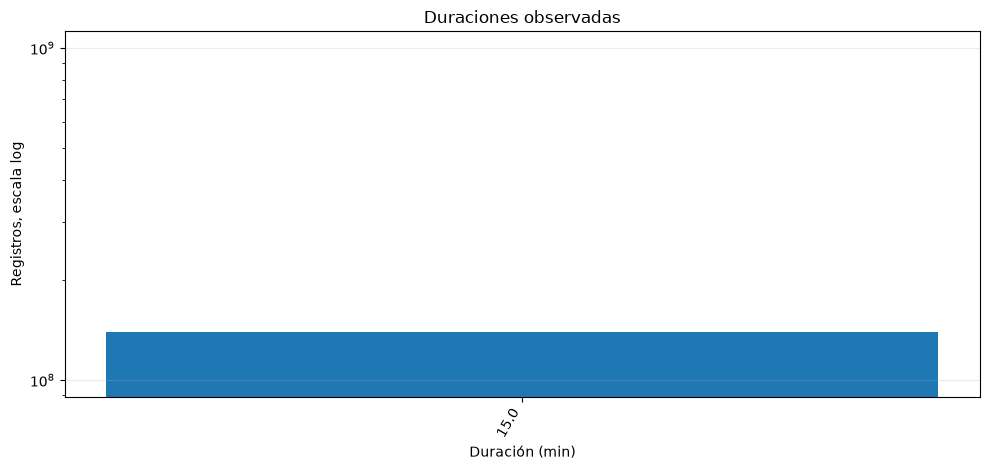

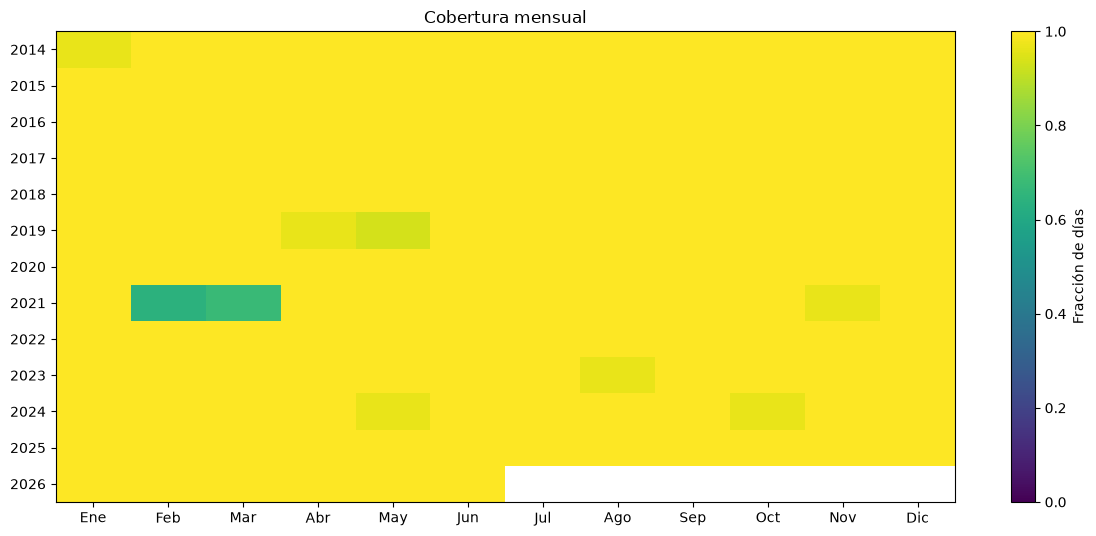

In [8]:
# La distribución de duraciones se construye desde el manifiesto generado
# durante la lectura por chunks; no requiere volver a escanear 28M de filas.
dur_counter = Counter()
for entry in source_manifest["sources"].values():
    for anio_txt, conteos in entry.get("duration_counts_by_year", {}).items():
        anio = int(anio_txt)
        if ANIO_MIN <= anio <= ANIO_MAX:
            for duracion, cantidad in conteos.items():
                dur_counter[float(duracion)] += int(cantidad)

if dur_counter:
    dur = pd.DataFrame(
        [
            {"duracion_min": k, "registros": v}
            for k, v in dur_counter.items()
        ]
    ).sort_values("registros", ascending=False).head(25)
else:
    # Fallback para una caché antigua sin conteos en el manifiesto.
    dur = con.sql("""
        SELECT ROUND(duracion_min,2) AS duracion_min, COUNT(*) AS registros
        FROM dedup
        WHERE duracion_min IS NOT NULL
        GROUP BY 1
        ORDER BY registros DESC
        LIMIT 25
    """).df()

display(dur)
plt.figure(figsize=(10, 4.8))
plt.bar(dur.duracion_min.astype(str), dur.registros)
plt.yscale("log")
plt.xlabel("Duración (min)")
plt.ylabel("Registros, escala log")
plt.title("Duraciones observadas")
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

mens = []
for r in audit_anios.itertuples(index=False):
    for mes in range(1, 13):
        a = pd.Timestamp(r.anio, mes, 1)
        b = a + pd.offsets.MonthEnd(0)
        ini = max(a, r.esperado_inicio)
        fin = min(b, r.esperado_fin)
        cov = (
            np.nan if ini > fin
            else obs.loc[
                (obs.anio == r.anio) & obs.fecha.between(ini, fin),
                "fecha",
            ].nunique() / ((fin - ini).days + 1)
        )
        mens.append({"anio": r.anio, "mes": mes, "cobertura": cov})

heat = pd.DataFrame(mens).pivot(index="anio", columns="mes", values="cobertura")
plt.figure(figsize=(12, max(4, .42 * len(heat))))
im = plt.imshow(heat, aspect="auto", vmin=0, vmax=1)
plt.colorbar(im, label="Fracción de días")
plt.yticks(range(len(heat)), heat.index)
plt.xticks(
    range(12),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"],
)
plt.title("Cobertura mensual")
plt.tight_layout()
plt.show()


In [9]:
# ============================================================
# Cobertura por estación y por molinete
# La cobertura se calcula por segmento para no exigir el mismo
# horario esperado a laborables, sábados y domingos/feriados.
# ============================================================
con.execute("""
CREATE OR REPLACE TABLE station_day AS
SELECT
    fecha, anio, tipo_dia, segmento_dia, periodo,
    linea, estacion, estacion_id,
    COUNT(DISTINCT slot_min) AS n_slots,
    SUM(pax_total) AS pax_total_dia
FROM station_slot_cal
GROUP BY ALL
""")

con.execute(f"""
CREATE OR REPLACE TABLE expected_slots AS
WITH d AS (
    SELECT anio, segmento_dia, COUNT(*) AS n_days
    FROM station_day
    GROUP BY ALL
),
p AS (
    SELECT anio, segmento_dia, slot_min, COUNT(*) AS n_slot
    FROM station_slot_cal
    GROUP BY ALL
)
SELECT
    p.anio, p.segmento_dia, p.slot_min,
    1.0 * p.n_slot / d.n_days AS fraccion
FROM p
JOIN d USING(anio, segmento_dia)
WHERE 1.0 * p.n_slot / d.n_days >= {PRESENCIA_SLOT_ESPERADO}
""")

con.execute("""
CREATE OR REPLACE TABLE station_day_cov AS
WITH en AS (
    SELECT anio, segmento_dia, COUNT(*) AS n_esperados
    FROM expected_slots
    GROUP BY ALL
),
ob AS (
    SELECT
        s.fecha, s.anio, s.tipo_dia, s.segmento_dia, s.periodo,
        s.linea, s.estacion, s.estacion_id,
        COUNT(e.slot_min) AS n_obs
    FROM station_slot_cal s
    LEFT JOIN expected_slots e
      ON s.anio=e.anio
     AND s.segmento_dia=e.segmento_dia
     AND s.slot_min=e.slot_min
    GROUP BY ALL
)
SELECT
    d.*, en.n_esperados, ob.n_obs,
    LEAST(1.0, 1.0 * ob.n_obs / NULLIF(en.n_esperados,0)) AS cobertura
FROM station_day d
JOIN en USING(anio, segmento_dia)
JOIN ob USING(
    fecha, anio, tipo_dia, segmento_dia, periodo,
    linea, estacion, estacion_id
)
""")

cov_est = con.sql("""
SELECT
    anio, segmento_dia, COUNT(*) AS station_days,
    MEDIAN(n_esperados) AS slots_esperados,
    MEDIAN(cobertura) AS cobertura_mediana,
    QUANTILE_CONT(cobertura,.10) AS cobertura_p10,
    100 * AVG(CASE WHEN cobertura < .8 THEN 1 ELSE 0 END) AS pct_menor_80
FROM station_day_cov
GROUP BY ALL
ORDER BY anio, segmento_dia
""").df()
display(cov_est)
cov_est.to_csv(OUTDIR / "cobertura_estacion_dia.csv", index=False)

# Días completos ausentes dentro del tramo activo de cada estación-año.
station_year_cov = con.sql("""
WITH sy AS (
    SELECT
        anio, estacion_id, MIN(fecha) AS fmin, MAX(fecha) AS fmax,
        COUNT(DISTINCT fecha) AS obs
    FROM station_day
    GROUP BY ALL
),
nd AS (
    SELECT DISTINCT anio, fecha FROM station_day
),
e AS (
    SELECT sy.anio, sy.estacion_id, sy.obs, COUNT(nd.fecha) AS esp
    FROM sy
    JOIN nd ON sy.anio=nd.anio AND nd.fecha BETWEEN sy.fmin AND sy.fmax
    GROUP BY ALL
)
SELECT *, 1.0 * obs / NULLIF(esp,0) AS cobertura
FROM e
""").df()

station_year_summary = station_year_cov.groupby("anio").agg(
    estaciones=("estacion_id", "size"),
    cobertura_mediana=("cobertura", "median"),
    cobertura_p10=("cobertura", lambda x: x.quantile(.1)),
    pct_menor_80=("cobertura", lambda x: 100 * (x < .8).mean()),
).reset_index()
display(station_year_summary)
station_year_cov.to_csv(OUTDIR / "cobertura_estacion_anio.csv", index=False)

# Auditoría de molinetes: es la consulta cruda más costosa que queda.
# Se ejecuta por año y se cachea.
MOL_AUDIT_DIR = CACHE / "auditoria_molinetes"
MOL_AUDIT_DIR.mkdir(parents=True, exist_ok=True)
cov_mol_rows = []

if AUDITAR_MOLINETES:
    for anio in anios:
        salida = MOL_AUDIT_DIR / f"cobertura_molinetes_{anio}.csv"
        meta_path = MOL_AUDIT_DIR / f"cobertura_molinetes_{anio}.meta.json"
        esperado = {
            "cache_version": CACHE_VERSION,
            "fingerprint": YEAR_FINGERPRINTS.get(anio, ""),
            "extras_clave": int(
                detalle_dup.loc[detalle_dup.anio == anio, "extras_clave"].iloc[0]
            ),
        }
        forzar = REPROCESAR_TODO or anio in ANIOS_CAMBIADOS or anio in REPROCESAR_ANIOS

        if not forzar and salida.exists() and meta_coincide(meta_path, esperado):
            fila = pd.read_csv(salida)
            print(f"Cobertura de molinetes {anio}: caché")
        else:
            fila = con.sql(f"""
                WITH md AS (
                    SELECT
                        CAST(anio AS INTEGER) AS anio,
                        fecha,
                        molinete_id,
                        COUNT(DISTINCT CAST(slot_min AS SMALLINT)) AS n
                    FROM dedup
                    WHERE CAST(anio AS INTEGER)={anio}
                      AND valido_15
                      AND pax_total >= 0
                    GROUP BY ALL
                ),
                e AS (
                    SELECT anio, QUANTILE_CONT(n,.95) AS esp
                    FROM md
                    GROUP BY anio
                )
                SELECT
                    md.anio,
                    COUNT(*) AS molinete_days,
                    e.esp AS slots_esperados,
                    MEDIAN(LEAST(1.0, md.n / NULLIF(e.esp,0))) AS cobertura_mediana,
                    QUANTILE_CONT(LEAST(1.0, md.n / NULLIF(e.esp,0)), .1)
                        AS cobertura_p10,
                    100 * AVG(CASE WHEN md.n < .8 * e.esp THEN 1 ELSE 0 END)
                        AS pct_menor_80
                FROM md
                JOIN e USING(anio)
                GROUP BY md.anio, e.esp
            """).df()
            fila.to_csv(salida, index=False)
            guardar_meta(meta_path, esperado)
            print(f"Cobertura de molinetes {anio}: calculada")
            gc.collect()

        cov_mol_rows.append(fila)

    cov_mol = pd.concat(cov_mol_rows, ignore_index=True).sort_values("anio")
    display(cov_mol)
    cov_mol.to_csv(OUTDIR / "cobertura_molinete_dia.csv", index=False)
else:
    cov_mol = pd.DataFrame()
    print("AUDITAR_MOLINETES=False: se omitió la cobertura a nivel molinete.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,segmento_dia,station_days,slots_esperados,cobertura_mediana,cobertura_p10,pct_menor_80
0,2014,Domingo/Feriado,5234,59.000,0.983,0.932,4.299
1,2014,Laborable,20183,71.000,1.000,0.901,0.763
2,2014,Sábado,4274,71.000,0.986,0.507,10.739
3,2015,Domingo/Feriado,5566,59.000,0.983,0.949,0.952
4,2015,Laborable,20230,72.000,0.986,0.917,1.162
5,2015,Sábado,4166,72.000,0.986,0.917,0.912
6,2016,Domingo/Feriado,5779,60.000,0.983,0.967,0.658
7,2016,Laborable,21025,72.000,1.000,0.972,1.346
8,2016,Sábado,4337,72.000,0.986,0.958,0.738
9,2017,Domingo/Feriado,5739,60.000,0.983,0.950,0.453


,anio,estaciones,cobertura_mediana,cobertura_p10,pct_menor_80
0,2014,83,0.997,0.937,0.000
1,2015,85,0.995,0.963,0.000
2,2016,86,1.000,0.990,0.000
3,2017,86,0.997,0.995,0.000
4,2018,87,0.989,0.989,1.149
5,2019,90,1.000,0.994,0.000
6,2020,89,0.964,0.257,41.573
7,2021,90,0.997,0.462,32.222
8,2022,90,1.000,1.000,0.000
9,2023,90,0.997,0.986,3.333


Cobertura de molinetes 2014: caché
Cobertura de molinetes 2015: caché
Cobertura de molinetes 2016: caché
Cobertura de molinetes 2017: caché
Cobertura de molinetes 2018: caché
Cobertura de molinetes 2019: caché
Cobertura de molinetes 2020: caché
Cobertura de molinetes 2021: caché
Cobertura de molinetes 2022: caché
Cobertura de molinetes 2023: caché
Cobertura de molinetes 2024: caché
Cobertura de molinetes 2025: caché
Cobertura de molinetes 2026: caché


,anio,molinete_days,slots_esperados,cobertura_mediana,cobertura_p10,pct_menor_80
0,2014,183893,72.000,0.889,0.514,28.493
1,2015,187763,71.000,0.901,0.507,28.028
2,2016,194634,72.000,0.917,0.500,28.612
3,2017,199065,72.000,0.931,0.542,27.995
4,2018,201750,72.000,0.944,0.486,32.088
5,2019,211741,73.000,0.932,0.452,31.969
6,2020,138704,72.000,0.667,0.069,63.941
7,2021,164367,69.000,0.812,0.159,49.134
8,2022,214228,73.000,0.890,0.315,37.688
9,2023,211052,73.000,0.904,0.315,36.878


In [10]:
peores = con.sql("""
SELECT
    fecha, anio, segmento_dia, linea, estacion, estacion_id,
    cobertura, n_esperados
FROM station_day_cov
WHERE cobertura < .8
ORDER BY cobertura, fecha
LIMIT 100
""").df()

exp = con.sql("""
SELECT anio, segmento_dia, slot_min
FROM expected_slots
ORDER BY anio, segmento_dia, slot_min
""").df()
expmap = {
    (int(a), segmento): set(g.slot_min.astype(int))
    for (a, segmento), g in exp.groupby(["anio", "segmento_dia"])
}

if not peores.empty:
    con.register("p_tmp", peores[["fecha", "estacion_id"]])
    ob = con.sql("""
        SELECT
            s.fecha, s.estacion_id,
            LIST(s.slot_min ORDER BY s.slot_min) AS slots
        FROM station_slot_cal s
        JOIN p_tmp p USING(fecha, estacion_id)
        GROUP BY ALL
    """).df()
    con.unregister("p_tmp")
    peores = peores.merge(ob, on=["fecha", "estacion_id"], how="left")

    def _slots_set(x):
        if x is None or (isinstance(x, float) and np.isnan(x)):
            return set()
        return set(np.asarray(x, dtype=int).tolist())

    peores["horas_faltantes"] = peores.apply(
        lambda r: ", ".join(
            f"{x//60:02d}:{x%60:02d}"
            for x in sorted(
                expmap.get((int(r.anio), r.segmento_dia), set())
                - _slots_set(r.slots)
            )[:30]
        ),
        axis=1,
    )
    muestra_faltantes = peores.drop(columns="slots")
else:
    muestra_faltantes = peores

muestra_faltantes.to_csv(
    OUTDIR / "intervalos_faltantes_muestra.csv",
    index=False,
)
display(muestra_faltantes.head(30))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,fecha,anio,segmento_dia,linea,estacion,estacion_id,cobertura,n_esperados,horas_faltantes
0,2014-01-11,2014,Sábado,D,PUEYRREDON,D | PUEYRREDON,0.000,71,"05:00, 05:15, 05:30, 05:45, 06:00, 06:15, 06:3..."
1,2014-04-10,2014,Laborable,E,SAN JOSE,E | SAN JOSE,0.000,71,"05:00, 05:15, 05:30, 05:45, 06:00, 06:15, 06:3..."
2,2014-04-10,2014,Laborable,B,FEDERICO LACROZE,B | FEDERICO LACROZE,0.000,71,"05:00, 05:15, 05:30, 05:45, 06:00, 06:15, 06:3..."
3,2014-05-18,2014,Domingo/Feriado,B,FLORIDA,B | FLORIDA,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."
4,2014-05-25,2014,Domingo/Feriado,B,MALABIA,B | MALABIA,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."
5,2014-05-25,2014,Domingo/Feriado,B,MEDRANO,B | MEDRANO,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."
6,2014-05-25,2014,Domingo/Feriado,B,LEANDRO N. ALEM,B | LEANDRO N. ALEM,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."
7,2014-05-25,2014,Domingo/Feriado,B,ANGEL GALLARDO,B | ANGEL GALLARDO,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."
8,2014-05-25,2014,Domingo/Feriado,B,FLORIDA,B | FLORIDA,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."
9,2014-05-25,2014,Domingo/Feriado,B,PUEYRREDON,B | PUEYRREDON,0.000,59,"07:45, 08:00, 08:15, 08:30, 08:45, 09:00, 09:1..."


## 4. Evolución general de la demanda

Los totales se acompañan con cobertura. Una caída con cobertura baja puede ser un problema de datos; con cobertura alta, un fenómeno real potencial.

In [11]:
from IPython.display import HTML

In [12]:
import plotly.graph_objects as go

# Umbral para resaltar únicamente alertas de cobertura relativa severamente baja.
UMBRAL_ALERTA_COBERTURA_RED = 0.40

diaria=con.sql('''SELECT fecha,anio,MAX(periodo) periodo,SUM(pax_total) pax_total,COUNT(DISTINCT estacion_id) estaciones_activas,COUNT(*) station_slots FROM station_slot_cal GROUP BY fecha,anio ORDER BY fecha''').df(); diaria.fecha=pd.to_datetime(diaria.fecha)
diaria["est_ref"]=diaria.groupby("anio").estaciones_activas.transform(lambda x:x.quantile(.95)); diaria["slots_ref"]=diaria.groupby("anio").station_slots.transform(lambda x:x.quantile(.95))
diaria["cobertura_red"]=np.minimum(diaria.estaciones_activas/diaria.est_ref,diaria.station_slots/diaria.slots_ref).clip(upper=1)
diaria["mediana_28d"]=diaria.set_index("fecha").pax_total.rolling("28D",min_periods=7).median().to_numpy(); diaria.to_csv(OUTDIR/"serie_diaria_red.csv",index=False)

b=diaria.cobertura_red < UMBRAL_ALERTA_COBERTURA_RED
fig_demanda=go.Figure()
fig_demanda.add_trace(go.Scatter(
    x=diaria.fecha, y=diaria.pax_total, mode='lines', name='Total diario',
    line=dict(color='rgba(93, 160, 210, .30)', width=1),
    hovertemplate='Fecha: %{x|%d/%m/%Y}<br>Total diario: %{y:,.0f}<extra></extra>'
))
fig_demanda.add_trace(go.Scatter(
    x=diaria.fecha, y=diaria.mediana_28d, mode='lines', name='Mediana móvil 28d',
    line=dict(color='#ff7f0e', width=2.5),
    hovertemplate='Fecha: %{x|%d/%m/%Y}<br>Mediana móvil: %{y:,.0f}<extra></extra>'
))
fig_demanda.add_trace(go.Scatter(
    x=diaria.loc[b,'fecha'], y=diaria.loc[b,'pax_total'], mode='markers',
    name=f'Cobertura relativa <{UMBRAL_ALERTA_COBERTURA_RED:.0%}', marker=dict(symbol='x', color='#1f77b4', size=7),
    customdata=diaria.loc[b,['cobertura_red','estaciones_activas','station_slots']].to_numpy(),
    hovertemplate=('Fecha: %{x|%d/%m/%Y}<br>Total registrado: %{y:,.0f}'
        '<br>Cobertura relativa: %{customdata[0]:.1%}'
        '<br>Estaciones activas: %{customdata[1]:.0f}'
        '<br>Station-slots registrados: %{customdata[2]:,.0f}<extra></extra>')
))
fig_demanda.add_vrect(x0='2020-03-01', x1='2021-12-31', fillcolor='#7aa6c2', opacity=.14, line_width=0, annotation_text='Pandemia', annotation_position='top left')
fig_demanda.update_layout(
    title='Demanda diaria y cobertura', template='plotly_white', height=560,
    xaxis=dict(title='Fecha', rangeslider=dict(visible=True),
        rangeselector=dict(buttons=[
            dict(count=1, label='1 año', step='year', stepmode='backward'),
            dict(count=3, label='3 años', step='year', stepmode='backward'),
            dict(step='all', label='Todo'),
        ])),
    yaxis_title='Pasajeros', hovermode='x unified', dragmode='zoom',
    legend=dict(orientation='h', y=1.02, x=0), margin=dict(l=65, r=25, t=90, b=55),
)
fig_demanda.show(config={'scrollZoom': True, 'displaylogo': False})
display(HTML('<span style="font-size:13px;color:#52616b">Arrastrá sobre el gráfico para seleccionar un intervalo y hacer zoom; usá la rueda del mouse para acercar/alejar. Doble clic para volver a la vista completa.</span>'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

## 5. Matriz funcional segmentada

La unidad de análisis es:

> **línea–estación × año × segmento de día**

Se usan tres segmentos:

- **Laborable**: lunes a viernes, excluyendo feriados.
- **Sábado**.
- **Domingo/Feriado**: se combinan para conservar una cantidad razonable de días por curva.

Para cada estación y slot se usa la **mediana** entre días válidos, no la media. Esto reduce la influencia de eventos excepcionales y días anómalos. Luego se separan:

- **forma**: porcentaje de la demanda diaria en cada slot;
- **amplitud**: volumen diario mediano.

Los años parciales se conservan para ser proyectados, pero se excluyen por defecto de los gráficos de evolución anual.

In [13]:
# Cobertura temporal del año a nivel de red.
year_info = con.sql("""
SELECT
    anio,
    MIN(fecha) AS fecha_min,
    MAX(fecha) AS fecha_max,
    COUNT(DISTINCT fecha) AS dias_red
FROM station_slot
GROUP BY anio
ORDER BY anio
""").df()
year_info["fecha_min"] = pd.to_datetime(year_info["fecha_min"])
year_info["fecha_max"] = pd.to_datetime(year_info["fecha_max"])
year_info["anio_parcial"] = (
    (year_info["fecha_max"].dt.month < 12)
    | (year_info["dias_red"] < 300)
)
year_info.to_csv(OUTDIR / "cobertura_temporal_anios.csv", index=False)
display(year_info)

# Perfil robusto por estación-año-segmento.
points = con.sql(f"""
SELECT
    s.estacion_id,
    s.linea,
    s.estacion,
    s.anio,
    s.segmento_dia,
    s.periodo,
    s.slot_min,
    MEDIAN(s.pax_total) AS pax_slot
FROM station_slot_cal s
JOIN station_day_cov d
  ON s.fecha=d.fecha
 AND s.estacion_id=d.estacion_id
WHERE d.cobertura >= {UMBRAL_COBERTURA_DIA}
GROUP BY ALL
ORDER BY estacion_id, anio, segmento_dia, slot_min
""").df()

meta0 = con.sql(f"""
SELECT
    estacion_id,
    MAX(linea) AS linea,
    MAX(estacion) AS estacion,
    anio,
    segmento_dia,
    MAX(tipo_dia) AS tipo_dia,
    MAX(periodo) AS periodo,
    COUNT(*) AS n_dias,
    AVG(pax_total_dia) AS pax_diarios_media,
    MEDIAN(pax_total_dia) AS pax_diarios_mediana,
    AVG(cobertura) AS cobertura_dia_media
FROM station_day_cov
WHERE cobertura >= {UMBRAL_COBERTURA_DIA}
GROUP BY estacion_id, anio, segmento_dia
ORDER BY estacion_id, anio, segmento_dia
""").df()

meta0["min_dias_requeridos"] = meta0["segmento_dia"].map(
    MIN_DIAS_SEGMENTO
).fillna(18).astype(int)
meta0 = meta0[
    meta0["n_dias"] >= meta0["min_dias_requeridos"]
].copy()

if meta0.empty:
    raise RuntimeError(
        "No hay curvas suficientes; revise cobertura y MIN_DIAS_SEGMENTO."
    )

meta0["curve_id"] = (
    meta0["estacion_id"].astype(str)
    + " | " + meta0["anio"].astype(str)
    + " | " + meta0["segmento_dia"].astype(str)
)
points["curve_id"] = (
    points["estacion_id"].astype(str)
    + " | " + points["anio"].astype(str)
    + " | " + points["segmento_dia"].astype(str)
)
points = points[points["curve_id"].isin(meta0["curve_id"])]

GRID_MIN = np.arange(0, 1440, INTERVALO_MIN, dtype=int)
GRID_H = GRID_MIN / 60

piv = (
    points.pivot_table(
        index="curve_id",
        columns="slot_min",
        values="pax_slot",
        aggfunc="median",
    )
    .reindex(columns=GRID_MIN)
)
meta = meta0.set_index("curve_id").loc[piv.index].copy()

exp_seg = con.sql("""
SELECT anio, segmento_dia, slot_min
FROM expected_slots
ORDER BY anio, segmento_dia, slot_min
""").df()
expmap_segmento = {
    (int(a), segmento): sorted(g.slot_min.astype(int).tolist())
    for (a, segmento), g in exp_seg.groupby(["anio", "segmento_dia"])
}

rows = []
cobertura_curva = []
ids = []

for cid, fila in piv.iterrows():
    m = meta.loc[cid]
    activos = [
        x for x in expmap_segmento.get(
            (int(m.anio), m.segmento_dia),
            GRID_MIN.tolist(),
        )
        if x in piv.columns
    ]
    if not activos:
        continue

    s = fila.loc[activos]
    cobertura = float(s.notna().mean())
    if cobertura < UMBRAL_COBERTURA_CURVA:
        continue

    s = s.interpolate(method="linear", limit_area="inside")
    if s.isna().any():
        continue

    # Fuera del horario esperado la demanda se interpreta como cero.
    full = pd.Series(0.0, index=GRID_MIN)
    full.loc[activos] = s.to_numpy(float)
    rows.append(full.to_numpy())
    cobertura_curva.append(cobertura)
    ids.append(cid)

Xvol = np.asarray(rows, dtype=float)
meta = meta.loc[ids].copy()
meta["cobertura_curva"] = cobertura_curva

amp = Xvol.sum(axis=1)
ok = np.isfinite(amp) & (amp > 0)
Xvol = Xvol[ok]
meta = meta.iloc[np.flatnonzero(ok)].copy()
amp = amp[ok]

Xforma = 100 * Xvol / amp[:, None]
meta["amplitud_suma_slots"] = amp
meta["curve_id"] = meta.index

info_anio = year_info.set_index("anio")
meta["anio_parcial"] = (
    meta["anio"].map(info_anio["anio_parcial"]).fillna(True).astype(bool)
)
meta["fecha_max_anio"] = meta["anio"].map(info_anio["fecha_max"])
meta["indice_global"] = np.arange(len(meta))

if len(Xforma) < 12:
    raise RuntimeError("Se necesitan más curvas válidas para el análisis segmentado.")

print("Matriz funcional:", Xforma.shape)
display(
    meta.groupby("segmento_dia")
    .agg(
        curvas=("curve_id", "size"),
        estaciones=("estacion_id", "nunique"),
        anios=("anio", "nunique"),
        dias_medianos=("n_dias", "median"),
    )
    .reindex(SEGMENTOS_DIA)
)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,fecha_min,fecha_max,dias_red,anio_parcial
0,2014,2014-01-02,2014-12-31,364,False
1,2015,2015-01-01,2015-12-31,365,False
2,2016,2016-01-01,2016-12-31,366,False
3,2017,2017-01-01,2017-12-31,365,False
4,2018,2018-01-01,2018-12-31,365,False
5,2019,2019-01-01,2019-12-31,362,False
6,2020,2020-01-01,2020-12-31,366,False
7,2021,2021-01-01,2021-12-31,344,False
8,2022,2022-01-01,2022-12-31,365,False
9,2023,2023-01-01,2023-12-31,364,False


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Matriz funcional: (3270, 96)


,curvas,estaciones,anios,dias_medianos
segmento_dia,,,,
Laborable,1105,90,13,242.000
Sábado,1065,90,13,48.000
Domingo/Feriado,1100,90,13,67.000


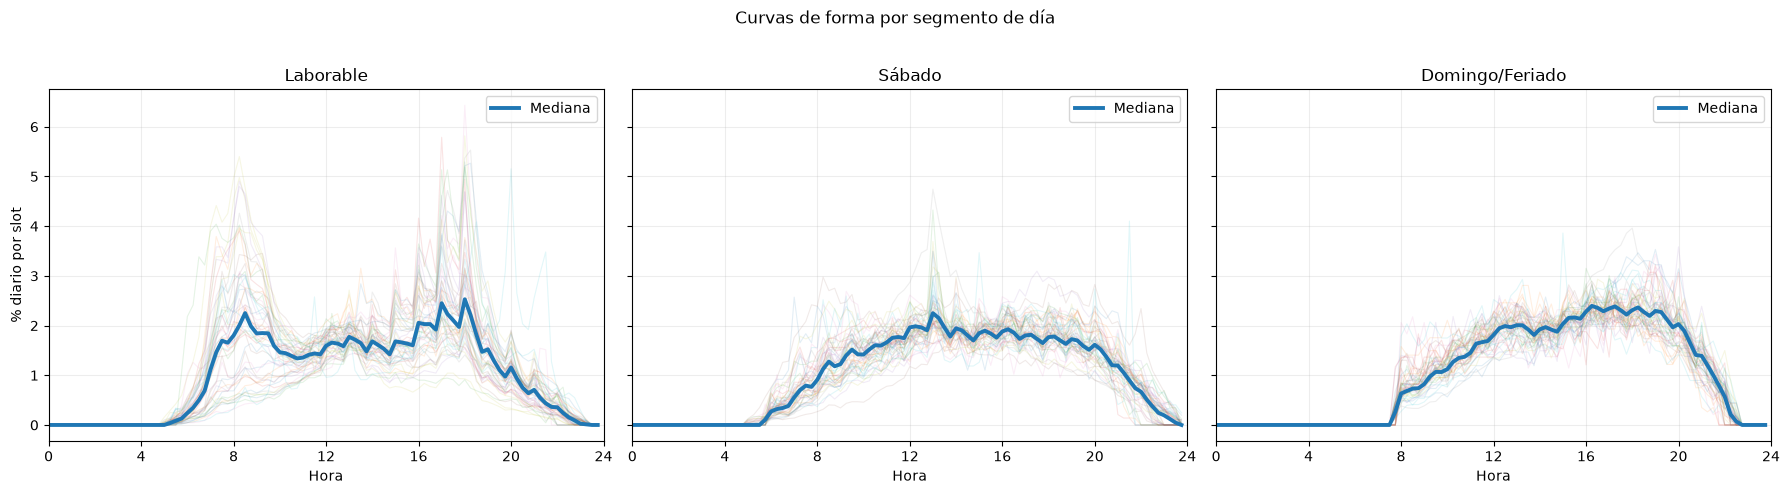

In [14]:
# Muestra de curvas antes de suavizar, separadas desde el comienzo.
rng = np.random.default_rng(SEED)
segmentos_presentes = [
    s for s in SEGMENTOS_DIA
    if s in set(meta["segmento_dia"])
]

fig, axes = plt.subplots(
    1,
    len(segmentos_presentes),
    figsize=(6 * len(segmentos_presentes), 4.8),
    sharex=True,
    sharey=True,
)
axes = np.atleast_1d(axes)

for ax, segmento in zip(axes, segmentos_presentes):
    idx = np.flatnonzero(meta["segmento_dia"].eq(segmento).to_numpy())
    sel = rng.choice(idx, min(50, len(idx)), replace=False)
    for i in sel:
        ax.plot(GRID_H, Xforma[i], alpha=.12, lw=.8)
    ax.plot(
        GRID_H,
        np.median(Xforma[idx], axis=0),
        lw=2.8,
        label="Mediana",
    )
    ax.set_title(segmento)
    ax.set_xlabel("Hora")
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 4))
    ax.grid(alpha=.22)
    ax.legend()

axes[0].set_ylabel("% diario por slot")
fig.suptitle("Curvas de forma por segmento de día", y=1.02)
plt.tight_layout()
plt.show()

## 6. FPCA y clustering dentro de cada segmento

Se ajusta un modelo independiente para cada segmento. En cada caso:

1. se suavizan las curvas con una base B-spline;
2. se estima la FPCA usando años completos y no pandémicos como referencia;
3. se proyectan todas las curvas, incluidas 2020–2021 y años parciales;
4. se selecciona `k` considerando silhouette, estabilidad entre inicializaciones y tamaño mínimo de cluster;
5. se asignan etiquetas ordenadas por el horario del pico del perfil mediano.

Las coordenadas FPC son comparables entre años **dentro de un mismo segmento**, pero no deben compararse numéricamente entre segmentos distintos.

In [15]:
# Base de suavizado común; los modelos estadísticos son independientes por segmento.
nk = int(min(max(6, N_KNOTS), max(6, len(GRID_H) // 2)))
trans = SplineTransformer(
    n_knots=nk,
    degree=3,
    include_bias=True,
    knots="uniform",
)
B = trans.fit_transform(GRID_H.reshape(-1, 1))
D2 = np.diff(np.eye(B.shape[1]), n=2, axis=0)
P = D2.T @ D2
BtB = B.T @ B
I_basis = np.eye(B.shape[1])

peso_slot = INTERVALO_MIN / 60
rw = np.sqrt(np.full(len(GRID_H), peso_slot))


def _seleccionar_k(Xref):
    """Selecciona k evitando soluciones inestables o clusters diminutos."""
    filas = []
    k_lim = min(K_MAX, len(Xref) - 1)
    if k_lim < 2:
        raise RuntimeError("No hay suficientes perfiles de referencia para clustering.")

    for k in range(2, k_lim + 1):
        labs = []
        sils = []
        inercias = []
        min_props = []

        for rep in range(REPETICIONES_K):
            km = KMeans(
                n_clusters=k,
                n_init=20,
                random_state=SEED + rep,
            )
            lab = km.fit_predict(Xref)
            labs.append(lab)
            sils.append(silhouette_score(Xref, lab))
            inercias.append(km.inertia_)
            min_props.append(np.bincount(lab, minlength=k).min() / len(lab))

        ari = [
            adjusted_rand_score(labs[i], labs[j])
            for i, j in combinations(range(len(labs)), 2)
        ]
        filas.append({
            "k": k,
            "silhouette_media": float(np.mean(sils)),
            "silhouette_sd": float(np.std(sils)),
            "ari_estabilidad": float(np.mean(ari)),
            "inercia": float(np.mean(inercias)),
            "min_prop_cluster": float(np.mean(min_props)),
        })

    tabla = pd.DataFrame(filas)
    candidatos = tabla[tabla["min_prop_cluster"] >= MIN_PROP_CLUSTER].copy()
    if candidatos.empty:
        candidatos = tabla.copy()

    estables = candidatos[candidatos["ari_estabilidad"] >= .75]
    if not estables.empty:
        candidatos = estables

    mejor_sil = candidatos["silhouette_media"].max()
    # Si varias opciones son prácticamente equivalentes, se prefiere la más simple.
    cercanos = candidatos[
        candidatos["silhouette_media"] >= mejor_sil - .02
    ]
    kopt = int(cercanos.sort_values("k").iloc[0]["k"])
    return kopt, tabla


def ajustar_modelo_segmento(segmento, indices_globales):
    X = Xforma[indices_globales]
    m = meta.iloc[indices_globales].reset_index(drop=True).copy()

    # Selección de suavizado por GCV dentro del segmento.
    registros_gcv = []
    mejor = None
    for lam in np.logspace(-6, 4, 31):
        H = B @ np.linalg.solve(BtB + lam * P + 1e-10 * I_basis, B.T)
        yh = X @ H.T
        mse = float(np.mean((X - yh) ** 2))
        df = float(np.trace(H))
        gcv = mse / max(1e-8, (1 - df / B.shape[0]) ** 2)
        registros_gcv.append({
            "segmento_dia": segmento,
            "lambda": lam,
            "gcv": gcv,
            "df": df,
            "mse": mse,
        })
        if mejor is None or gcv < mejor[0]:
            mejor = (gcv, lam, yh)

    Xsmooth = np.clip(mejor[2], 0, None)
    Xsmooth = 100 * Xsmooth / Xsmooth.sum(axis=1, keepdims=True)

    # Referencia: años completos, excluyendo la pandemia.
    ref = (
        ~m["anio_parcial"]
        & ~m["anio"].isin(ANIOS_EXCLUIR_REFERENCIA)
    ).to_numpy()

    minimo_ref = max(12, 3 * 2)
    referencia_usada = "años completos no pandémicos"
    if ref.sum() < minimo_ref:
        ref = (~m["anio_parcial"]).to_numpy()
        referencia_usada = "años completos"
    if ref.sum() < minimo_ref:
        ref = np.ones(len(m), dtype=bool)
        referencia_usada = "todas las curvas"

    Xref = Xsmooth[ref]
    media = Xref.mean(axis=0)
    Aref = (Xref - media) * rw
    U, S, Vt = np.linalg.svd(Aref, full_matrices=False)
    mc = min(len(Xref) - 1, Xref.shape[1])
    U, S, Vt = U[:, :mc], S[:mc], Vt[:mc]

    total_ss = float(np.sum(S ** 2))
    if not np.isfinite(total_ss) or total_ss <= 1e-14:
        raise RuntimeError(f"{segmento}: variación insuficiente para FPCA.")

    var = S ** 2 / total_ss
    cum = np.cumsum(var)
    funciones = Vt / rw
    scores_all = ((Xsmooth - media) * rw) @ Vt.T

    # Orientación reproducible de cada componente.
    for j in range(len(funciones)):
        pmax = np.argmax(np.abs(funciones[j]))
        if funciones[j, pmax] < 0:
            funciones[j] *= -1
            scores_all[:, j] *= -1

    r_var = int(np.searchsorted(cum, VAR_OBJETIVO) + 1)
    r_var = min(max(1, r_var), mc)
    r_cluster = min(max(1, r_var), 10, scores_all.shape[1])

    Xcl_all = scores_all[:, :r_cluster]
    Xcl_ref = Xcl_all[ref]
    kopt, metricas_k = _seleccionar_k(Xcl_ref)

    km = KMeans(
        n_clusters=kopt,
        n_init=50,
        random_state=SEED,
    )
    lab_ref_original = km.fit_predict(Xcl_ref)
    lab_all_original = km.predict(Xcl_all)

    # Etiquetas consistentes: C1 es el cluster con pico más temprano.
    picos = {}
    for c in np.unique(lab_ref_original):
        curva_mediana = np.median(
            Xref[lab_ref_original == c],
            axis=0,
        )
        picos[c] = int(GRID_MIN[np.argmax(curva_mediana)])
    mapa = {
        old: i + 1
        for i, old in enumerate(sorted(picos, key=picos.get))
    }
    labels = np.array([mapa[x] for x in lab_all_original], dtype=int)

    distancia = np.linalg.norm(
        Xcl_all - km.cluster_centers_[lab_all_original],
        axis=1,
    )
    sil_individual = silhouette_samples(Xcl_all, lab_all_original)

    abreviatura = {
        "Laborable": "LAB",
        "Sábado": "SAB",
        "Domingo/Feriado": "DOM",
    }.get(segmento, "SEG")

    df_scores = m.copy()
    df_scores["referencia_modelo"] = ref
    df_scores["cluster"] = labels
    df_scores["cluster_id"] = [f"{abreviatura}-C{x}" for x in labels]
    df_scores["distancia_centroide"] = distancia
    df_scores["silhouette_individual"] = sil_individual
    df_scores["lambda_suavizado"] = float(mejor[1])

    for j in range(min(10, scores_all.shape[1])):
        df_scores[f"FPC{j+1}"] = scores_all[:, j]

    slot_cols = [f"slot_{m:04d}" for m in GRID_MIN]
    df_perfiles = pd.DataFrame(Xsmooth, columns=slot_cols)
    meta_export = df_scores[[
        "curve_id", "estacion_id", "linea", "estacion", "anio",
        "segmento_dia", "tipo_dia", "periodo", "n_dias",
        "pax_diarios_media", "pax_diarios_mediana",
        "cobertura_curva", "anio_parcial", "referencia_modelo",
        "cluster", "cluster_id", "distancia_centroide",
    ]].reset_index(drop=True)
    df_perfiles = pd.concat([meta_export, df_perfiles], axis=1)

    var_df = pd.DataFrame({
        "segmento_dia": segmento,
        "componente": np.arange(1, len(var) + 1),
        "varianza": var,
        "acumulada": cum,
    })
    metricas_k.insert(0, "segmento_dia", segmento)

    resumen = {
        "segmento_dia": segmento,
        "curvas": len(m),
        "curvas_referencia": int(ref.sum()),
        "referencia_usada": referencia_usada,
        "lambda": float(mejor[1]),
        "componentes_90": r_var,
        "componentes_cluster": r_cluster,
        "k": kopt,
        "silhouette": float(
            metricas_k.loc[
                metricas_k["k"] == kopt,
                "silhouette_media",
            ].iloc[0]
        ),
        "ari_estabilidad": float(
            metricas_k.loc[
                metricas_k["k"] == kopt,
                "ari_estabilidad",
            ].iloc[0]
        ),
    }

    modelo = {
        "segmento": segmento,
        "indices_globales": indices_globales,
        "Xsmooth": Xsmooth,
        "media": media,
        "funciones": funciones,
        "varianza": var,
        "acumulada": cum,
        "scores": scores_all,
        "ref": ref,
        "r_var": r_var,
        "r_cluster": r_cluster,
        "k": kopt,
        "labels": labels,
    }
    return (
        modelo,
        df_scores,
        df_perfiles,
        metricas_k,
        var_df,
        pd.DataFrame(registros_gcv),
        resumen,
    )


slot_cols = [f"slot_{m:04d}" for m in GRID_MIN]

modelos_segmento = {}
scores_frames = []
perfiles_frames = []
metricas_frames = []
varianza_frames = []
gcv_frames = []
resumen_modelos_rows = []

for segmento in SEGMENTOS_DIA:
    indices = np.flatnonzero(meta["segmento_dia"].eq(segmento).to_numpy())
    if len(indices) < 12:
        print(f"{segmento}: omitido; solo hay {len(indices)} curvas.")
        continue

    resultado = ajustar_modelo_segmento(segmento, indices)
    modelo, sc, pf, mk, vv, gg, rr = resultado
    modelos_segmento[segmento] = modelo
    scores_frames.append(sc)
    perfiles_frames.append(pf)
    metricas_frames.append(mk)
    varianza_frames.append(vv)
    gcv_frames.append(gg)
    resumen_modelos_rows.append(rr)

if not scores_frames:
    raise RuntimeError("No pudo ajustarse ningún modelo segmentado.")

scores_df = pd.concat(scores_frames, ignore_index=True)
perfiles_df = pd.concat(perfiles_frames, ignore_index=True)
metricas_segmentos = pd.concat(metricas_frames, ignore_index=True)
varianza_segmentos = pd.concat(varianza_frames, ignore_index=True)
gcv_segmentos = pd.concat(gcv_frames, ignore_index=True)
resumen_modelos = pd.DataFrame(resumen_modelos_rows)

scores_df = scores_df.sort_values(
    ["segmento_dia", "estacion_id", "anio"]
).reset_index(drop=True)
perfiles_df = perfiles_df.sort_values(
    ["segmento_dia", "estacion_id", "anio"]
).reset_index(drop=True)

display(resumen_modelos)

,segmento_dia,curvas,curvas_referencia,referencia_usada,lambda,componentes_90,componentes_cluster,k,silhouette,ari_estabilidad
0,Laborable,1105,874,años completos no pandémicos,0.010,2,2,2,0.529,1.000
1,Sábado,1065,868,años completos no pandémicos,0.046,3,3,3,0.381,0.996
2,Domingo/Feriado,1100,875,años completos no pandémicos,0.022,3,3,2,0.514,0.998


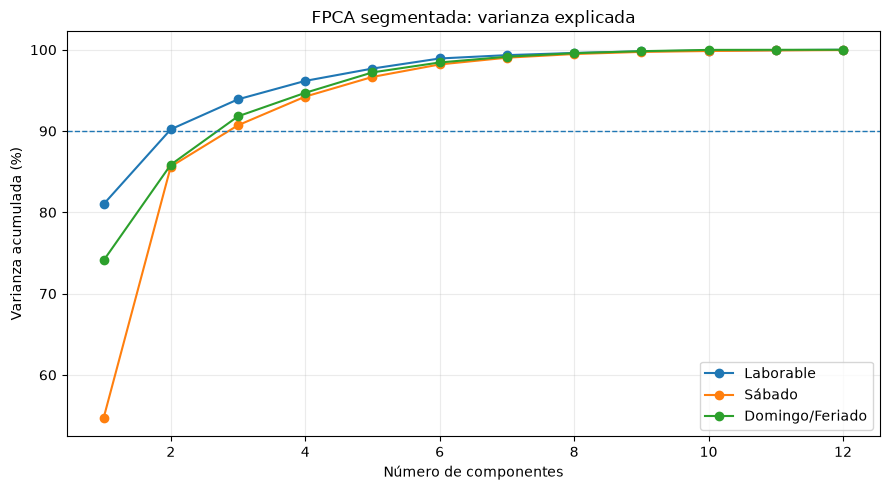

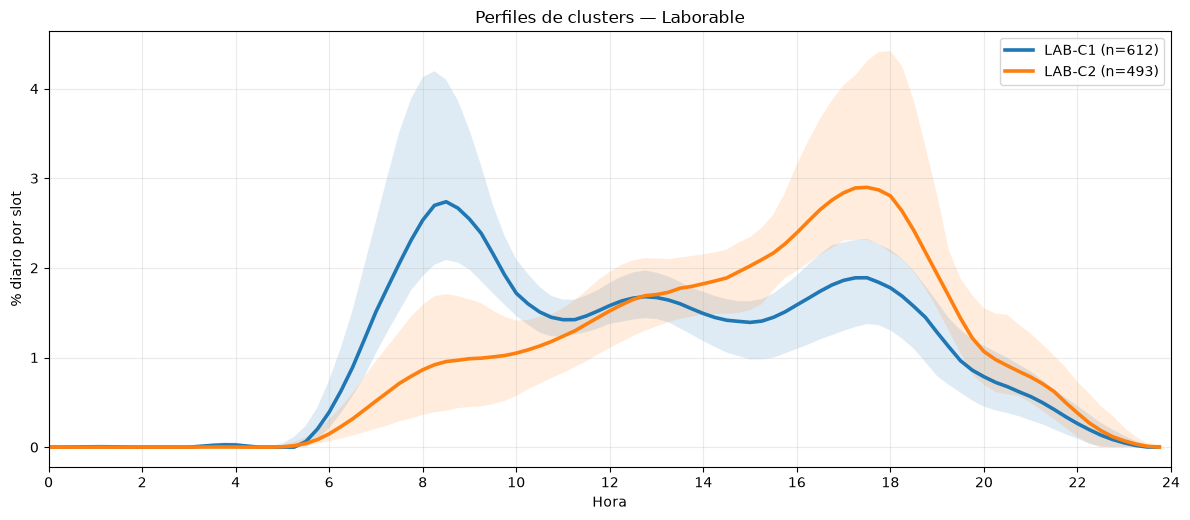

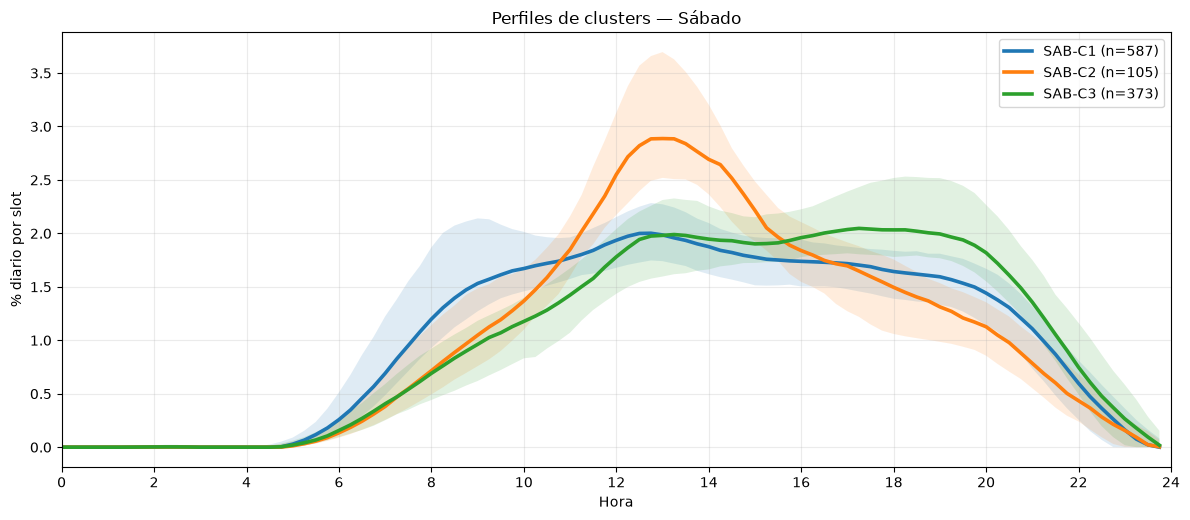

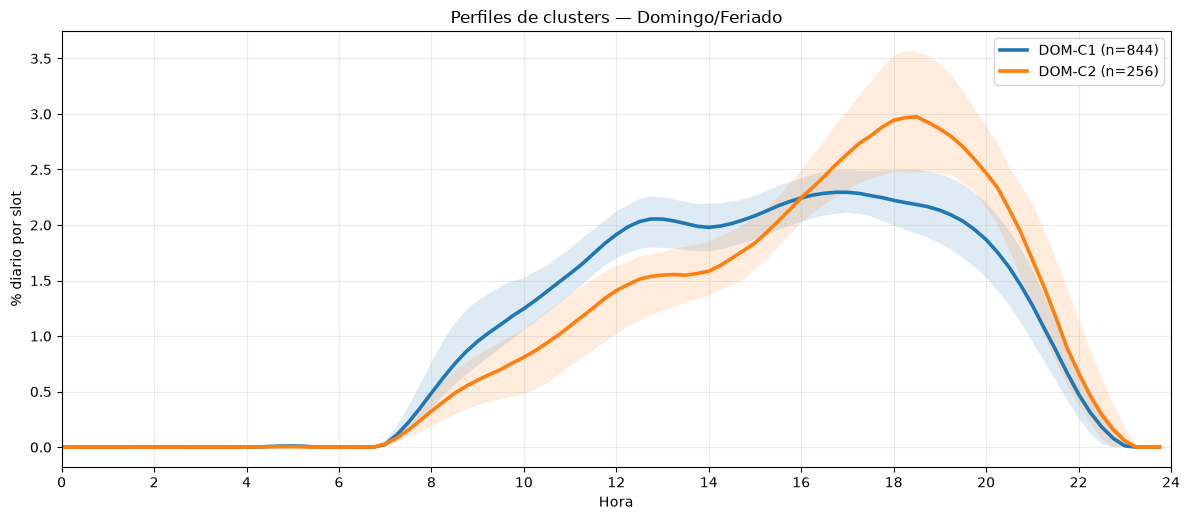

In [16]:
# Varianza acumulada por segmento.
plt.figure(figsize=(9, 5))
for segmento, g in varianza_segmentos.groupby("segmento_dia", sort=False):
    g = g.head(12)
    plt.plot(
        g["componente"],
        100 * g["acumulada"],
        marker="o",
        label=segmento,
    )
plt.axhline(100 * VAR_OBJETIVO, ls="--", lw=1)
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada (%)")
plt.title("FPCA segmentada: varianza explicada")
plt.grid(alpha=.25)
plt.legend()
plt.tight_layout()
plt.show()

# Curvas y espacio de scores, por separado.
slot_cols = [f"slot_{m:04d}" for m in GRID_MIN]

for segmento in SEGMENTOS_DIA:
    if segmento not in modelos_segmento:
        continue

    sc = scores_df[scores_df["segmento_dia"] == segmento].copy()
    pf = perfiles_df[perfiles_df["segmento_dia"] == segmento].copy()

    plt.figure(figsize=(12, 5.3))
    for cluster_id in sorted(pf["cluster_id"].unique()):
        arr = pf.loc[pf["cluster_id"] == cluster_id, slot_cols].to_numpy(float)
        q10, med, q90 = np.quantile(arr, [.10, .50, .90], axis=0)
        plt.plot(
            GRID_H,
            med,
            lw=2.6,
            label=f"{cluster_id} (n={len(arr)})",
        )
        plt.fill_between(GRID_H, q10, q90, alpha=.14)

    plt.xlabel("Hora")
    plt.ylabel("% diario por slot")
    plt.title(f"Perfiles de clusters — {segmento}")
    plt.xlim(0, 24)
    plt.xticks(range(0, 25, 2))
    plt.grid(alpha=.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    y = "FPC2" if "FPC2" in sc.columns else "distancia_centroide"
    fig = px.scatter(
        sc,
        x="FPC1",
        y=y,
        color="cluster_id",
        symbol="periodo",
        hover_name="estacion_id",
        hover_data=[
            "anio", "n_dias", "pax_diarios_mediana",
            "anio_parcial", "referencia_modelo", "distancia_centroide",
        ],
        title=f"Espacio funcional segmentado — {segmento}",
    )
    fig.update_traces(marker={"size": 7, "opacity": .72})
    fig.show()

In [17]:
# Caracterización numérica de los clusters.
resumen_clusters_rows = []

for segmento in SEGMENTOS_DIA:
    pf = perfiles_df[perfiles_df["segmento_dia"] == segmento]
    sc = scores_df[scores_df["segmento_dia"] == segmento]
    if pf.empty:
        continue

    for cluster_id, g in pf.groupby("cluster_id", sort=True):
        arr = g[slot_cols].to_numpy(float)
        med = np.median(arr, axis=0)
        pico_idx = int(np.argmax(med))

        def share(h0, h1):
            mask = (GRID_H >= h0) & (GRID_H < h1)
            return float(med[mask].sum() / med.sum())

        scg = sc[sc["cluster_id"] == cluster_id]
        resumen_clusters_rows.append({
            "segmento_dia": segmento,
            "cluster_id": cluster_id,
            "perfiles": len(g),
            "estaciones": g["estacion_id"].nunique(),
            "pico": f"{GRID_MIN[pico_idx]//60:02d}:{GRID_MIN[pico_idx]%60:02d}",
            "share_06_10": share(6, 10),
            "share_10_16": share(10, 16),
            "share_16_21": share(16, 21),
            "share_21_24": share(21, 24),
            "balance_manana_tarde": share(6, 10) - share(16, 21),
            "pax_diarios_mediana": scg["pax_diarios_mediana"].median(),
            "silhouette_mediana": scg["silhouette_individual"].median(),
        })

resumen_clusters = pd.DataFrame(resumen_clusters_rows)
display(resumen_clusters)

,segmento_dia,cluster_id,perfiles,estaciones,pico,share_06_10,share_10_16,share_16_21,share_21_24,balance_manana_tarde,pax_diarios_mediana,silhouette_mediana
0,Laborable,LAB-C1,612,56,08:30,0.311,0.375,0.284,0.026,0.027,"7,998.500",0.598
1,Laborable,LAB-C2,493,53,17:30,0.119,0.407,0.434,0.038,-0.316,"7,996.500",0.591
2,Sábado,SAB-C1,587,69,12:45,0.171,0.447,0.321,0.057,-0.150,"2,691.500",0.405
3,Sábado,SAB-C2,105,15,13:00,0.110,0.559,0.286,0.042,-0.176,"3,726.000",0.410
4,Sábado,SAB-C3,373,49,17:15,0.105,0.427,0.392,0.074,-0.287,"3,940.000",0.399
5,Domingo/Feriado,DOM-C1,844,80,16:45,0.077,0.452,0.421,0.050,-0.344,"1,470.250",0.623
6,Domingo/Feriado,DOM-C2,256,33,18:30,0.050,0.355,0.526,0.069,-0.476,"2,347.000",0.389


## 7. Evolución anual con clusters comparables

Los clusters se ajustan una sola vez por segmento, por lo que sus etiquetas pueden seguirse a lo largo del tiempo. Para evitar conclusiones engañosas:

- los años parciales se excluyen de los gráficos de evolución por defecto;
- las proporciones anuales se muestran con **barras apiladas**, porque los años son observaciones discretas;
- se calcula una matriz de transición entre clusters de años consecutivos;
- las trayectorias se muestran sin rotular cada punto, usando información interactiva al pasar el cursor.

Años parciales excluidos de evolución: [2026]


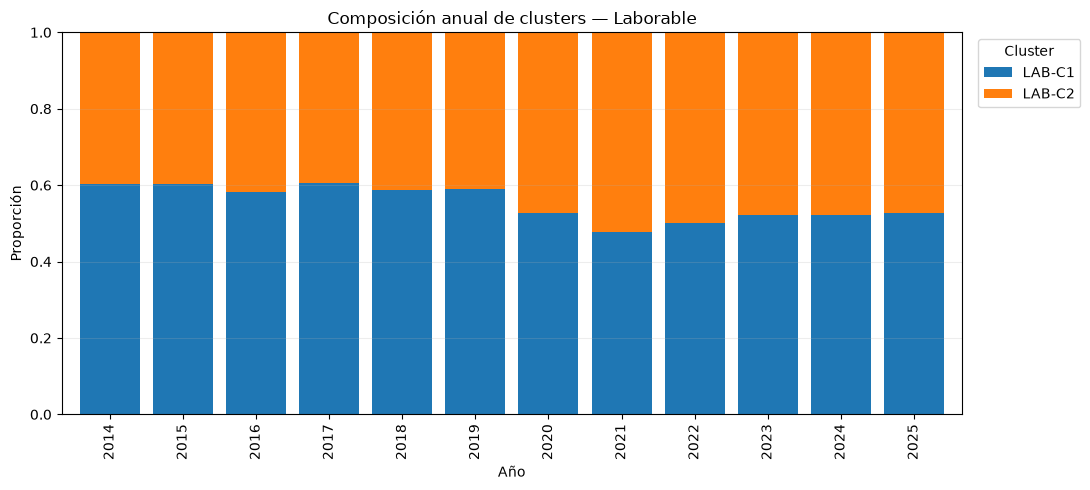

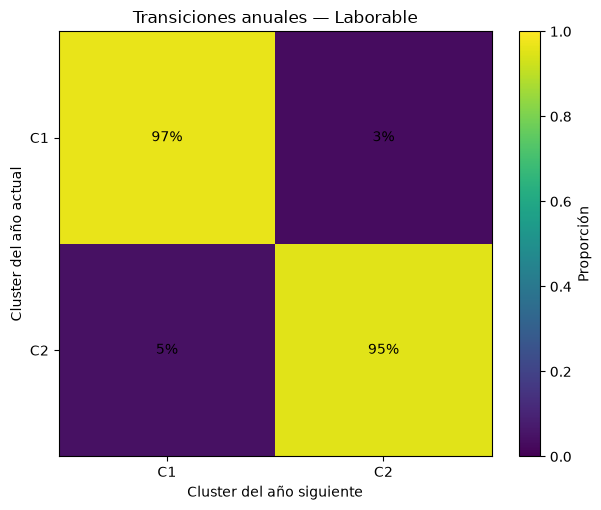

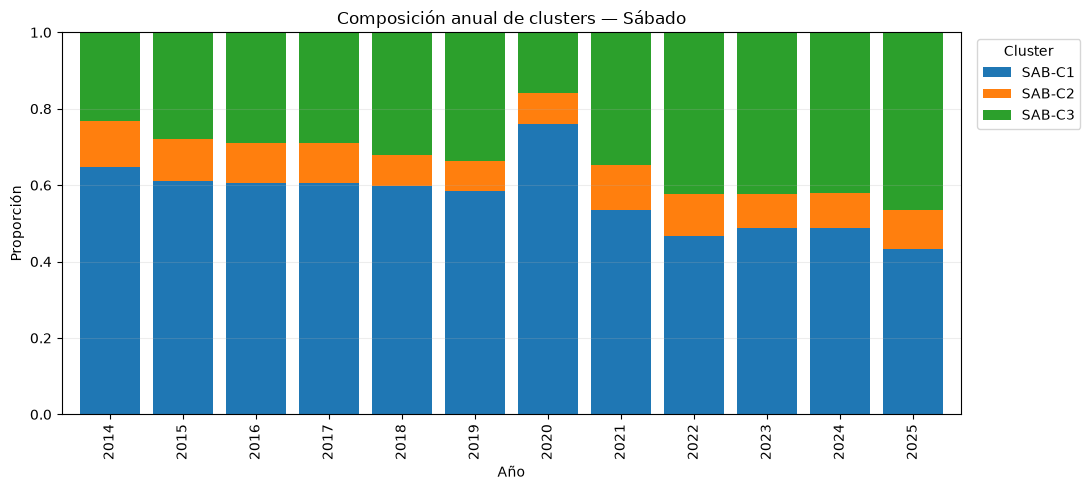

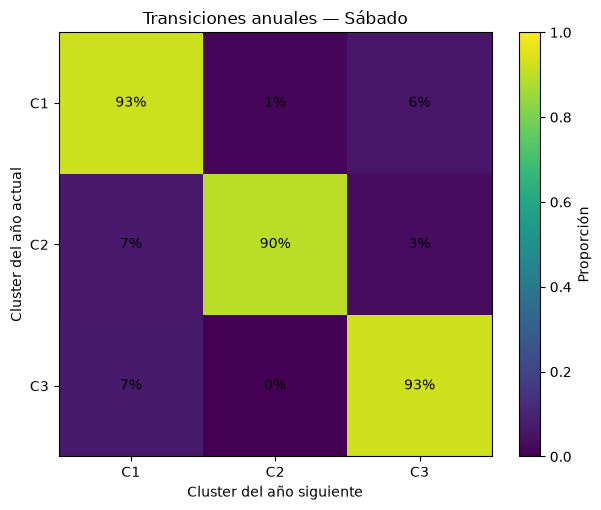

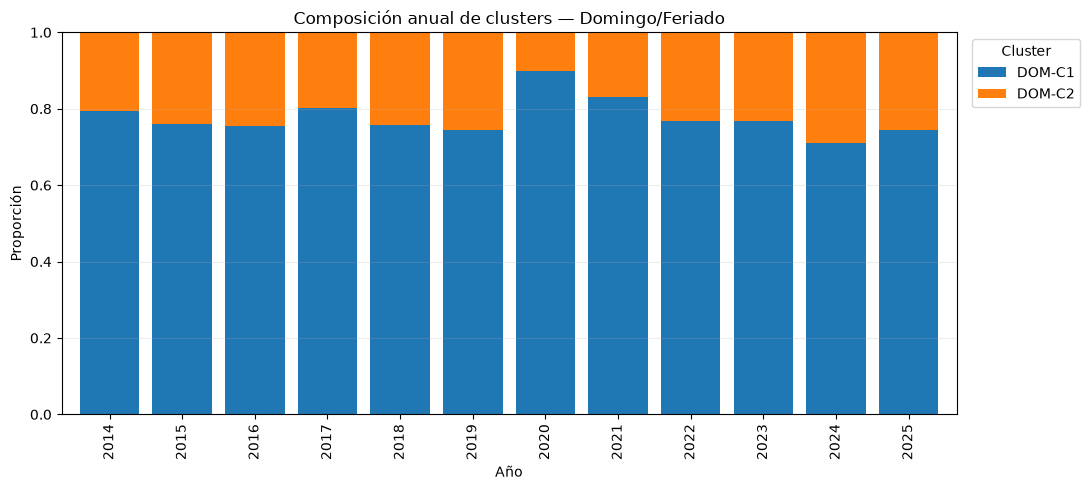

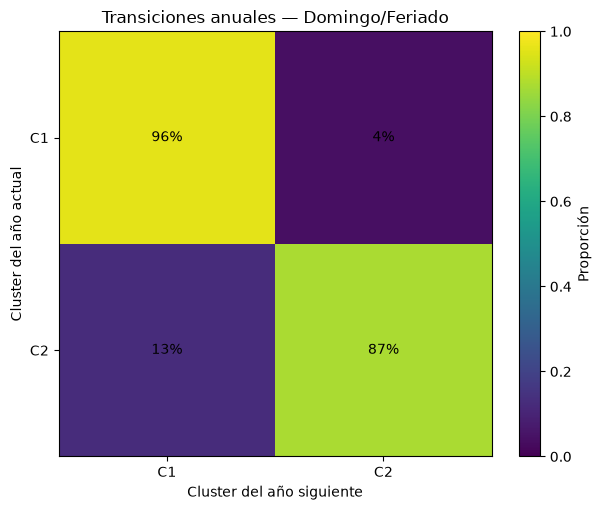

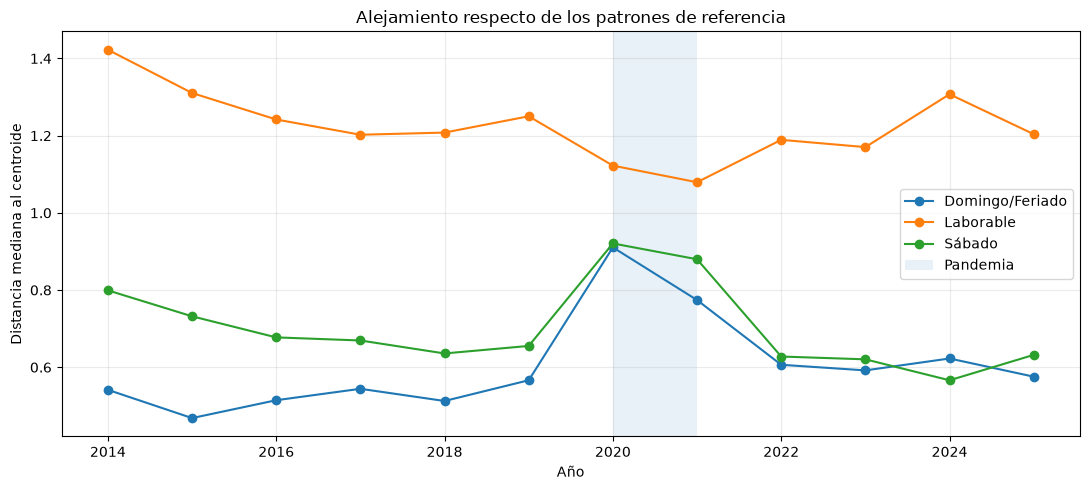

In [18]:
if EXCLUIR_ANIOS_PARCIALES_DE_EVOLUCION:
    scores_evol = scores_df[~scores_df["anio_parcial"]].copy()
else:
    scores_evol = scores_df.copy()

anios_parciales = sorted(
    scores_df.loc[scores_df["anio_parcial"], "anio"].unique().tolist()
)
print("Años parciales excluidos de evolución:", anios_parciales)

evolucion_frames = []
transicion_frames = []

for segmento in SEGMENTOS_DIA:
    g = scores_evol[scores_evol["segmento_dia"] == segmento].copy()
    if g.empty:
        continue

    comp = (
        g.groupby(["anio", "cluster_id"], observed=True)
        .size()
        .rename("n")
        .reset_index()
    )
    comp["proporcion"] = comp.groupby("anio")["n"].transform(
        lambda x: x / x.sum()
    )
    comp["segmento_dia"] = segmento
    evolucion_frames.append(comp)

    p = comp.pivot(
        index="anio",
        columns="cluster_id",
        values="proporcion",
    ).fillna(0)
    ax = p.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 5),
        width=.82,
    )
    ax.set_xlabel("Año")
    ax.set_ylabel("Proporción")
    ax.set_title(f"Composición anual de clusters — {segmento}")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=.22)
    ax.legend(title="Cluster", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # Transiciones de una misma estación entre años consecutivos.
    a = g[["estacion_id", "anio", "cluster"]].copy()
    b = a.rename(columns={
        "anio": "anio_siguiente",
        "cluster": "cluster_siguiente",
    })
    pares = a.merge(b, on="estacion_id", how="inner")
    pares = pares[
        pares["anio_siguiente"] == pares["anio"] + 1
    ].copy()

    if not pares.empty:
        ct_n = pd.crosstab(
            pares["cluster"],
            pares["cluster_siguiente"],
        )
        ct = pd.crosstab(
            pares["cluster"],
            pares["cluster_siguiente"],
            normalize="index",
        )

        for i in ct.index:
            for j in ct.columns:
                transicion_frames.append(pd.DataFrame({
                    "segmento_dia": [segmento],
                    "cluster_origen": [int(i)],
                    "cluster_destino": [int(j)],
                    "proporcion": [float(ct.loc[i, j])],
                    "n": [int(ct_n.loc[i, j])],
                }))

        fig, ax = plt.subplots(figsize=(6.2, 5.2))
        im = ax.imshow(ct.to_numpy(), vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(ct.columns)), [f"C{x}" for x in ct.columns])
        ax.set_yticks(range(len(ct.index)), [f"C{x}" for x in ct.index])
        ax.set_xlabel("Cluster del año siguiente")
        ax.set_ylabel("Cluster del año actual")
        ax.set_title(f"Transiciones anuales — {segmento}")
        for i in range(ct.shape[0]):
            for j in range(ct.shape[1]):
                ax.text(j, i, f"{ct.iloc[i, j]:.0%}", ha="center", va="center")
        fig.colorbar(im, ax=ax, label="Proporción")
        plt.tight_layout()
        plt.show()

    # Trayectorias menos saturadas: solo estaciones con más años disponibles.
    top = (
        g.groupby("estacion_id")["anio"]
        .nunique()
        .sort_values(ascending=False)
        .head(6)
        .index
    )
    tray = g[g["estacion_id"].isin(top)].sort_values(
        ["estacion_id", "anio"]
    )
    if not tray.empty and "FPC2" in tray.columns:
        fig = px.line(
            tray,
            x="FPC1",
            y="FPC2",
            color="estacion_id",
            markers=True,
            hover_data=[
                "anio", "cluster_id", "periodo",
                "pax_diarios_mediana", "distancia_centroide",
            ],
            title=f"Trayectorias anuales — {segmento}",
        )
        fig.show()

# Distancia al cluster de referencia: útil para ver la ruptura pandémica.
desvio_anual = (
    scores_evol.groupby(["segmento_dia", "anio"], observed=True)
    .agg(
        distancia_mediana=("distancia_centroide", "median"),
        distancia_p90=("distancia_centroide", lambda x: x.quantile(.90)),
        perfiles=("curve_id", "size"),
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))
for segmento, g in desvio_anual.groupby("segmento_dia", sort=False):
    plt.plot(
        g["anio"],
        g["distancia_mediana"],
        marker="o",
        label=segmento,
    )
plt.axvspan(2020, 2021, alpha=.10, label="Pandemia")
plt.xlabel("Año")
plt.ylabel("Distancia mediana al centroide")
plt.title("Alejamiento respecto de los patrones de referencia")
plt.grid(alpha=.25)
plt.legend()
plt.tight_layout()
plt.show()

evolucion_clusters = (
    pd.concat(evolucion_frames, ignore_index=True)
    if evolucion_frames else pd.DataFrame()
)
transiciones_clusters = (
    pd.concat(transicion_frames, ignore_index=True)
    if transicion_frames else pd.DataFrame()
)

## 8. Diferencia directa entre tipos de día

Además de clusterizar cada segmento por separado, conviene medir cuánto cambia una misma estación entre:

- Laborable y Sábado;
- Laborable y Domingo/Feriado.

La distancia se calcula entre las curvas suavizadas y normalizadas. Así se mide el cambio de **forma**, mientras que el cociente de volumen queda informado por separado.

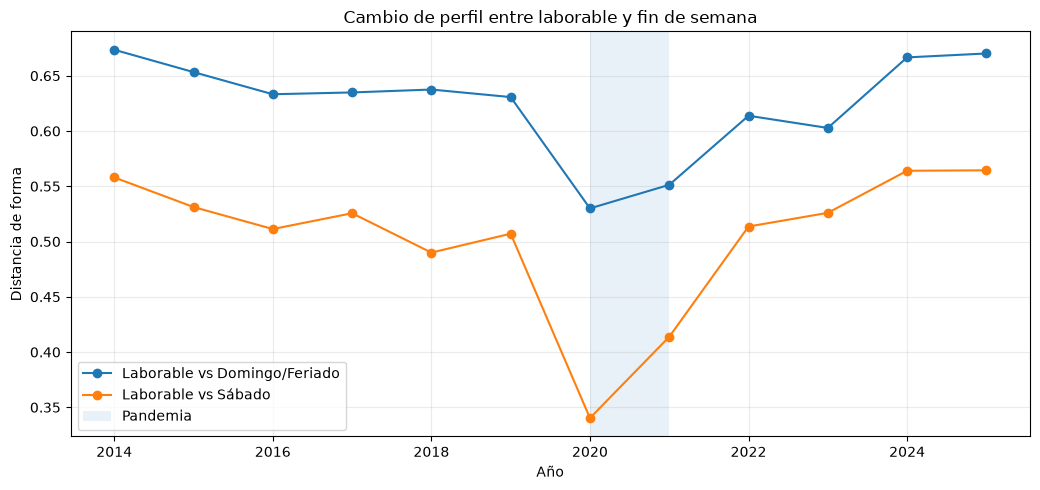

,comparacion,estacion_id,distancia_mediana,ratio_volumen_mediano,anios
73,Laborable vs Domingo/Feriado,E | PZA. DE LOS VIRREYES,1.307,0.196,11
23,Laborable vs Domingo/Feriado,B | ECHEVERRIA,1.288,0.201,11
32,Laborable vs Domingo/Feriado,B | ROSAS,1.247,0.208,12
36,Laborable vs Domingo/Feriado,C | CONSTITUCION,1.221,0.254,12
77,Laborable vs Domingo/Feriado,E | VARELA,1.215,0.216,11
71,Laborable vs Domingo/Feriado,E | MEDALLA MILAGROSA,1.196,0.233,11
69,Laborable vs Domingo/Feriado,E | JOSE MARIA MORENO,1.169,0.255,11
82,Laborable vs Domingo/Feriado,H | HOSPITALES,1.167,0.195,12
65,Laborable vs Domingo/Feriado,E | EMILIO MITRE,1.141,0.301,11
17,Laborable vs Domingo/Feriado,A | SAN PEDRITO,1.124,0.150,12


In [19]:
comparaciones = []
lab = perfiles_df[
    perfiles_df["segmento_dia"] == "Laborable"
].set_index(["estacion_id", "anio"])

for otro in ["Sábado", "Domingo/Feriado"]:
    oth = perfiles_df[
        perfiles_df["segmento_dia"] == otro
    ].set_index(["estacion_id", "anio"])
    common = lab.index.intersection(oth.index)
    if len(common) == 0:
        continue

    A = lab.loc[common, slot_cols].to_numpy(float)
    B_ = oth.loc[common, slot_cols].to_numpy(float)
    dist = np.sqrt(np.mean((A - B_) ** 2, axis=1))

    base = common.to_frame(index=False)
    base["comparacion"] = f"Laborable vs {otro}"
    base["distancia_forma"] = dist
    base["ratio_volumen_otro_laborable"] = (
        oth.loc[common, "pax_diarios_mediana"].to_numpy(float)
        / lab.loc[common, "pax_diarios_mediana"].replace(0, np.nan).to_numpy(float)
    )
    base["anio_parcial"] = lab.loc[common, "anio_parcial"].to_numpy(bool)
    comparaciones.append(base)

contraste_dias = (
    pd.concat(comparaciones, ignore_index=True)
    if comparaciones else pd.DataFrame()
)

if not contraste_dias.empty:
    contraste_plot = contraste_dias.copy()
    if EXCLUIR_ANIOS_PARCIALES_DE_EVOLUCION:
        contraste_plot = contraste_plot[~contraste_plot["anio_parcial"]]

    med_anual = (
        contraste_plot.groupby(["comparacion", "anio"], observed=True)
        .agg(
            distancia_mediana=("distancia_forma", "median"),
            distancia_p90=("distancia_forma", lambda x: x.quantile(.90)),
            estaciones=("estacion_id", "nunique"),
        )
        .reset_index()
    )

    plt.figure(figsize=(10.5, 5))
    for comparacion, g in med_anual.groupby("comparacion", sort=False):
        plt.plot(
            g["anio"],
            g["distancia_mediana"],
            marker="o",
            label=comparacion,
        )
    plt.axvspan(2020, 2021, alpha=.10, label="Pandemia")
    plt.xlabel("Año")
    plt.ylabel("Distancia de forma")
    plt.title("Cambio de perfil entre laborable y fin de semana")
    plt.grid(alpha=.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    ranking_contraste = (
        contraste_plot.groupby(["comparacion", "estacion_id"], observed=True)
        .agg(
            distancia_mediana=("distancia_forma", "median"),
            ratio_volumen_mediano=("ratio_volumen_otro_laborable", "median"),
            anios=("anio", "nunique"),
        )
        .reset_index()
        .sort_values(["comparacion", "distancia_mediana"], ascending=[True, False])
    )
    display(ranking_contraste.groupby("comparacion").head(10))
else:
    med_anual = pd.DataFrame()
    ranking_contraste = pd.DataFrame()
    print("No hay suficientes pares de perfiles para comparar tipos de día.")

## 9. Cambio pre y pospandemia

La comparación se realiza dentro del mismo espacio funcional de cada segmento. Se toma el último año completo anterior a 2020 y el último año completo desde 2022. Esto evita comparar 2019 con un 2026 todavía parcial.

In [20]:
anios_completos = sorted(
    year_info.loc[~year_info["anio_parcial"], "anio"].astype(int).tolist()
)
pre_candidates = [a for a in anios_completos if a < 2020]
post_candidates = [a for a in anios_completos if a >= 2022]
pre = max(pre_candidates) if pre_candidates else None
post = max(post_candidates) if post_candidates else None

cambios_frames = []
if pre is not None and post is not None:
    for fila_modelo in resumen_modelos.itertuples(index=False):
        segmento = fila_modelo.segmento_dia
        r = int(fila_modelo.componentes_cluster)
        cols = [f"FPC{i+1}" for i in range(r)]

        d = scores_df[scores_df["segmento_dia"] == segmento]
        a = d[d["anio"] == pre].set_index("estacion_id")
        b = d[d["anio"] == post].set_index("estacion_id")
        common = a.index.intersection(b.index)
        if len(common) == 0:
            continue

        delta = b.loc[common, cols].to_numpy() - a.loc[common, cols].to_numpy()
        cambio = pd.DataFrame({
            "segmento_dia": segmento,
            "estacion_id": common,
            "anio_pre": pre,
            "anio_post": post,
            "distancia_scores": np.linalg.norm(delta, axis=1),
            "cluster_pre": a.loc[common, "cluster_id"].to_numpy(),
            "cluster_post": b.loc[common, "cluster_id"].to_numpy(),
            "pax_pre": a.loc[common, "pax_diarios_mediana"].to_numpy(),
            "pax_post": b.loc[common, "pax_diarios_mediana"].to_numpy(),
        })
        cambio["ratio_pax_post_pre"] = cambio["pax_post"] / cambio["pax_pre"].replace(0, np.nan)
        cambios_frames.append(cambio)

cambios = (
    pd.concat(cambios_frames, ignore_index=True)
    if cambios_frames else pd.DataFrame()
)

if not cambios.empty:
    cambios = cambios.sort_values(
        ["segmento_dia", "distancia_scores"],
        ascending=[True, False],
    )
    print(f"Comparación pre/pospandemia: {pre} vs {post}")
    display(cambios.groupby("segmento_dia").head(10))
else:
    print("No se pudo construir una comparación pre/pospandemia completa.")

Comparación pre/pospandemia: 2019 vs 2025


,segmento_dia,estacion_id,anio_pre,anio_post,distancia_scores,cluster_pre,cluster_post,pax_pre,pax_post,ratio_pax_post_pre
251,Domingo/Feriado,E | RETIRO,2019,2025,1.176,DOM-C2,DOM-C1,"1,440.500",799.000,0.555
186,Domingo/Feriado,A | PERU,2019,2025,1.049,DOM-C2,DOM-C2,"2,082.500","1,060.000",0.509
219,Domingo/Feriado,C | RETIRO,2019,2025,0.961,DOM-C1,DOM-C1,"11,258.500","5,169.000",0.459
213,Domingo/Feriado,C | CONSTITUCION,2019,2025,0.890,DOM-C1,DOM-C1,"23,334.000","16,866.000",0.723
221,Domingo/Feriado,D | 9 DE JULIO,2019,2025,0.838,DOM-C2,DOM-C1,"1,242.000",486.500,0.392
257,Domingo/Feriado,H | CORRIENTES,2019,2025,0.836,DOM-C1,DOM-C2,"1,415.000","1,204.000",0.851
235,Domingo/Feriado,D | SCALABRINI ORTIZ,2019,2025,0.823,DOM-C1,DOM-C2,"3,832.000","2,980.000",0.778
242,Domingo/Feriado,E | EMILIO MITRE,2019,2025,0.816,DOM-C1,DOM-C2,"1,635.000","1,322.000",0.809
233,Domingo/Feriado,D | PLAZA ITALIA,2019,2025,0.807,DOM-C2,DOM-C2,"5,543.000","4,634.000",0.836
225,Domingo/Feriado,D | CATEDRAL,2019,2025,0.743,DOM-C2,DOM-C2,"3,403.500","2,526.000",0.742


## 10. Días anómalos

La detección combina cambios robustos de volumen y cambios en la composición relativa de pasajeros entre estaciones. Los días con baja cobertura se excluyen de la interpretación de anomalías.

In [21]:
ds=con.sql(f'''WITH vd AS(SELECT fecha,estacion_id FROM station_day_cov WHERE cobertura>={UMBRAL_COBERTURA_DIA}) SELECT s.fecha,s.anio,s.estacion_id,SUM(s.pax_total) pax_total FROM station_slot_cal s JOIN vd USING(fecha,estacion_id) GROUP BY ALL ORDER BY fecha,estacion_id''').df(); ds.fecha=pd.to_datetime(ds.fecha); mat=ds.pivot(index="fecha",columns="estacion_id",values="pax_total"); info=diaria.set_index("fecha").reindex(mat.index).copy(); info["dow"]=info.index.dayofweek; info["log_total"]=np.log1p(info.pax_total)
def rz(s):
    med=s.median(); mad=np.median(np.abs(s-med)); return pd.Series(0.0,index=s.index) if not np.isfinite(mad) or mad<1e-12 else .6745*(s-med)/mad
info["z_total"]=info.groupby(["anio","dow"],group_keys=False).log_total.apply(rz); info["iforest_score"]=np.nan; info["iforest_anomalia"]=False
for anio,ix in info.groupby("anio").groups.items():
    ix=pd.Index(ix); el=ix[info.loc[ix,"cobertura_red"].ge(.8)]
    if len(el)<60: continue
    sh=mat.loc[el].div(mat.loc[el].sum(1),axis=0); sh=sh.fillna(sh.median()).fillna(0); X=StandardScaler().fit_transform(sh); iso=IsolationForest(n_estimators=300,contamination=.02,random_state=SEED+int(anio),n_jobs=-1); pred=iso.fit_predict(X); info.loc[el,"iforest_score"]=-iso.decision_function(X); info.loc[el,"iforest_anomalia"]=pred==-1
info["anomalia_volumen"]=info.z_total.abs()>=3.5; info["anomalia_cobertura"]=info.cobertura_red<.8; info["anomalia_final"]=(info.anomalia_volumen|info.iforest_anomalia)&~info.anomalia_cobertura
anom=info.reset_index().sort_values(["anomalia_final","iforest_score","z_total"],ascending=[False,False,True]); anom.to_csv(OUTDIR/"dias_anomalos.csv",index=False); display(anom[anom.anomalia_final].head(25)[["fecha","anio","pax_total","cobertura_red","z_total","iforest_score","anomalia_volumen","iforest_anomalia"]])

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

/var/folders/ct/gr7hrdz13kx_rbxf7hp6yfjw0000gn/T/ipykernel_40222/1155136108.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  sh=mat.loc[el].div(mat.loc[el].sum(1),axis=0); sh=sh.fillna(sh.median()).fillna(0); X=StandardScaler().fit_transform(sh); iso=IsolationForest(n_estimators=300,contamination=.02,random_state=SEED+int(anio),n_jobs=-1); pred=iso.fit_predict(X); info.loc[el,"iforest_score"]=-iso.decision_function(X); info.loc[el,"iforest_anomalia"]=pred==-1
/var/folders/ct/gr7hrdz13kx_rbxf7hp6yfjw0000gn/T/ipykernel_40222/1155136108.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  sh=mat.loc[el].div(mat.loc[el].sum(1),axis=0); sh=sh.fillna(sh.median()).fillna(0); X=StandardScaler().fit_transform(sh); iso=IsolationForest(n_estimators=300,contamination=.02,random_state=SEED+int(anio),n_jobs=-1); pred=iso.fit_predict(X); info.loc[el,"iforest_score"]=-iso.decision_function(X); info.loc[el

,fecha,anio,pax_total,cobertura_red,z_total,iforest_score,anomalia_volumen,iforest_anomalia
1591,2018-05-18,2018,"1,107,765.000",0.901,-2.055,0.210,False,True
1589,2018-05-16,2018,"1,121,776.000",0.851,-3.089,0.199,False,True
2055,2019-09-06,2019,"938,807.000",0.838,-7.676,0.153,True,True
536,2015-06-25,2015,"799,825.000",0.970,-2.978,0.148,False,True
1451,2017-12-28,2017,"808,864.000",0.816,-4.687,0.135,True,True
3657,2024-02-21,2024,"444,011.000",0.827,-2.767,0.127,False,True
3429,2023-07-05,2023,"624,312.000",0.816,-4.287,0.114,True,True
892,2016-06-15,2016,"956,644.000",0.804,-2.885,0.109,False,True
2792,2021-10-03,2021,"311,321.000",0.850,1.993,0.107,False,True
253,2014-09-13,2014,"276,691.000",0.827,-0.338,0.104,False,True


## 11. MaxVol y selección de prototipos

Se aplica MaxVol por separado dentro de cada segmento de día, sobre los scores de las FPC que explican al menos el objetivo de varianza. Antes de seleccionar filas se estandarizan los scores y se agrega una columna de unos: de ese modo el volumen representa la dispersión **afín** de los perfiles y no depende de la escala de cada componente.

La inicialización usa QR con pivoteo y luego intercambios MaxVol hasta obtener una submatriz de cuasi-máximo volumen. Los perfiles elegidos son extremos geométricos que permiten representar la diversidad del conjunto; no son centroides ni necesariamente los casos más frecuentes. El enfoque sigue la motivación de reducción dimensional y prototipos de las [diapositivas de la clase](https://rballester.github.io/uba_winter_school/#/dimensionality-reduction).

El primer gráfico ubica los prototipos como estrellas dentro de **todos** los perfiles del segmento. El segundo muestra sus curvas funcionales para poder interpretar qué comportamientos extremos capturó MaxVol.

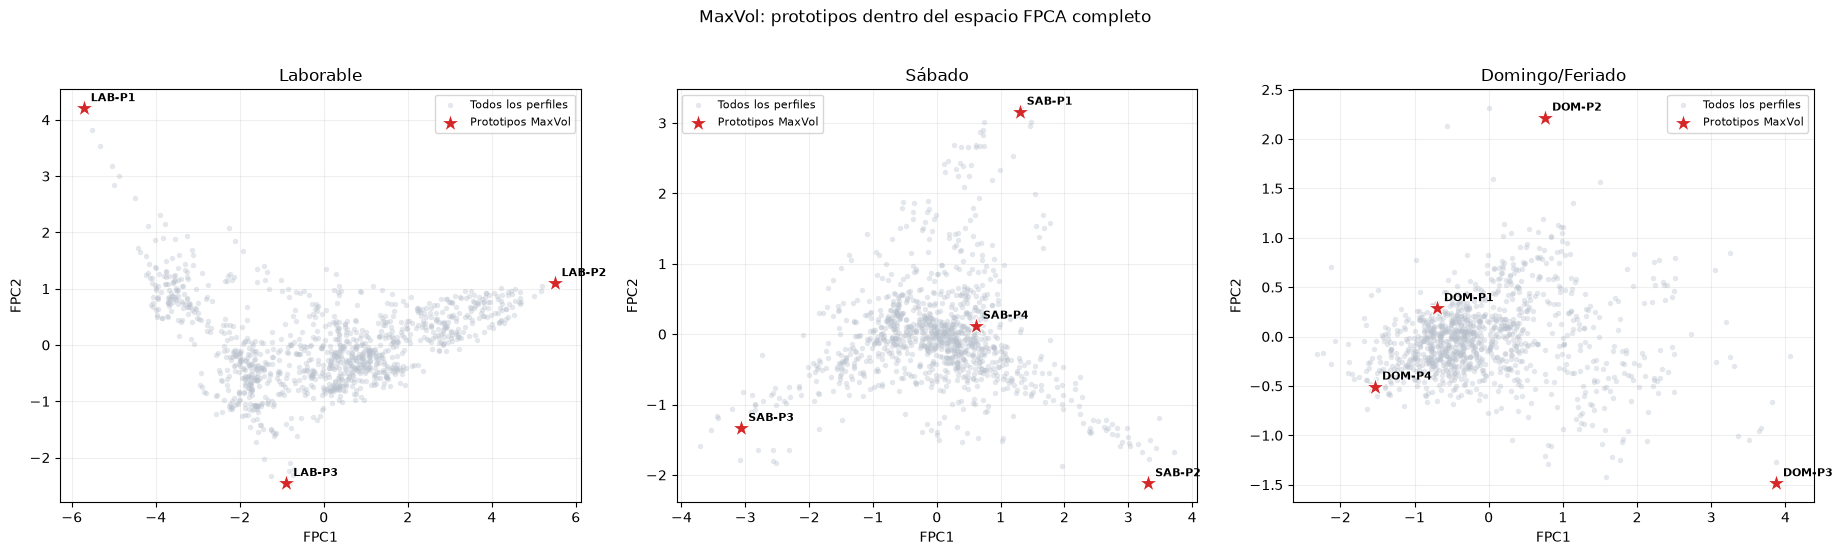

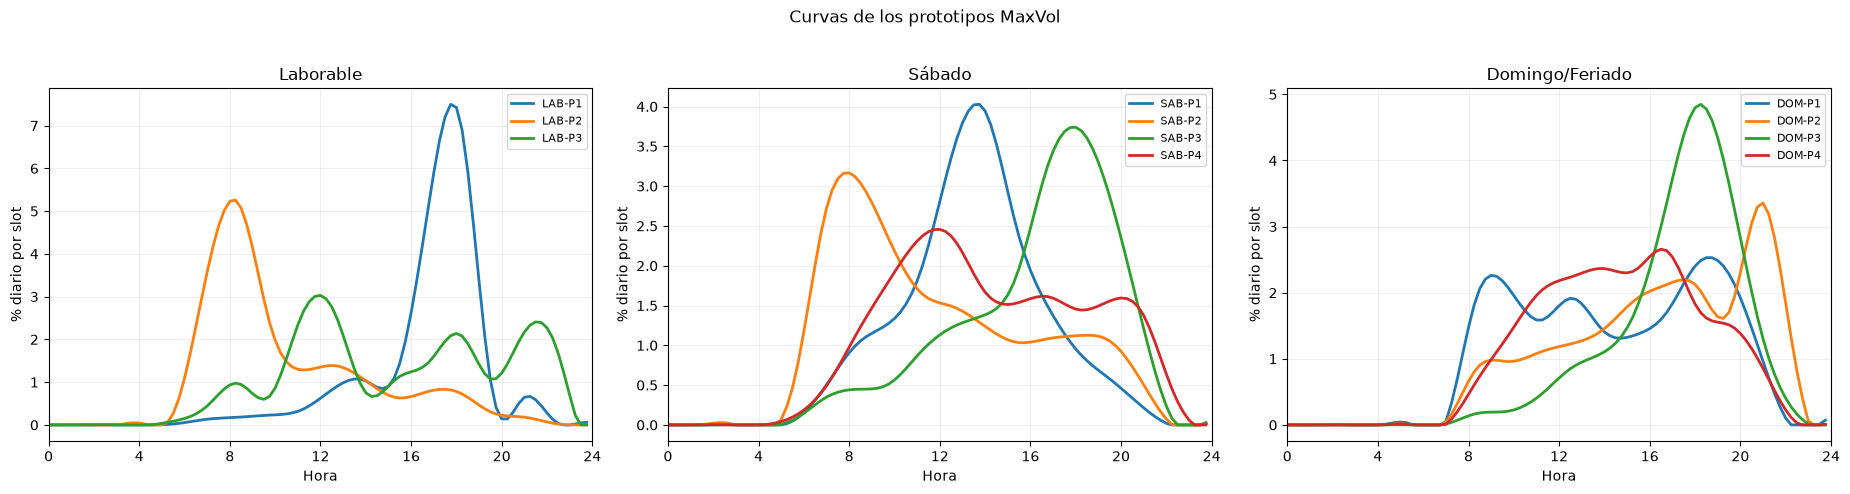

,segmento_dia,perfiles_candidatos,componentes_fpca,prototipos,iteraciones,coef_max_final,log_volumen
0,Laborable,1105,2,3,0,1.002,3.572
1,Sábado,1065,3,4,0,1.000,5.458
2,Domingo/Feriado,1100,3,4,2,1.000,5.783


,prototipo_maxvol,segmento_dia,estacion_id,anio,cluster_id,hora_pico,pax_diarios_mediana,referencia_modelo,anio_parcial,coef_max_final
7,DOM-P1,Domingo/Feriado,C | CONSTITUCION,2020,DOM-C1,18:30,"2,476.000",False,False,1.000
8,DOM-P2,Domingo/Feriado,D | JURAMENTO,2020,DOM-C2,21:00,502.500,False,False,1.000
9,DOM-P3,Domingo/Feriado,H | FACULTAD DE DERECHO,2018,DOM-C2,18:15,"1,923.000",True,False,1.000
10,DOM-P4,Domingo/Feriado,A | PASCO,2021,DOM-C1,16:30,321.000,False,False,1.000
0,LAB-P1,Laborable,E | CATALINAS,2026,LAB-C2,17:45,"4,683.500",False,True,1.002
1,LAB-P2,Laborable,E | PZA. DE LOS VIRREYES,2015,LAB-C1,08:15,"9,604.000",True,False,1.002
2,LAB-P3,Laborable,E | INDEPENDENCIA,2019,LAB-C2,12:00,"11,194.000",True,False,1.002
3,SAB-P1,Sábado,A | SAN PEDRITO,2021,SAB-C2,13:45,"7,741.000",False,False,1.000
4,SAB-P2,Sábado,C | CONSTITUCION,2020,SAB-C1,08:00,"5,355.500",False,False,1.000
5,SAB-P3,Sábado,H | FACULTAD DE DERECHO,2021,SAB-C3,18:00,906.000,False,False,1.000


In [22]:
def seleccionar_filas_maxvol(A, tol=1.05, max_iter=500):
    """Selecciona una submatriz cuadrada de cuasi-máximo volumen.

    A debe tener al menos tantas filas como columnas. QR con pivoteo
    entrega la semilla y los intercambios reducen max(abs(A @ inv(B))).
    Se usa pseudoinversa para tolerar pequeñas inestabilidades numéricas.
    """
    A = np.asarray(A, dtype=float)
    if A.ndim != 2 or A.shape[0] < A.shape[1]:
        raise ValueError("MaxVol requiere una matriz n x r con n >= r.")

    _, _, piv = qr(A.T, pivoting=True, mode="economic")
    indices = np.asarray(piv[:A.shape[1]], dtype=int)
    iteraciones = 0

    while iteraciones < max_iter:
        Bmv = A[indices]
        C = A @ np.linalg.pinv(Bmv)
        i, j = np.unravel_index(np.abs(C).argmax(), C.shape)
        coef_max = float(abs(C[i, j]))
        if coef_max <= tol:
            break
        indices[j] = i
        iteraciones += 1

    Bmv = A[indices]
    C = A @ np.linalg.pinv(Bmv)
    signo, logabsdet = np.linalg.slogdet(Bmv)
    return {
        "indices": indices,
        "iteraciones": iteraciones,
        "coef_max_final": float(np.abs(C).max()),
        "log_volumen": float(logabsdet) if signo != 0 else -np.inf,
    }


prototipos_frames = []
diagnostico_maxvol_rows = []

for segmento in SEGMENTOS_DIA:
    if segmento not in modelos_segmento:
        continue

    sc = scores_df[scores_df["segmento_dia"] == segmento].reset_index(drop=True)
    modelo = modelos_segmento[segmento]
    fpc_disponibles = [
        c for c in sc.columns if re.fullmatch(r"FPC\d+", c)
    ]
    fpc_disponibles = sorted(fpc_disponibles, key=lambda x: int(x[3:]))
    n_scores = min(max(1, int(modelo["r_var"])), 5, len(fpc_disponibles))
    columnas = fpc_disponibles[:n_scores]

    Z = sc[columnas].to_numpy(float)
    escala = Z.std(axis=0, ddof=0)
    escala[~np.isfinite(escala) | (escala < 1e-12)] = 1.0
    Z = (Z - Z.mean(axis=0)) / escala
    A_mv = np.column_stack([np.ones(len(Z)), Z])
    resultado_mv = seleccionar_filas_maxvol(A_mv)

    elegidos = sc.iloc[resultado_mv["indices"]].copy()
    abrev = {
        "Laborable": "LAB",
        "Sábado": "SAB",
        "Domingo/Feriado": "DOM",
    }.get(segmento, "SEG")
    elegidos["prototipo_maxvol"] = [
        f"{abrev}-P{i+1}" for i in range(len(elegidos))
    ]
    elegidos["orden_maxvol"] = np.arange(1, len(elegidos) + 1)
    elegidos["componentes_usadas_maxvol"] = n_scores
    elegidos["coef_max_final"] = resultado_mv["coef_max_final"]
    elegidos["log_volumen"] = resultado_mv["log_volumen"]
    prototipos_frames.append(elegidos)

    diagnostico_maxvol_rows.append({
        "segmento_dia": segmento,
        "perfiles_candidatos": len(sc),
        "componentes_fpca": n_scores,
        "prototipos": len(elegidos),
        "iteraciones": resultado_mv["iteraciones"],
        "coef_max_final": resultado_mv["coef_max_final"],
        "log_volumen": resultado_mv["log_volumen"],
    })

prototipos_maxvol = pd.concat(prototipos_frames, ignore_index=True)
diagnostico_maxvol = pd.DataFrame(diagnostico_maxvol_rows)

# Añadir rasgos de las curvas para interpretar cada prototipo.
curvas_proto = prototipos_maxvol[[
    "curve_id", "segmento_dia", "prototipo_maxvol"
]].merge(
    perfiles_df[["curve_id", "segmento_dia", *slot_cols]],
    on=["curve_id", "segmento_dia"],
    how="left",
    validate="one_to_one",
)
rasgos_proto = []
for r in curvas_proto.itertuples(index=False):
    curva = np.asarray([getattr(r, c) for c in slot_cols], dtype=float)
    total = curva.sum()
    pico_idx = int(np.nanargmax(curva))

    def proporcion(h0, h1):
        mascara = (GRID_H >= h0) & (GRID_H < h1)
        return float(curva[mascara].sum() / total) if total > 0 else np.nan

    rasgos_proto.append({
        "prototipo_maxvol": r.prototipo_maxvol,
        "hora_pico": f"{GRID_MIN[pico_idx]//60:02d}:{GRID_MIN[pico_idx]%60:02d}",
        "share_06_10": proporcion(6, 10),
        "share_10_16": proporcion(10, 16),
        "share_16_21": proporcion(16, 21),
        "share_21_24": proporcion(21, 24),
    })

prototipos_maxvol = prototipos_maxvol.merge(
    pd.DataFrame(rasgos_proto), on="prototipo_maxvol", how="left"
)

# Todos los perfiles en gris; los prototipos MaxVol se destacan con estrellas.
segmentos_modelados = [s for s in SEGMENTOS_DIA if s in modelos_segmento]
fig, axes = plt.subplots(
    1, len(segmentos_modelados),
    figsize=(6.2 * len(segmentos_modelados), 5.4),
    squeeze=False,
)
for ax, segmento in zip(axes.ravel(), segmentos_modelados):
    sc = scores_df[scores_df["segmento_dia"] == segmento]
    pr = prototipos_maxvol[prototipos_maxvol["segmento_dia"] == segmento]
    ycol = "FPC2" if "FPC2" in sc.columns else "distancia_centroide"
    ax.scatter(
        sc["FPC1"], sc[ycol],
        s=15, c="#B8C0CC", alpha=.38, linewidths=0, label="Todos los perfiles"
    )
    ax.scatter(
        pr["FPC1"], pr[ycol],
        s=190, c="#D62728", marker="*",
        edgecolors="white", linewidths=.8, label="Prototipos MaxVol", zorder=4
    )
    for r in pr.itertuples(index=False):
        ax.annotate(
            r.prototipo_maxvol,
            (getattr(r, "FPC1"), getattr(r, ycol)),
            xytext=(5, 5), textcoords="offset points", fontsize=8, weight="bold"
        )
    ax.set_title(segmento)
    ax.set_xlabel("FPC1")
    ax.set_ylabel(ycol)
    ax.grid(alpha=.20)
    ax.legend(loc="best", fontsize=8)
fig.suptitle("MaxVol: prototipos dentro del espacio FPCA completo", y=1.02)
plt.tight_layout()
plt.show()

# Curvas funcionales correspondientes a los puntos seleccionados.
fig, axes = plt.subplots(
    1, len(segmentos_modelados),
    figsize=(6.2 * len(segmentos_modelados), 4.8),
    squeeze=False,
)
for ax, segmento in zip(axes.ravel(), segmentos_modelados):
    ids = prototipos_maxvol.loc[
        prototipos_maxvol["segmento_dia"] == segmento,
        ["curve_id", "prototipo_maxvol"],
    ]
    curvas = ids.merge(
        perfiles_df[["curve_id", "segmento_dia", *slot_cols]],
        on="curve_id", how="left", validate="one_to_one"
    )
    for r in curvas.itertuples(index=False):
        ax.plot(
            GRID_H, [getattr(r, c) for c in slot_cols],
            lw=2, label=r.prototipo_maxvol
        )
    ax.set_title(segmento)
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 4))
    ax.set_xlabel("Hora")
    ax.set_ylabel("% diario por slot")
    ax.grid(alpha=.20)
    ax.legend(fontsize=8)
fig.suptitle("Curvas de los prototipos MaxVol", y=1.02)
plt.tight_layout()
plt.show()

columnas_tabla = [
    "prototipo_maxvol", "segmento_dia", "estacion_id", "anio",
    "cluster_id", "hora_pico", "pax_diarios_mediana",
    "referencia_modelo", "anio_parcial", "coef_max_final",
]
display(diagnostico_maxvol)
display(prototipos_maxvol[columnas_tabla].sort_values(
    ["segmento_dia", "prototipo_maxvol"]
))
prototipos_maxvol.to_csv(OUTDIR / "prototipos_maxvol.csv", index=False)
diagnostico_maxvol.to_csv(OUTDIR / "diagnostico_maxvol.csv", index=False)


## 12. Exportación y diagnóstico automático

In [23]:
# Exportaciones principales.
perfiles_df.to_csv(OUTDIR / "perfiles_suavizados_segmentados.csv", index=False)
scores_df.to_csv(OUTDIR / "scores_fpca_clusters_segmentados.csv", index=False)
metricas_segmentos.to_csv(OUTDIR / "metricas_clustering_segmentado.csv", index=False)
varianza_segmentos.to_csv(OUTDIR / "varianza_fpca_segmentada.csv", index=False)
gcv_segmentos.to_csv(OUTDIR / "gcv_suavizado_segmentado.csv", index=False)
resumen_modelos.to_csv(OUTDIR / "resumen_modelos_segmentados.csv", index=False)
resumen_clusters.to_csv(OUTDIR / "caracterizacion_clusters.csv", index=False)
year_info.to_csv(OUTDIR / "cobertura_temporal_anios.csv", index=False)
desvio_anual.to_csv(OUTDIR / "desvio_anual_referencia.csv", index=False)

if not evolucion_clusters.empty:
    evolucion_clusters.to_csv(OUTDIR / "clusters_por_anio_segmentados.csv", index=False)
if not transiciones_clusters.empty:
    transiciones_clusters.to_csv(OUTDIR / "transiciones_clusters.csv", index=False)
if not contraste_dias.empty:
    contraste_dias.to_csv(OUTDIR / "contraste_tipos_dia.csv", index=False)
if not ranking_contraste.empty:
    ranking_contraste.to_csv(OUTDIR / "ranking_contraste_tipos_dia.csv", index=False)
if not cambios.empty:
    cambios.to_csv(OUTDIR / f"cambios_{pre}_{post}_por_segmento.csv", index=False)

filas_lineas_excluidas = int(audit_archivos.filas_linea_excluida.sum())
valid15 = (
    100 * float(audit_anios.validos_15.sum()) / float(audit_anios.filas.sum())
    if float(audit_anios.filas.sum()) > 0 else np.nan
)

lineas = [
    "# Resumen automático",
    "",
    f"- Fuentes aceptadas (procesadas o excluidas por regla): "
    f"{audit_archivos.estado.isin(['OK', 'EXCLUIDO_LINEA', 'EXCLUIDO_PREMETRO']).sum()} "
    f"de {len(audit_archivos)}.",
    f"- Filas estandarizadas: {n_staged:,}; tras resolver clave: {n_dedup:,}.",
    f"- Filas excluidas por línea {sorted(LINEAS_EXCLUIDAS)}: {filas_lineas_excluidas:,}.",
    f"- Intervalos válidos de {INTERVALO_MIN} min y en grilla: {valid15:.2f}%.",
    f"- Días faltantes según calendario evaluado: {len(dias_faltantes):,}.",
    f"- Curvas funcionales segmentadas: {len(scores_df):,}.",
    f"- Prototipos MaxVol seleccionados: {len(prototipos_maxvol):,}.",
    f"- Años parciales detectados: {anios_parciales}.",
    "",
    "## Modelos por segmento",
    "",
]

for r in resumen_modelos.itertuples(index=False):
    lineas.append(
        f"- **{r.segmento_dia}**: {r.curvas} curvas; "
        f"{r.componentes_90} FPC para {VAR_OBJETIVO:.0%}; "
        f"k={r.k}; silhouette={r.silhouette:.3f}; "
        f"ARI={r.ari_estabilidad:.3f}."
    )

if pre is not None and post is not None and not cambios.empty:
    mayor = cambios.sort_values("distancia_scores", ascending=False).iloc[0]
    lineas += [
        "",
        f"- Mayor cambio {pre}–{post}: {mayor.estacion_id}, "
        f"{mayor.segmento_dia} ({mayor.distancia_scores:.3f}).",
    ]

lineas += [
    "",
    "## Lectura",
    "",
    "- Los clusters se interpretan dentro de cada segmento de día.",
    "- Los scores de segmentos distintos no se comparan directamente.",
    "- Los clusters describen forma; el volumen se mantiene como variable separada.",
    "- 2020–2021 y los años parciales se proyectan sobre una referencia estable.",
    "- Silhouette baja puede indicar una estructura continua y no un fallo de FPCA.",
    "- MaxVol selecciona perfiles extremos que abarcan el espacio FPCA; no sustituye a los centroides.",
    "- Días de baja cobertura no deben interpretarse como caídas reales.",
]

res = "\n".join(lineas)
(OUTDIR / "resumen_automatico.md").write_text(res, encoding="utf-8")
display(Markdown(res))

# Diagnóstico de espacio ocupado por las capas persistentes.
def tamano_carpeta(path: Path) -> float:
    return sum(
        p.stat().st_size for p in path.rglob("*") if p.is_file()
    ) / 1024**3

uso_cache = pd.DataFrame({
    "capa": ["estandarizados", "station_slot", "resultados"],
    "GiB": [
        tamano_carpeta(PARTS),
        tamano_carpeta(STATION_PARTS),
        tamano_carpeta(OUTDIR),
    ],
})
display(uso_cache)
uso_cache.to_csv(OUTDIR / "uso_almacenamiento.csv", index=False)

config_ejecucion = {
    "carpeta_datos": str(CARPETA_DATOS.resolve()),
    "carpeta_trabajo": str(WORK),
    "carpeta_temporal": str(TMP_DUCKDB),
    "duckdb_threads": threads,
    "duckdb_memory_gib": memory_limit_gib,
    "duckdb_temp_gib": temp_limit_gib,
    "chunk_size": CHUNK_SIZE,
    "compression": PARQUET_COMPRESSION,
    "cache_version": CACHE_VERSION,
    "normalizacion_estaciones_version": NORMALIZACION_ESTACIONES_VERSION,
    "lineas_excluidas": sorted(LINEAS_EXCLUIDAS),
    "global_fingerprint": GLOBAL_FINGERPRINT,
    "segmentos_dia": SEGMENTOS_DIA,
    "anios_excluir_referencia": ANIOS_EXCLUIR_REFERENCIA,
}
(OUTDIR / "configuracion_ejecucion.json").write_text(
    json.dumps(config_ejecucion, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

zip_path = Path(
    shutil.make_archive(
        str(WORK / "resultados_proyecto_subte"),
        "zip",
        OUTDIR,
    )
)
print("Resultados:", OUTDIR)
print("ZIP:", zip_path)
print("La caché queda disponible para la próxima ejecución.")

# Resumen automático

- Fuentes aceptadas (procesadas o excluidas por regla): 122 de 122.
- Filas estandarizadas: 139,160,748; tras resolver clave: 137,218,455.
- Filas excluidas por línea ['LINEAPM']: 155,450.
- Intervalos válidos de 15 min y en grilla: 100.00%.
- Días faltantes según calendario evaluado: 28.
- Curvas funcionales segmentadas: 3,270.
- Prototipos MaxVol seleccionados: 11.
- Años parciales detectados: [2026].

## Modelos por segmento

- **Laborable**: 1105 curvas; 2 FPC para 90%; k=2; silhouette=0.529; ARI=1.000.
- **Sábado**: 1065 curvas; 3 FPC para 90%; k=3; silhouette=0.381; ARI=0.996.
- **Domingo/Feriado**: 1100 curvas; 3 FPC para 90%; k=2; silhouette=0.514; ARI=0.998.

- Mayor cambio 2019–2025: C | GENERAL SAN MARTIN, Laborable (1.449).

## Lectura

- Los clusters se interpretan dentro de cada segmento de día.
- Los scores de segmentos distintos no se comparan directamente.
- Los clusters describen forma; el volumen se mantiene como variable separada.
- 2020–2021 y los años parciales se proyectan sobre una referencia estable.
- Silhouette baja puede indicar una estructura continua y no un fallo de FPCA.
- MaxVol selecciona perfiles extremos que abarcan el espacio FPCA; no sustituye a los centroides.
- Días de baja cobertura no deben interpretarse como caídas reales.

,capa,GiB
0,estandarizados,0.726
1,station_slot,0.127
2,resultados,0.045


Resultados: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/subte_fpca_work/resultados
ZIP: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/subte_fpca_work/resultados_proyecto_subte.zip
La caché queda disponible para la próxima ejecución.


## 13. Interpretación final de clusters y prototipos

Esta sección genera una lectura narrativa a partir de los resultados recién calculados. Las agrupaciones se interpretan por la **forma relativa** de la curva diaria; el volumen de pasajeros se informa por separado para no confundir una estación muy concurrida con una forma horaria diferente.

Los prototipos MaxVol complementan a los clusters: los centroides resumen comportamientos frecuentes, mientras que MaxVol identifica perfiles reales ubicados en direcciones extremas del espacio FPCA. Por eso un prototipo puede ser poco frecuente o pertenecer a un año excepcional y aun así ser informativo.

In [24]:
VENTANAS_INTERPRETACION = {
    "share_06_10": "mañana (06–10)",
    "share_10_16": "mediodía (10–16)",
    "share_16_21": "tarde (16–21)",
    "share_21_24": "noche (21–24)",
}


def describir_balance(valor):
    if valor >= .08:
        return "sesgo claro hacia la mañana"
    if valor <= -.20:
        return "sesgo claro hacia la tarde"
    if valor <= -.08:
        return "mayor peso por la tarde"
    return "balance relativamente parejo entre mañana y tarde"


def ventana_dominante(fila):
    valores = {c: float(getattr(fila, c)) for c in VENTANAS_INTERPRETACION}
    col = max(valores, key=valores.get)
    return VENTANAS_INTERPRETACION[col], valores[col]


lectura = [
    "# Interpretación de clusters y MaxVol",
    "",
    "## Cómo se formaron los grupos",
    "",
    ("Las curvas se agruparon dentro de cada tipo de día usando sus scores FPCA. "
     "Dos perfiles quedan próximos cuando distribuyen de manera similar su demanda "
     "a lo largo del día, aunque sus volúmenes absolutos sean distintos."),
    "",
    "## Lectura de los clusters",
    "",
]

for r in resumen_clusters.sort_values(["segmento_dia", "cluster_id"]).itertuples(index=False):
    ventana, prop = ventana_dominante(r)
    balance = describir_balance(float(r.balance_manana_tarde))
    lectura.append(
        f"- **{r.cluster_id} ({r.segmento_dia})**: {int(r.perfiles)} perfiles de "
        f"{int(r.estaciones)} estaciones. La curva mediana alcanza su pico a las "
        f"{r.pico}; concentra {prop:.1%} en {ventana} y presenta {balance}. "
        f"El volumen diario mediano es {r.pax_diarios_mediana:,.0f} pasajeros y "
        f"la silhouette mediana es {r.silhouette_mediana:.3f}."
    )

lectura += [
    "",
    "## Prototipos MaxVol",
    "",
    ("MaxVol seleccionó perfiles reales que, en conjunto, abarcan un volumen alto "
     "en el espacio afín de scores. Deben leerse como casos frontera de la diversidad "
     "observada, no como promedios ni como una nueva partición."),
    "",
]

for r in prototipos_maxvol.sort_values(["segmento_dia", "orden_maxvol"]).itertuples(index=False):
    props = {c: float(getattr(r, c)) for c in VENTANAS_INTERPRETACION}
    dominante = max(props, key=props.get)
    condicion = []
    if bool(r.referencia_modelo):
        condicion.append("parte de la referencia del modelo")
    else:
        condicion.append("proyectado fuera de la referencia")
    if bool(r.anio_parcial):
        condicion.append("año parcial")
    lectura.append(
        f"- **{r.prototipo_maxvol}**: {r.estacion_id}, {int(r.anio)}, "
        f"cluster {r.cluster_id}. Pico a las {r.hora_pico}; mayor concentración en "
        f"{VENTANAS_INTERPRETACION[dominante]} ({props[dominante]:.1%}); "
        f"volumen diario mediano {r.pax_diarios_mediana:,.0f}. "
        f"Condición: {', '.join(condicion)}."
    )

lectura += [
    "",
    "## Criterios para la interpretación",
    "",
    "- Comparar clusters solamente dentro del mismo segmento de día.",
    "- Usar la silhouette para evaluar cuán nítida es la separación; valores moderados pueden indicar un continuo de formas.",
    "- Revisar especialmente los prototipos de 2020–2021 o de años parciales: pueden representar una ruptura temporal y no un patrón estructural estable.",
    "- Contrastar cada prototipo con su curva y su cobertura antes de asignarle una explicación sustantiva.",
]

interpretacion_clusters_maxvol = "\n".join(lectura)
(OUTDIR / "interpretacion_clusters_maxvol.md").write_text(
    interpretacion_clusters_maxvol, encoding="utf-8"
)
display(Markdown(interpretacion_clusters_maxvol))
# Actualizar el paquete final después de generar la interpretación.
zip_path = Path(shutil.make_archive(
    str(WORK / "resultados_proyecto_subte"), "zip", OUTDIR
))
print("ZIP actualizado con MaxVol e interpretación:", zip_path)


# Interpretación de clusters y MaxVol

## Cómo se formaron los grupos

Las curvas se agruparon dentro de cada tipo de día usando sus scores FPCA. Dos perfiles quedan próximos cuando distribuyen de manera similar su demanda a lo largo del día, aunque sus volúmenes absolutos sean distintos.

## Lectura de los clusters

- **DOM-C1 (Domingo/Feriado)**: 844 perfiles de 80 estaciones. La curva mediana alcanza su pico a las 16:45; concentra 45.2% en mediodía (10–16) y presenta sesgo claro hacia la tarde. El volumen diario mediano es 1,470 pasajeros y la silhouette mediana es 0.623.
- **DOM-C2 (Domingo/Feriado)**: 256 perfiles de 33 estaciones. La curva mediana alcanza su pico a las 18:30; concentra 52.6% en tarde (16–21) y presenta sesgo claro hacia la tarde. El volumen diario mediano es 2,347 pasajeros y la silhouette mediana es 0.389.
- **LAB-C1 (Laborable)**: 612 perfiles de 56 estaciones. La curva mediana alcanza su pico a las 08:30; concentra 37.5% en mediodía (10–16) y presenta balance relativamente parejo entre mañana y tarde. El volumen diario mediano es 7,998 pasajeros y la silhouette mediana es 0.598.
- **LAB-C2 (Laborable)**: 493 perfiles de 53 estaciones. La curva mediana alcanza su pico a las 17:30; concentra 43.4% en tarde (16–21) y presenta sesgo claro hacia la tarde. El volumen diario mediano es 7,996 pasajeros y la silhouette mediana es 0.591.
- **SAB-C1 (Sábado)**: 587 perfiles de 69 estaciones. La curva mediana alcanza su pico a las 12:45; concentra 44.7% en mediodía (10–16) y presenta mayor peso por la tarde. El volumen diario mediano es 2,692 pasajeros y la silhouette mediana es 0.405.
- **SAB-C2 (Sábado)**: 105 perfiles de 15 estaciones. La curva mediana alcanza su pico a las 13:00; concentra 55.9% en mediodía (10–16) y presenta mayor peso por la tarde. El volumen diario mediano es 3,726 pasajeros y la silhouette mediana es 0.410.
- **SAB-C3 (Sábado)**: 373 perfiles de 49 estaciones. La curva mediana alcanza su pico a las 17:15; concentra 42.7% en mediodía (10–16) y presenta sesgo claro hacia la tarde. El volumen diario mediano es 3,940 pasajeros y la silhouette mediana es 0.399.

## Prototipos MaxVol

MaxVol seleccionó perfiles reales que, en conjunto, abarcan un volumen alto en el espacio afín de scores. Deben leerse como casos frontera de la diversidad observada, no como promedios ni como una nueva partición.

- **DOM-P1**: C | CONSTITUCION, 2020, cluster DOM-C1. Pico a las 18:30; mayor concentración en tarde (16–21) (40.1%); volumen diario mediano 2,476. Condición: proyectado fuera de la referencia.
- **DOM-P2**: D | JURAMENTO, 2020, cluster DOM-C2. Pico a las 21:00; mayor concentración en tarde (16–21) (43.0%); volumen diario mediano 502. Condición: proyectado fuera de la referencia.
- **DOM-P3**: H | FACULTAD DE DERECHO, 2018, cluster DOM-C2. Pico a las 18:15; mayor concentración en tarde (16–21) (71.4%); volumen diario mediano 1,923. Condición: parte de la referencia del modelo.
- **DOM-P4**: A | PASCO, 2021, cluster DOM-C1. Pico a las 16:30; mayor concentración en mediodía (10–16) (52.0%); volumen diario mediano 321. Condición: proyectado fuera de la referencia.
- **LAB-P1**: E | CATALINAS, 2026, cluster LAB-C2. Pico a las 17:45; mayor concentración en tarde (16–21) (75.4%); volumen diario mediano 4,684. Condición: proyectado fuera de la referencia, año parcial.
- **LAB-P2**: E | PZA. DE LOS VIRREYES, 2015, cluster LAB-C1. Pico a las 08:15; mayor concentración en mañana (06–10) (58.7%); volumen diario mediano 9,604. Condición: parte de la referencia del modelo.
- **LAB-P3**: E | INDEPENDENCIA, 2019, cluster LAB-C2. Pico a las 12:00; mayor concentración en mediodía (10–16) (40.9%); volumen diario mediano 11,194. Condición: parte de la referencia del modelo.
- **SAB-P1**: A | SAN PEDRITO, 2021, cluster SAB-C2. Pico a las 13:45; mayor concentración en mediodía (10–16) (67.7%); volumen diario mediano 7,741. Condición: proyectado fuera de la referencia.
- **SAB-P2**: C | CONSTITUCION, 2020, cluster SAB-C1. Pico a las 08:00; mayor concentración en mañana (06–10) (41.6%); volumen diario mediano 5,356. Condición: proyectado fuera de la referencia.
- **SAB-P3**: H | FACULTAD DE DERECHO, 2021, cluster SAB-C3. Pico a las 18:00; mayor concentración en tarde (16–21) (60.0%); volumen diario mediano 906. Condición: proyectado fuera de la referencia.
- **SAB-P4**: B | MEDRANO, 2014, cluster SAB-C1. Pico a las 12:00; mayor concentración en mediodía (10–16) (47.7%); volumen diario mediano 5,008. Condición: parte de la referencia del modelo.

## Criterios para la interpretación

- Comparar clusters solamente dentro del mismo segmento de día.
- Usar la silhouette para evaluar cuán nítida es la separación; valores moderados pueden indicar un continuo de formas.
- Revisar especialmente los prototipos de 2020–2021 o de años parciales: pueden representar una ruptura temporal y no un patrón estructural estable.
- Contrastar cada prototipo con su curva y su cobertura antes de asignarle una explicación sustantiva.

ZIP actualizado con MaxVol e interpretación: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/subte_fpca_work/resultados_proyecto_subte.zip


## 14. Mapa interactivo: pulso horario de las estaciones

Esta capa prepara el insumo geográfico del dashboard. Para cada combinación año–segmento de día–estación–intervalo se calcula la **mediana** de pasajeros entre días con cobertura suficiente. Por eso la animación representa un *día típico*, y no el ruido de una fecha aislada.

- **Tamaño del punto:** pasajeros del intervalo (intensidad absoluta).
- **Color:** participación de ese intervalo dentro del día típico de la estación (intensidad relativa); permite reconocer el momento de mayor recurrencia incluso en estaciones pequeñas.
- **Control temporal:** el deslizador avanza en bloques de 15 minutos.

La capa geográfica contiene las 90 estaciones actuales y proviene del GeoJSON oficial de Buenos Aires Data. El parámetro `MAPA_ANIO_DEFECTO` permite alternar entre 2026 —lectura actual, pero año parcial— y un año completo para comparaciones históricas.

In [25]:
# ============================================================
# Capa dashboard: perfil horario georreferenciado por estación
# ============================================================
MAPA_ANIO_DEFECTO = 2026
MAPA_SEGMENTO_DEFECTO = 'Laborable'
GEO_PATH = WORK / 'insumos' / 'estaciones_georreferenciadas.csv'

if not GEO_PATH.exists():
    raise FileNotFoundError(
        f'Falta {GEO_PATH}. Ejecute preparar_geografia_estaciones.py en insumos.'
    )

geo_estaciones = pd.read_csv(GEO_PATH)
geo_estaciones['estacion_id'] = (
    geo_estaciones['linea'].astype(str) + ' | ' + geo_estaciones['estacion'].astype(str)
)

# Se consideran solamente días completos según el umbral usado por FPCA.
mapa_perfil = con.sql(f'''
WITH dias_validos AS (
    SELECT DISTINCT fecha, estacion_id
    FROM station_day_cov
    WHERE cobertura >= {UMBRAL_COBERTURA_DIA}
), perfil AS (
    SELECT
        s.anio, s.segmento_dia, s.slot_min, s.linea, s.estacion, s.estacion_id,
        MEDIAN(s.pax_total) AS pax_slot_mediano,
        COUNT(DISTINCT s.fecha) AS dias_utilizados
    FROM station_slot_cal s
    JOIN dias_validos d USING (fecha, estacion_id)
    GROUP BY ALL
), enriquecido AS (
    SELECT
        *,
        SUM(pax_slot_mediano) OVER (
            PARTITION BY anio, segmento_dia, estacion_id
        ) AS pax_dia_tipico
    FROM perfil
)
SELECT
    *,
    100.0 * pax_slot_mediano / NULLIF(pax_dia_tipico, 0)
        AS participacion_estacion_pct
FROM enriquecido
ORDER BY anio, segmento_dia, slot_min, estacion_id
''').df()

# El producto interactivo describe operación habitual, no extensiones por
# eventos. Se conserva una copia previa al ajuste para el análisis de
# sensibilidad y la trazabilidad metodológica.
mapa_perfil_bruto = mapa_perfil.copy()
HORARIOS_HABITUALES = {
    'Laborable': (5*60 + 30, 23*60 + 30),
    'Sábado': (6*60, 23*60 + 45),
    'Domingo/Feriado': (8*60, 22*60),
}
mapa_perfil['en_horario_habitual'] = [
    HORARIOS_HABITUALES[s][0] <= int(m) <= HORARIOS_HABITUALES[s][1]
    for s, m in zip(mapa_perfil['segmento_dia'], mapa_perfil['slot_min'])
]
mapa_perfil['slot_tipico'] = mapa_perfil['en_horario_habitual']
mapa_perfil.loc[~mapa_perfil['slot_tipico'], 'pax_slot_mediano'] = 0.0
mapa_perfil['pax_dia_tipico'] = mapa_perfil.groupby(
    ['anio', 'segmento_dia', 'estacion_id'], observed=True
)['pax_slot_mediano'].transform('sum')
mapa_perfil['participacion_estacion_pct'] = np.where(
    mapa_perfil['pax_dia_tipico'].gt(0),
    100 * mapa_perfil['pax_slot_mediano'] / mapa_perfil['pax_dia_tipico'],
    0.0,
)

mapa_perfil['hora'] = mapa_perfil['slot_min'].map(
    lambda m: f'{int(m)//60:02d}:{int(m)%60:02d}'
)
mapa_perfil = mapa_perfil.merge(
    geo_estaciones[['estacion_id', 'latitud', 'longitud', 'nombre_oficial']],
    on='estacion_id', how='left', validate='many_to_one'
)

sin_coord = (
    mapa_perfil.loc[mapa_perfil[['latitud', 'longitud']].isna().any(axis=1),
                    ['linea', 'estacion', 'estacion_id']]
    .drop_duplicates().sort_values(['linea', 'estacion'])
)
sin_coord.to_csv(OUTDIR / 'mapa_estaciones_sin_coordenadas.csv', index=False)
if not sin_coord.empty:
    raise RuntimeError(
        'Hay estaciones analíticas sin coordenadas; revise mapa_estaciones_sin_coordenadas.csv'
    )

mapa_perfil.to_csv(OUTDIR / 'mapa_estaciones_perfil_tipico.csv', index=False)
geo_estaciones.to_csv(OUTDIR / 'mapa_estaciones_georreferenciadas.csv', index=False)

anios_mapa = sorted(mapa_perfil['anio'].dropna().astype(int).unique())
if MAPA_ANIO_DEFECTO not in anios_mapa:
    MAPA_ANIO_DEFECTO = max(anios_mapa)
if MAPA_SEGMENTO_DEFECTO not in set(mapa_perfil['segmento_dia']):
    MAPA_SEGMENTO_DEFECTO = mapa_perfil['segmento_dia'].iloc[0]

mapa_animado = mapa_perfil.query(
    'anio == @MAPA_ANIO_DEFECTO and segmento_dia == @MAPA_SEGMENTO_DEFECTO'
).copy()
p99_color = mapa_animado['participacion_estacion_pct'].quantile(.99)

# Plotly 6 usa scatter_map (MapLibre); se conserva compatibilidad con Plotly 5.
_map_kwargs = dict(
    data_frame=mapa_animado,
    lat='latitud', lon='longitud',
    animation_frame='hora', animation_group='estacion_id',
    size='pax_slot_mediano', size_max=46,
    color='participacion_estacion_pct',
    color_continuous_scale='YlOrRd',
    range_color=[0, max(1, p99_color)],
    hover_name='estacion',
    hover_data={
        'linea': True, 'hora': True, 'pax_slot_mediano': ':.0f',
        'participacion_estacion_pct': ':.1f', 'dias_utilizados': True,
        'latitud': False, 'longitud': False, 'estacion_id': False,
    },
    labels={
        'pax_slot_mediano': 'Pasajeros típicos por intervalo',
        'participacion_estacion_pct': '% del día típico de la estación',
        'dias_utilizados': 'Días incluidos',
    },
    zoom=11.4, center={'lat': -34.610, 'lon': -58.410},
    height=700,
    title=(
        f'Pulso horario del Subte — {MAPA_ANIO_DEFECTO}, {MAPA_SEGMENTO_DEFECTO}<br>'
        '<sup>Tamaño: volumen típico de 15 min | Color: concentración horaria de la estación</sup>'
    ),
)
if hasattr(px, 'scatter_map'):
    fig_mapa_pulso = px.scatter_map(
        **_map_kwargs, map_style='carto-positron'
    )
else:
    fig_mapa_pulso = px.scatter_mapbox(
        **_map_kwargs, mapbox_style='carto-positron'
    )
fig_mapa_pulso.update_traces(marker={'opacity': .78})
fig_mapa_pulso.update_layout(
    margin={'l': 0, 'r': 0, 't': 70, 'b': 0},
    coloraxis_colorbar={'title': '% del día<br>típico'},
)
fig_mapa_pulso.show()

resumen_mapa = (
    mapa_perfil.groupby(['anio', 'segmento_dia'])
    .agg(estaciones=('estacion_id', 'nunique'), filas=('estacion_id', 'size'),
         dias_medianos=('dias_utilizados', 'median'))
    .reset_index()
)
resumen_mapa.to_csv(OUTDIR / 'resumen_capa_mapa_dashboard.csv', index=False)
display(resumen_mapa)
print('Datos listos para dashboard:', OUTDIR / 'mapa_estaciones_perfil_tipico.csv')


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,anio,segmento_dia,estaciones,filas,dias_medianos
0,2014,Domingo/Feriado,83,6363,63.000
1,2014,Laborable,83,6712,241.000
2,2014,Sábado,83,6373,50.000
3,2015,Domingo/Feriado,85,5805,68.000
4,2015,Laborable,85,6553,240.000
5,2015,Sábado,85,6307,50.000
6,2016,Domingo/Feriado,86,5617,67.000
7,2016,Laborable,86,6291,243.000
8,2016,Sábado,86,6258,50.000
9,2017,Domingo/Feriado,86,6172,67.000


Datos listos para dashboard: /Users/nadinasoler/Documents/documentos/Nari/proyecto_subtes/subte_fpca_work/resultados/mapa_estaciones_perfil_tipico.csv


## Trayectorias FPCA interactivas — todas las estaciones

El selector adicional por línea permite reducir la superposición cuando se desea examinar una parte de la red. Los círculos vacíos señalan el primer año disponible y las flechas indican el sentido cronológico entre observaciones anuales consecutivas.

In [26]:
# Incluye 2026, aunque el año es parcial y por eso se excluye de las métricas de evolución agregadas.
import plotly.graph_objects as go

trayectorias_todas = scores_df.dropna(subset=['FPC1', 'FPC2']).copy()
trayectorias_todas['linea'] = trayectorias_todas['estacion_id'].str.partition(' | ')[0]
segmentos = ['Laborable', 'Sábado', 'Domingo/Feriado']
estaciones = sorted(trayectorias_todas['estacion_id'].unique())
lineas = sorted(trayectorias_todas['linea'].dropna().unique())
colores = dict(zip(lineas, ['#636EFA', '#EF553B', '#00CC96', '#AB63FA', '#FFA15A', '#19D3F3']))

def capas_segmento(segmento, anios_elegidos, lineas_elegidas):
    d = trayectorias_todas[(trayectorias_todas['segmento_dia'] == segmento) & (trayectorias_todas['anio'].isin(anios_elegidos))]
    trazas, flechas, lineas_en_leyenda = [], [], set()
    for estacion in estaciones:  # orden fijo: permite actualizar una única figura
        g = d[d['estacion_id'] == estacion].sort_values('anio')
        linea = estacion.split(' | ', 1)[0]
        color = colores.get(linea, '#6C757D')
        if linea not in set(lineas_elegidas):
            g = g.iloc[0:0]
        mostrar_leyenda = False
        lineas_en_leyenda.add(linea)
        tiene_datos = len(g.index) > 0
        custom = (g[['anio', 'cluster_id', 'periodo', 'pax_diarios_mediana', 'distancia_centroide']].to_numpy(dtype=object)
                  if tiene_datos else np.empty((0, 5), dtype=object))
        trazas.append(go.Scatter(
            x=g['FPC1'].to_numpy(dtype=float), y=g['FPC2'].to_numpy(dtype=float), mode='lines+markers',
            name=f'Línea {linea}', legendgroup=linea, showlegend=mostrar_leyenda,
            line=dict(color=color, width=1.35), marker=dict(color=color, size=5),
            customdata=custom,
            hovertemplate=('<b>' + estacion + '</b><br>Año: %{customdata[0]}'
                '<br>FPC1: %{x:.2f}<br>FPC2: %{y:.2f}<br>Cluster: %{customdata[1]}'
                '<br>Período: %{customdata[2]}<br>Pasajeros diarios: %{customdata[3]:,.0f}'
                '<br>Distancia al centroide: %{customdata[4]:.3f}<extra></extra>'),
        ))
        # Marca de inicio y flechas: la sucesión se muestra solo si no hay años faltantes.
        if tiene_datos:
            primero = g.iloc[0]
            trazas.append(go.Scatter(x=[float(primero['FPC1'])], y=[float(primero['FPC2'])], mode='markers',
                legendgroup=linea, showlegend=False, marker=dict(symbol='circle-open', color=color, size=10),
                hovertemplate=f'<b>{estacion}</b><br>Primer año: {int(primero.anio)}<extra></extra>'))
            for a, b in zip(g.iloc[:-1].itertuples(), g.iloc[1:].itertuples()):
                # Conecta observaciones consecutivas dentro de la selección, aunque haya años excluidos.
                flechas.append(dict(x=(float(a.FPC1) + float(b.FPC1)) / 2, y=(float(a.FPC2) + float(b.FPC2)) / 2, ax=float(a.FPC1), ay=float(a.FPC2), xref='x', yref='y',
                    axref='x', ayref='y', text='', showarrow=True, arrowhead=3, arrowsize=1.2,
                    arrowwidth=1.8, arrowcolor=color, opacity=.9))
        else:
            trazas.append(go.Scatter(x=[], y=[], mode='markers', legendgroup=linea, showlegend=False))
    return trazas, flechas

# Casillas: permiten selección múltiple sin usar Cmd/Ctrl.
import ipywidgets as widgets
from IPython.display import display
anios_disponibles = tuple(sorted(trayectorias_todas['anio'].unique()))
checks_anios = {a: widgets.Checkbox(value=True, description=str(a), indent=False) for a in anios_disponibles}
checks_lineas = {l: widgets.Checkbox(value=True, description=f'Línea {l}', indent=False) for l in lineas}
selector_segmento = widgets.ToggleButtons(
    options=segmentos, value='Laborable', description='',
    layout=widgets.Layout(width='400px'),
)
boton_todos_anios = widgets.Button(description='Todos', icon='check', button_style='info', layout=widgets.Layout(width='88px'))
boton_ningun_anio = widgets.Button(description='Ninguno', icon='times', layout=widgets.Layout(width='88px'))

# FigureWidget se muestra una única vez: los filtros actualizan sus trazas en lugar de crear otro gráfico.
trazas_iniciales, flechas_iniciales = capas_segmento('Laborable', anios_disponibles, lineas)
fig = go.FigureWidget(data=trazas_iniciales)
fig.update_layout(
    title='Trayectorias anuales — Laborable', xaxis_title='FPC1', yaxis_title='FPC2',
    template='plotly_white', height=700, autosize=True, hovermode='closest',
    annotations=flechas_iniciales, showlegend=False,
    margin=dict(l=65, r=30, t=85, b=60),
)

def actualizar_figura(_=None):
    anios_elegidos = [a for a, check in checks_anios.items() if check.value]
    lineas_elegidas = [l for l, check in checks_lineas.items() if check.value]
    if len(anios_elegidos) == 0 or len(lineas_elegidas) == 0:
        return
    nuevas_trazas, nuevas_flechas = capas_segmento(selector_segmento.value, anios_elegidos, lineas_elegidas)
    with fig.batch_update():
        for destino, origen in zip(fig.data, nuevas_trazas):
            destino.update(origen.to_plotly_json())
        fig.layout.annotations = nuevas_flechas
        fig.layout.title.text = f'Trayectorias anuales — {selector_segmento.value}'

for check in [*checks_anios.values(), *checks_lineas.values(), selector_segmento]:
    check.observe(actualizar_figura, names='value')

def cambiar_todos_los_anios(valor):
    for check in checks_anios.values():
        check.unobserve(actualizar_figura, names='value')
        check.value = valor
        check.observe(actualizar_figura, names='value')
    actualizar_figura()

boton_todos_anios.on_click(lambda _: cambiar_todos_los_anios(True))
boton_ningun_anio.on_click(lambda _: cambiar_todos_los_anios(False))

def tarjeta(titulo, contenido, ancho):
    return widgets.VBox([widgets.HTML(f'<b style="font-size:14px;color:#23395d">{titulo}</b>'), contenido], layout=widgets.Layout(
        border='1px solid #d9e2ec', border_radius='8px', padding='10px 14px',
        width=ancho, min_height='112px'
    ))

grilla_anios = widgets.GridBox(list(checks_anios.values()), layout=widgets.Layout(
    grid_template_columns='repeat(3, 78px)', grid_gap='4px 8px'
))
grilla_lineas = widgets.GridBox(list(checks_lineas.values()), layout=widgets.Layout(
    grid_template_columns='repeat(2, 92px)', grid_gap='4px 8px'
))
panel_tipo = tarjeta('Tipo de día', selector_segmento, '430px')
panel_anios = tarjeta('Años visibles', widgets.VBox([widgets.HBox([boton_todos_anios, boton_ningun_anio]), grilla_anios]), '285px')
panel_lineas = tarjeta('Líneas visibles', grilla_lineas, '235px')
display(widgets.HBox([panel_tipo, panel_anios, panel_lineas], layout=widgets.Layout(flex_flow='row wrap', gap='12px', align_items='flex-start')))
display(widgets.HTML('<span style="color:#52616b;font-size:13px">○ primer año disponible &nbsp;·&nbsp; las flechas indican el avance al siguiente año seleccionado</span>'))
display(fig)


HTML(value='<span style="color:#52616b;font-size:13px">○ primer año disponible &nbsp;·&nbsp; las flechas indic…

FigureWidget({
    'data': [{'customdata': array([[2014, 'LAB-C1', 'Pre-pandemia (2014-2019)', 12761.5,
                                    0.7997241450362949],
                                   [2015, 'LAB-C1', 'Pre-pandemia (2014-2019)', 13666.5,
                                    0.7709272417040374],
                                   [2016, 'LAB-C1', 'Pre-pandemia (2014-2019)', 14719.0,
                                    0.7529473118689852],
                                   [2017, 'LAB-C1', 'Pre-pandemia (2014-2019)', 15691.0,
                                    0.6388761857393026],
                                   [2018, 'LAB-C1', 'Pre-pandemia (2014-2019)', 16660.5,
                                    0.6371706613074647],
                                   [2019, 'LAB-C1', 'Pre-pandemia (2014-2019)', 16397.0,
                                    0.6355176586195178],
                                   [2020, 'LAB-C1', 'Pandemia (2020-2021)', 1539.0, 1.2297441417417398],
    

## Vista de decisión: cambio entre dos años

Complementa el plano de trayectorias completo. A la izquierda destaca la estación elegida frente al conjunto de estaciones y, a la derecha, prioriza los mayores cambios de forma entre los dos años seleccionados.

In [27]:
# Vista compacta para priorizar estaciones: usa la proyección FPC1-FPC2.
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display

decision_df = scores_df.dropna(subset=['FPC1', 'FPC2']).copy()
decision_df['linea'] = decision_df['estacion_id'].str.split(' | ', n=1).str[0]
decision_anios = sorted(decision_df['anio'].unique())
decision_lineas = ['Todas las líneas'] + sorted(decision_df['linea'].unique())

control_segmento = widgets.ToggleButtons(options=SEGMENTOS_DIA, value='Laborable', description='Tipo de día:')
control_linea = widgets.Dropdown(options=decision_lineas, value='Todas las líneas', description='Línea:')
control_inicio = widgets.Dropdown(options=decision_anios, value=2019 if 2019 in decision_anios else decision_anios[0], description='Año inicial:')
control_fin = widgets.Dropdown(options=decision_anios, value=2025 if 2025 in decision_anios else decision_anios[-1], description='Año final:')
control_estacion = widgets.Combobox(
    options=sorted(decision_df['estacion_id'].unique()), description='Estación:',
    placeholder='Escribí para buscar', ensure_option=True, layout=widgets.Layout(width='320px')
)
control_estacion.value = control_estacion.options[0]

fig_decision = go.FigureWidget(make_subplots(
    rows=1, cols=2, column_widths=[.58, .42], horizontal_spacing=.12,
    subplot_titles=('Cambio de la estación seleccionada', 'Mayor cambio de forma (FPC1-FPC2)')
))
for _ in range(4):
    fig_decision.add_scatter(x=[], y=[], mode='markers', row=1, col=1)
fig_decision.add_bar(x=[], y=[], orientation='h', row=1, col=2)
fig_decision.update_layout(template='plotly_white', height=560, showlegend=True,
    margin=dict(l=55, r=25, t=90, b=55), legend=dict(orientation='h', y=-.14))

def actualizar_vista_decision(_=None):
    ini, fin = int(control_inicio.value), int(control_fin.value)
    if ini == fin:
        return
    d = decision_df[decision_df['segmento_dia'] == control_segmento.value].copy()
    if control_linea.value != 'Todas las líneas':
        d = d[d['linea'] == control_linea.value]
    a = d[d['anio'] == ini].set_index('estacion_id')
    b = d[d['anio'] == fin].set_index('estacion_id')
    comunes = a.index.intersection(b.index)
    pares = pd.DataFrame({
        'estacion_id': comunes, 'x0': a.loc[comunes, 'FPC1'].to_numpy(), 'y0': a.loc[comunes, 'FPC2'].to_numpy(),
        'x1': b.loc[comunes, 'FPC1'].to_numpy(), 'y1': b.loc[comunes, 'FPC2'].to_numpy(),
    })
    pares['cambio_2d'] = np.hypot(pares.x1 - pares.x0, pares.y1 - pares.y0)
    elegido = pares[pares['estacion_id'] == control_estacion.value]
    ranking = pares.nlargest(15, 'cambio_2d').sort_values('cambio_2d')
    with fig_decision.batch_update():
        fig_decision.data[0].update(x=pares.x0, y=pares.y0, mode='markers', name=str(ini),
            marker=dict(color='#aab7c4', size=6, opacity=.55), text=pares.estacion_id,
            hovertemplate='<b>%{text}</b><br>Año '+str(ini)+'<br>FPC1=%{x:.2f}<br>FPC2=%{y:.2f}<extra></extra>')
        fig_decision.data[1].update(x=pares.x1, y=pares.y1, mode='markers', name=str(fin),
            marker=dict(color='#5f7ea3', size=6, opacity=.55), text=pares.estacion_id,
            hovertemplate='<b>%{text}</b><br>Año '+str(fin)+'<br>FPC1=%{x:.2f}<br>FPC2=%{y:.2f}<extra></extra>')
        if elegido.empty:
            fig_decision.data[2].update(x=[], y=[], mode='lines+markers', name='Estación elegida')
            fig_decision.data[3].update(x=[], y=[], mode='markers', name='Inicio / fin')
        else:
            r = elegido.iloc[0]
            fig_decision.data[2].update(x=[r.x0, r.x1], y=[r.y0, r.y1], mode='lines+markers+text',
                name=control_estacion.value, text=[str(ini), str(fin)], textposition=['bottom center', 'top center'],
                line=dict(color='#e45756', width=4), marker=dict(color=['#f2b134', '#e45756'], size=12),
                hovertemplate='<b>'+control_estacion.value+'</b><br>Año: %{text}<br>FPC1=%{x:.2f}<br>FPC2=%{y:.2f}<extra></extra>')
            fig_decision.data[3].update(x=[], y=[], mode='markers', name='')
        fig_decision.data[4].update(type='bar', x=ranking.cambio_2d, y=ranking.estacion_id, orientation='h',
            marker=dict(color='#4c78a8'), name='Distancia 2D', showlegend=False,
            hovertemplate='<b>%{y}</b><br>Cambio 2D: %{x:.3f}<extra></extra>')
        fig_decision.update_xaxes(title_text='FPC1', row=1, col=1)
        fig_decision.update_yaxes(title_text='FPC2', row=1, col=1)
        fig_decision.update_xaxes(title_text='Distancia en FPC1-FPC2', row=1, col=2)
        fig_decision.update_layout(title=f'Comparación {ini}–{fin} — {control_segmento.value}')

for control in [control_segmento, control_linea, control_inicio, control_fin, control_estacion]:
    control.observe(actualizar_vista_decision, names='value')
display(widgets.HBox([control_segmento, control_linea, control_inicio, control_fin], layout=widgets.Layout(flex_flow='row wrap', gap='10px')))
display(control_estacion)
display(widgets.HTML('<span style="font-size:13px;color:#52616b">La barra ordena las estaciones por el desplazamiento entre los dos años en el plano FPC1-FPC2. 2026 está disponible, pero es parcial.</span>'))
display(fig_decision)
actualizar_vista_decision()


Combobox(value='A | ACOYTE', description='Estación:', ensure_option=True, layout=Layout(width='320px'), option…

HTML(value='<span style="font-size:13px;color:#52616b">La barra ordena las estaciones por el desplazamiento en…

FigureWidget({
    'data': [{'mode': 'markers',
              'type': 'scatter',
              'uid': '5dc2b834-efdf-4add-93a8-0fb432fea4b6',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'mode': 'markers',
              'type': 'scatter',
              'uid': '83436354-2ef1-47e8-aa0f-a1b4937acd13',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'mode': 'markers',
              'type': 'scatter',
              'uid': 'a6ff6cd7-8150-4811-98cb-a4414def856d',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'mode': 'markers',
              'type': 'scatter',
              'uid': '4cc27753-5d15-4b41-8fcf-20f1fe6e0a66',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'orientation': 'h',
              'type': 'bar',
  

## Interpretación de FPC1 y FPC2

Las componentes se interpretan mediante sus funciones de carga. Las curvas `positivo` y `negativo` muestran cómo se ve un perfil típico al desplazarse en cada sentido de la componente, manteniendo todo lo demás constante.

In [28]:
# Interpretación empírica de las dos primeras componentes de cada modelo segmentado.
from plotly.subplots import make_subplots

def hh(mm):
    return f'{int(mm)//60:02d}:{int(mm)%60:02d}'

control_fpc = widgets.ToggleButtons(options=SEGMENTOS_DIA, value='Laborable', description='Tipo de día:')
texto_fpc = widgets.HTML()
fig_fpc = go.FigureWidget(make_subplots(rows=1, cols=2, subplot_titles=('FPC1', 'FPC2')))
for _ in range(3):
    fig_fpc.add_scatter(x=[], y=[], mode='lines', row=1, col=1)
for _ in range(3):
    fig_fpc.add_scatter(x=[], y=[], mode='lines', row=1, col=2)
fig_fpc.update_layout(template='plotly_white', height=420, showlegend=False, margin=dict(l=55, r=25, t=70, b=45))

def actualizar_interpretacion_fpc(_=None):
    seg = control_fpc.value
    modelo = modelos_segmento[seg]
    media, funciones, scores, var = modelo['media'], modelo['funciones'], modelo['scores'], modelo['varianza']
    x = GRID_H
    mensajes = []
    with fig_fpc.batch_update():
        for j in range(2):
            escala = float(np.quantile(np.abs(scores[:, j]), .75))
            neg, pos = media - escala * funciones[j], media + escala * funciones[j]
            i_pos, i_neg = int(np.argmax(funciones[j])), int(np.argmin(funciones[j]))
            mensajes.append(
                f'<b>FPC{j+1}</b> explica {var[j]:.1%} de la variación. Con la orientación usada, un puntaje positivo aumenta la participación alrededor de <b>{hh(GRID_MIN[i_pos])}</b> y la reduce alrededor de <b>{hh(GRID_MIN[i_neg])}</b>; un puntaje negativo invierte ese contraste.'
            )
            base = 3 * j
            fig_fpc.data[base].update(x=x, y=media, name='Perfil medio', line=dict(color='#6c757d', dash='dash'))
            fig_fpc.data[base+1].update(x=x, y=neg, name='Puntaje negativo', line=dict(color='#4c78a8', width=2))
            fig_fpc.data[base+2].update(x=x, y=pos, name='Puntaje positivo', line=dict(color='#e45756', width=2))
            fig_fpc.update_xaxes(title_text='Hora', tickformat='%H:%M', row=1, col=j+1)
            fig_fpc.update_yaxes(title_text='% del perfil diario', row=1, col=j+1)
        fig_fpc.data[0].showlegend = True
        fig_fpc.data[1].showlegend = True
        fig_fpc.data[2].showlegend = True
        fig_fpc.update_layout(title=f'Cómo cambia el perfil horario — {seg}', legend=dict(orientation='h', y=-.18))
    texto_fpc.value = '<br>'.join(mensajes) + '<br><span style="color:#52616b;font-size:12px">Nota: el signo de una componente es convencional; importa el contraste entre puntajes positivos y negativos. Las curvas se muestran a una amplitud robusta (percentil 75 de los puntajes).</span>'

control_fpc.observe(actualizar_interpretacion_fpc, names='value')
display(control_fpc)
display(texto_fpc)
display(fig_fpc)
actualizar_interpretacion_fpc()


ToggleButtons(description='Tipo de día:', options=('Laborable', 'Sábado', 'Domingo/Feriado'), value='Laborable…

HTML(value='')

FigureWidget({
    'data': [{'mode': 'lines',
              'type': 'scatter',
              'uid': 'a23cb8c5-476d-4c56-821f-e78e8574898c',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'mode': 'lines',
              'type': 'scatter',
              'uid': '68b6bb14-61ed-46bc-a417-f2572fcfa63a',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'mode': 'lines',
              'type': 'scatter',
              'uid': '14b1a332-e816-46ce-a919-8b867d80608f',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'mode': 'lines',
              'type': 'scatter',
              'uid': '81fcfcb8-eb4d-4ee1-ba5a-e41e97d32de7',
              'x': [],
              'xaxis': 'x2',
              'y': [],
              'yaxis': 'y2'},
             {'mode': 'lines',
              'type': 'scatter',
       

## Priorización operativa: volumen, concentración y estabilidad

Estas métricas identifican estaciones que ameritan una evaluación operativa. No estiman por sí solas la frecuencia óptima: para ello harían falta datos de oferta, capacidad y carga por tramo.

In [29]:
# Métricas de forma y volumen por estación-año-segmento.
slot_cols_operativos = sorted([c for c in perfiles_df.columns if c.startswith('slot_')])
slot_min_operativos = np.array([int(c.split('_')[1]) for c in slot_cols_operativos])
perfil_operativo = perfiles_df.copy()
forma_operativa = perfil_operativo[slot_cols_operativos].to_numpy(dtype=float)

# Ventana móvil de 60 minutos y máximo por slot de 15 minutos (o el intervalo definido).
n_slots_60 = max(1, int(round(60 / INTERVALO_MIN)))
ventanas_60 = np.lib.stride_tricks.sliding_window_view(forma_operativa, n_slots_60, axis=1).sum(axis=-1)
idx_pico_60 = ventanas_60.argmax(axis=1)
pico_60_pct = ventanas_60.max(axis=1)
idx_pico_slot = forma_operativa.argmax(axis=1)
pico_slot_pct = forma_operativa.max(axis=1)
en_zona_pico = forma_operativa >= .80 * pico_slot_pct[:, None]
def racha_pico_mas_larga(filas_bool):
    # Duración continua más larga con demanda >=80% del máximo puntual.
    salida = []
    for fila in filas_bool:
        cortes = np.flatnonzero(np.diff(np.r_[False, fila, False]))
        salida.append(int(np.max(cortes[1::2] - cortes[::2])) if len(cortes) else 0)
    return np.asarray(salida)
duracion_pico_min = racha_pico_mas_larga(en_zona_pico) * INTERVALO_MIN
franjas_altas_pico_min = en_zona_pico.sum(axis=1) * INTERVALO_MIN

p = np.clip(forma_operativa / 100, 1e-12, None)
entropia_horaria = -(p * np.log(p)).sum(axis=1)
horas_efectivas = np.exp(entropia_horaria) * INTERVALO_MIN / 60
manana = forma_operativa[:, (slot_min_operativos >= 6*60) & (slot_min_operativos < 10*60)].sum(axis=1)
tarde = forma_operativa[:, (slot_min_operativos >= 16*60) & (slot_min_operativos < 20*60)].sum(axis=1)

metricas_operativas = perfil_operativo[[
    'estacion_id', 'linea', 'estacion', 'anio', 'segmento_dia', 'periodo',
    'anio_parcial', 'pax_diarios_mediana', 'n_dias'
]].copy()
metricas_operativas['hora_pico_60'] = slot_min_operativos[idx_pico_60]
metricas_operativas['hora_pico_slot'] = slot_min_operativos[idx_pico_slot]
metricas_operativas['hora_pico_60_txt'] = metricas_operativas['hora_pico_60'].map(lambda x: f'{int(x)//60:02d}:{int(x)%60:02d}')
metricas_operativas['participacion_pico_60_pct'] = pico_60_pct
metricas_operativas['participacion_pico_slot_pct'] = pico_slot_pct
metricas_operativas['pax_pico_60_estimado'] = metricas_operativas['pax_diarios_mediana'] * pico_60_pct / 100
metricas_operativas['duracion_pico_min'] = duracion_pico_min
metricas_operativas['franjas_altas_pico_min'] = franjas_altas_pico_min
metricas_operativas['horas_efectivas_demanda'] = horas_efectivas
metricas_operativas['participacion_manana_pct'] = manana
metricas_operativas['participacion_tarde_pct'] = tarde

# Estabilidad: variación interanual de la concentración de la hora pico.
g_estabilidad = metricas_operativas.groupby(['estacion_id', 'segmento_dia'], observed=True)['participacion_pico_60_pct']
metricas_operativas['anios_observados'] = g_estabilidad.transform('count')
metricas_operativas['volatilidad_pico_60'] = g_estabilidad.transform('std').fillna(0)

# Índice relativo 0–100 dentro de cada año y tipo de día: alto volumen + alta concentración + baja volatilidad.
grupos_prioridad = metricas_operativas.groupby(['anio', 'segmento_dia'], observed=True)
metricas_operativas['percentil_volumen'] = grupos_prioridad['pax_diarios_mediana'].rank(pct=True)
metricas_operativas['percentil_concentracion'] = grupos_prioridad['participacion_pico_60_pct'].rank(pct=True)
metricas_operativas['percentil_estabilidad'] = 1 - metricas_operativas.groupby('segmento_dia', observed=True)['volatilidad_pico_60'].rank(pct=True)
metricas_operativas['indice_presion_demanda'] = 100 * (
    metricas_operativas['percentil_volumen']
    * metricas_operativas['percentil_concentracion']
    * metricas_operativas['percentil_estabilidad']
) ** (1/3)

metricas_operativas['accion_preliminar'] = np.select(
    [
        (metricas_operativas['indice_presion_demanda'] >= 80) & (metricas_operativas['participacion_pico_60_pct'] >= 20),
        (metricas_operativas['percentil_volumen'] >= .80) & (metricas_operativas['participacion_pico_60_pct'] < 20),
        (metricas_operativas['percentil_concentracion'] >= .80),
    ],
    [
        'Evaluar refuerzo de oferta, accesos o apoyo feeder en la franja pico',
        'Evaluar capacidad distribuida, accesos y operación durante todo el día',
        'Evaluar coordinación horaria, personal o apoyo feeder en el pico',
    ],
    default='Monitorear; sin prioridad relativa alta en este indicador',
)
metricas_operativas.to_csv(OUTDIR / 'metricas_priorizacion_operativa.csv', index=False)

anio_tabla = int(metricas_operativas.loc[~metricas_operativas['anio_parcial'], 'anio'].max())
tabla_prioridad = metricas_operativas[(metricas_operativas['anio'] == anio_tabla) & (metricas_operativas['segmento_dia'] == 'Laborable')].nlargest(15, 'indice_presion_demanda')
display(tabla_prioridad[[
    'estacion_id', 'pax_diarios_mediana', 'hora_pico_60', 'participacion_pico_60_pct',
    'duracion_pico_min', 'horas_efectivas_demanda', 'volatilidad_pico_60',
    'indice_presion_demanda', 'accion_preliminar'
]].style.format({
    'pax_diarios_mediana': '{:,.0f}', 'hora_pico_60': lambda x: f'{int(x)//60:02d}:{int(x)%60:02d}',
    'participacion_pico_60_pct': '{:.1f}%', 'duracion_pico_min': '{:.0f}',
    'horas_efectivas_demanda': '{:.1f}', 'volatilidad_pico_60': '{:.2f}',
    'indice_presion_demanda': '{:.1f}'
}))


,estacion_id,pax_diarios_mediana,hora_pico_60,participacion_pico_60_pct,duracion_pico_min,horas_efectivas_demanda,volatilidad_pico_60,indice_presion_demanda,accion_preliminar
1562,C | CONSTITUCION,"56,630",07:45,17.3%,120,13.1,0.74,84.4,"Evaluar capacidad distribuida, accesos y operación durante todo el día"
2119,H | HOSPITALES,"12,442",07:30,18.2%,105,12.7,0.90,75.3,"Evaluar capacidad distribuida, accesos y operación durante todo el día"
1423,B | FLORIDA,"9,216",17:00,17.1%,135,11.5,0.79,74.4,"Evaluar coordinación horaria, personal o apoyo feeder en el pico"
1853,D | TRIBUNALES,"8,753",17:00,12.2%,315,13.4,0.59,68.5,Monitorear; sin prioridad relativa alta en este indicador
1536,B | URUGUAY,"8,540",16:45,12.2%,180,14.2,0.62,64.7,Monitorear; sin prioridad relativa alta en este indicador
1247,A | PLAZA DE MAYO,"12,548",16:45,18.1%,105,12.6,1.21,63.1,"Evaluar capacidad distribuida, accesos y operación durante todo el día"
1373,B | CARLOS PELLEGRINI,"12,606",17:15,11.9%,150,15.4,0.84,63.0,"Evaluar capacidad distribuida, accesos y operación durante todo el día"
1348,B | CALLAO,"11,893",16:45,10.9%,180,15.4,0.60,62.5,"Evaluar capacidad distribuida, accesos y operación durante todo el día"
1700,D | CALLAO,"9,807",16:45,11.6%,150,14.9,0.84,56.6,Monitorear; sin prioridad relativa alta en este indicador
2191,H | SANTA FE,"8,527",16:45,11.4%,180,14.9,0.65,56.6,Monitorear; sin prioridad relativa alta en este indicador


### Matriz interactiva de priorización

El extremo superior derecho reúne estaciones con alto volumen diario y elevada concentración en su hora pico. El color incorpora la estabilidad interanual del patrón; no reemplaza un análisis de capacidad de trenes.

In [30]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display

anios_prioridad = sorted(metricas_operativas['anio'].unique())
lineas_prioridad = ['Todas las líneas'] + sorted(metricas_operativas['linea'].dropna().unique())
ctrl_prio_segmento = widgets.ToggleButtons(options=SEGMENTOS_DIA, value='Laborable', description='Tipo de día:')
ctrl_prio_anio = widgets.Dropdown(options=anios_prioridad, value=anio_tabla, description='Año:')
ctrl_prio_linea = widgets.Dropdown(options=lineas_prioridad, value='Todas las líneas', description='Línea:')
texto_prio = widgets.HTML()

fig_prio = go.FigureWidget(make_subplots(
    rows=1, cols=2, column_widths=[.62, .38], horizontal_spacing=.12,
    subplot_titles=('Matriz de presión de demanda', 'Top 15 del índice')
))
fig_prio.add_scatter(x=[], y=[], mode='markers', row=1, col=1)
fig_prio.add_bar(x=[], y=[], orientation='h', row=1, col=2)
fig_prio.update_layout(template='plotly_white', height=590, showlegend=False, margin=dict(l=65, r=25, t=85, b=65))

def actualizar_matriz_prioridad(_=None):
    d = metricas_operativas[(metricas_operativas['segmento_dia'] == ctrl_prio_segmento.value) & (metricas_operativas['anio'] == ctrl_prio_anio.value)].copy()
    if ctrl_prio_linea.value != 'Todas las líneas':
        d = d[d['linea'] == ctrl_prio_linea.value]
    d = d.dropna(subset=['pax_diarios_mediana', 'participacion_pico_60_pct'])
    escala = np.sqrt(d['pax_pico_60_estimado'].clip(lower=0)) if not d.empty else np.array([])
    tam = 10 + 32 * escala / escala.max() if len(escala) and escala.max() > 0 else np.full(len(d), 10)
    top = d.nlargest(15, 'indice_presion_demanda').sort_values('indice_presion_demanda')
    custom = d[['hora_pico_60_txt', 'pax_pico_60_estimado', 'duracion_pico_min', 'volatilidad_pico_60', 'accion_preliminar']].to_numpy()
    with fig_prio.batch_update():
        fig_prio.data[0].update(
            x=d['participacion_pico_60_pct'], y=d['pax_diarios_mediana'], text=d['estacion_id'],
            marker=dict(size=tam, color=d['indice_presion_demanda'], colorscale='YlOrRd', showscale=True,
                        colorbar=dict(title='Índice'), line=dict(color='white', width=.6), opacity=.85),
            hovertemplate=('<b>%{text}</b><br>Volumen diario típico: %{y:,.0f}'
                '<br>Participación pico 60 min: %{x:.1f}%<br>Hora pico: %{customdata[0]}'
                '<br>Pasajeros estimados en hora pico: %{customdata[1]:,.0f}'
                '<br>Duración del pico: %{customdata[2]:.0f} min'
                '<br>Volatilidad interanual: %{customdata[3]:.2f}'
                '<br>%{customdata[4]}<extra></extra>'), customdata=custom
        )
        fig_prio.data[1].update(x=top['indice_presion_demanda'], y=top['estacion_id'],
            marker=dict(color='#4c78a8'), hovertemplate='<b>%{y}</b><br>Índice: %{x:.1f}<extra></extra>')
        fig_prio.update_xaxes(title_text='Participación de la hora pico (%)', row=1, col=1)
        fig_prio.update_yaxes(title_text='Pasajeros diarios típicos', row=1, col=1)
        fig_prio.update_xaxes(title_text='Índice de presión (0–100)', range=[0, 100], row=1, col=2)
        fig_prio.update_layout(title=f'Priorización operativa — {ctrl_prio_segmento.value}, {ctrl_prio_anio.value}')
    parciales = ' · año parcial' if bool(d['anio_parcial'].any()) else ''
    texto_prio.value = f'<span style="font-size:13px;color:#52616b">Burbuja: pasajeros estimados en la hora pico. Índice relativo dentro de cada año y tipo de día{parciales}.</span>'

for c in [ctrl_prio_segmento, ctrl_prio_anio, ctrl_prio_linea]:
    c.observe(actualizar_matriz_prioridad, names='value')
display(widgets.HBox([ctrl_prio_segmento, ctrl_prio_anio, ctrl_prio_linea], layout=widgets.Layout(flex_flow='row wrap', gap='10px')))
display(texto_prio)
display(fig_prio)
actualizar_matriz_prioridad()


HTML(value='')

FigureWidget({
    'data': [{'mode': 'markers',
              'type': 'scatter',
              'uid': 'b7606212-a7ed-48e4-aa2e-7e9d78e45789',
              'x': [],
              'xaxis': 'x',
              'y': [],
              'yaxis': 'y'},
             {'orientation': 'h',
              'type': 'bar',
              'uid': '9666a2ea-96f2-45fc-afd0-f0856ddb3034',
              'x': [],
              'xaxis': 'x2',
              'y': [],
              'yaxis': 'y2'}],
    'layout': {'annotations': [{'font': {'size': 16},
                                'showarrow': False,
                                'text': 'Matriz de presión de demanda',
                                'x': 0.2728,
                                'xanchor': 'center',
                                'xref': 'paper',
                                'y': 1.0,
                                'yanchor': 'bottom',
                                'yref': 'paper'},
                               {'font': {'size': 16},
 

### Mapa de calor horario de estaciones prioritarias

Resume la forma de la demanda de las estaciones con mayor volumen típico. Sirve para distinguir picos breves, picos prolongados y patrones de mañana/tarde dentro de una línea o de toda la red.

In [31]:
ctrl_heat_segmento = widgets.ToggleButtons(options=SEGMENTOS_DIA, value='Laborable', description='Tipo de día:')
ctrl_heat_anio = widgets.Dropdown(options=anios_prioridad, value=anio_tabla, description='Año:')
ctrl_heat_linea = widgets.Dropdown(options=lineas_prioridad, value='Todas las líneas', description='Línea:')
ctrl_heat_n = widgets.Dropdown(options=[10, 15, 20, 30], value=20, description='Estaciones:')
fig_heat = go.FigureWidget()
fig_heat.add_heatmap(z=[[]], x=[], y=[], colorscale='YlOrRd', colorbar=dict(title='% diario'))
fig_heat.update_layout(template='plotly_white', height=650, margin=dict(l=180, r=70, t=85, b=55))

def actualizar_heatmap_operativo(_=None):
    d = metricas_operativas[(metricas_operativas['segmento_dia'] == ctrl_heat_segmento.value) & (metricas_operativas['anio'] == ctrl_heat_anio.value)].copy()
    if ctrl_heat_linea.value != 'Todas las líneas':
        d = d[d['linea'] == ctrl_heat_linea.value]
    top_ids = d.nlargest(int(ctrl_heat_n.value), 'pax_diarios_mediana')['estacion_id'].tolist()
    perfil_h = perfiles_df[(perfiles_df['segmento_dia'] == ctrl_heat_segmento.value) & (perfiles_df['anio'] == ctrl_heat_anio.value) & (perfiles_df['estacion_id'].isin(top_ids))].copy()
    perfil_h = perfil_h.set_index('estacion_id').reindex(top_ids)
    z = perfil_h[slot_cols_operativos].to_numpy(dtype=float)
    orden = np.argsort(metricas_operativas.set_index(['estacion_id', 'anio', 'segmento_dia']).reindex([(e, ctrl_heat_anio.value, ctrl_heat_segmento.value) for e in top_ids])['hora_pico_60'].to_numpy())
    z, etiquetas = z[orden], np.array(top_ids)[orden]
    horas = [f'{m//60:02d}:{m%60:02d}' for m in slot_min_operativos]
    with fig_heat.batch_update():
        fig_heat.data[0].update(z=z, x=horas, y=etiquetas, hovertemplate='<b>%{y}</b><br>Hora: %{x}<br>Participación: %{z:.2f}%<extra></extra>')
        fig_heat.update_layout(title=f'Perfiles horarios — top {len(etiquetas)} por volumen: {ctrl_heat_segmento.value}, {ctrl_heat_anio.value}')
        fig_heat.update_xaxes(title_text='Hora', tickmode='array', tickvals=horas[::max(1, len(horas)//12)], ticktext=horas[::max(1, len(horas)//12)])
        fig_heat.update_yaxes(title_text='Estación (ordenada por hora pico)')

for c in [ctrl_heat_segmento, ctrl_heat_anio, ctrl_heat_linea, ctrl_heat_n]:
    c.observe(actualizar_heatmap_operativo, names='value')
display(widgets.HBox([ctrl_heat_segmento, ctrl_heat_anio, ctrl_heat_linea, ctrl_heat_n], layout=widgets.Layout(flex_flow='row wrap', gap='10px')))
display(fig_heat)
actualizar_heatmap_operativo()


FigureWidget({
    'data': [{'colorbar': {'title': {'text': '% diario'}},
              'colorscale': [[0.0, 'rgb(255,255,204)'], [0.125,
                             'rgb(255,237,160)'], [0.25, 'rgb(254,217,118)'],
                             [0.375, 'rgb(254,178,76)'], [0.5, 'rgb(253,141,60)'],
                             [0.625, 'rgb(252,78,42)'], [0.75, 'rgb(227,26,28)'],
                             [0.875, 'rgb(189,0,38)'], [1.0, 'rgb(128,0,38)']],
              'type': 'heatmap',
              'uid': '3658d2a1-0a69-4863-bfd7-5a6027defe0c',
              'x': [],
              'y': [],
              'z': [[]]}],
    'layout': {'height': 650, 'margin': {'b': 55, 'l': 180, 'r': 70, 't': 85}, 'template': '...'}
})

### Duración continua del pico por estación

La barra muestra la racha continua más larga de intervalos de 15 minutos cuya demanda está al menos al 80% del máximo puntual de la estación. No es la duración de una ventana fija de una hora.

In [32]:
# Comparación de la duración continua del pico entre estaciones.
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

ctrl_duracion_segmento = widgets.ToggleButtons(options=SEGMENTOS_DIA, value='Laborable', description='Tipo de día:')
ctrl_duracion_anio = widgets.Dropdown(options=anios_prioridad, value=anio_tabla, description='Año:')
ctrl_duracion_linea = widgets.Dropdown(options=lineas_prioridad, value='Todas las líneas', description='Línea:')
texto_duracion = widgets.HTML()
fig_duracion = go.FigureWidget()
fig_duracion.add_bar(x=[], y=[], orientation='h')
fig_duracion.update_layout(template='plotly_white', height=720, margin=dict(l=210, r=70, t=85, b=60))

def actualizar_duracion_pico(_=None):
    d = metricas_operativas[(metricas_operativas['segmento_dia'] == ctrl_duracion_segmento.value) & (metricas_operativas['anio'] == ctrl_duracion_anio.value)].copy()
    if ctrl_duracion_linea.value != 'Todas las líneas':
        d = d[d['linea'] == ctrl_duracion_linea.value]
    d = d.sort_values('duracion_pico_min')
    custom = d[['hora_pico_60_txt', 'participacion_pico_60_pct', 'pax_diarios_mediana', 'franjas_altas_pico_min', 'indice_presion_demanda']].to_numpy()
    alto = max(600, 24 * len(d) + 120)
    with fig_duracion.batch_update():
        fig_duracion.data[0].update(
            x=d['duracion_pico_min'], y=d['estacion_id'], text=d['duracion_pico_min'].map(lambda x: f'{int(x)} min'),
            textposition='outside', cliponaxis=False,
            marker=dict(color=d['participacion_pico_60_pct'], colorscale='Blues', showscale=True,
                        colorbar=dict(title='Pico<br>60 min (%)')),
            hovertemplate=('<b>%{y}</b><br>Duración continua del pico: %{x:.0f} min'
                '<br>Hora pico (ventana 60 min): %{customdata[0]}'
                '<br>Participación de la hora pico: %{customdata[1]:.1f}%'
                '<br>Pasajeros diarios típicos: %{customdata[2]:,.0f}'
                '<br>Total de franjas altas, aun separadas: %{customdata[3]:.0f} min'
                '<br>Índice de presión: %{customdata[4]:.1f}<extra></extra>'),
            customdata=custom
        )
        fig_duracion.update_layout(
            title=f'Duración continua del pico — {ctrl_duracion_segmento.value}, {ctrl_duracion_anio.value}',
            height=alto
        )
        fig_duracion.update_xaxes(title_text='Minutos continuos al menos al 80% del máximo puntual')
        fig_duracion.update_yaxes(title_text='Estación')
    texto_duracion.value = f'<span style="font-size:13px;color:#52616b">Se muestran {len(d)} estaciones. Color: proporción del volumen diario concentrada en su mejor ventana móvil de 60 minutos.</span>'

for c in [ctrl_duracion_segmento, ctrl_duracion_anio, ctrl_duracion_linea]:
    c.observe(actualizar_duracion_pico, names='value')
display(widgets.HBox([ctrl_duracion_segmento, ctrl_duracion_anio, ctrl_duracion_linea], layout=widgets.Layout(flex_flow='row wrap', gap='10px')))
display(texto_duracion)
display(fig_duracion)
actualizar_duracion_pico()


HTML(value='')

FigureWidget({
    'data': [{'orientation': 'h', 'type': 'bar', 'uid': '30bbc018-52aa-4e8d-a18f-ef9deb4d63d8', 'x': [], 'y': []}],
    'layout': {'height': 720, 'margin': {'b': 60, 'l': 210, 'r': 70, 't': 85}, 'template': '...'}
})

## Resumen general del tráfico

Tarjetas de contexto para responder rápidamente dónde se concentra la demanda, qué líneas y estaciones lideran, y cómo cambia el tráfico entre el inicio y el final del período elegido.

In [33]:
# Tarjetas interactivas: el tráfico se expresa como promedio de la mediana diaria por estación-año seleccionado.
import ipywidgets as widgets
from IPython.display import display

resumen_trafico = perfiles_df.copy()  # conserva también los perfiles horarios para calcular el pico de la red
anios_resumen = sorted(resumen_trafico['anio'].unique())
anios_completos_resumen = sorted(resumen_trafico.loc[~resumen_trafico['anio_parcial'], 'anio'].unique())
fin_resumen = anios_completos_resumen[-1] if anios_completos_resumen else anios_resumen[-1]
lineas_resumen = ['Todas las líneas'] + sorted(resumen_trafico['linea'].dropna().unique())

ctrl_resumen_segmento = widgets.ToggleButtons(options=SEGMENTOS_DIA, value='Laborable', description='Tipo de día:')
ctrl_resumen_anios = widgets.SelectionRangeSlider(
    options=anios_resumen, value=(anios_resumen[0], fin_resumen), description='Años:',
    continuous_update=False, layout=widgets.Layout(width='430px')
)
ctrl_resumen_linea = widgets.Dropdown(options=lineas_resumen, value='Todas las líneas', description='Línea:')
nota_resumen = widgets.HTML()

def fmt_pax(x):
    if not np.isfinite(x):
        return '—'
    if x >= 1_000_000:
        return f'{x/1_000_000:.2f} M'
    if x >= 1_000:
        return f'{x/1_000:.1f} mil'
    return f'{x:,.0f}'

def tarjeta_estadistica(titulo, valor, detalle='', color='#1f4e79'):
    return widgets.HTML(f'''
    <div style="border:1px solid #d9e2ec;border-top:4px solid {color};border-radius:8px;padding:12px 14px;min-height:104px;background:#fff;box-shadow:0 1px 2px rgba(0,0,0,.04)">
      <div style="font-size:12px;color:#52616b;text-transform:uppercase;letter-spacing:.03em">{titulo}</div>
      <div style="font-size:24px;font-weight:700;color:#203864;margin:5px 0">{valor}</div>
      <div style="font-size:12px;color:#52616b;line-height:1.3">{detalle}</div>
    </div>''')

panel_tarjetas = widgets.GridBox(layout=widgets.Layout(
    grid_template_columns='repeat(4, minmax(210px, 1fr))', grid_gap='12px', width='100%'
))

def actualizar_tarjetas_trafico(_=None):
    ini, fin = map(int, ctrl_resumen_anios.value)
    d = resumen_trafico[(resumen_trafico['segmento_dia'] == ctrl_resumen_segmento.value) & resumen_trafico['anio'].between(ini, fin)].copy()
    if ctrl_resumen_linea.value != 'Todas las líneas':
        d = d[d['linea'] == ctrl_resumen_linea.value]
    if d.empty:
        panel_tarjetas.children = (tarjeta_estadistica('Sin datos', '—', 'No hay perfiles para los filtros elegidos.', '#a61c3c'),)
        return

    # Promedio entre años de la mediana diaria de cada estación: una representación de día típico.
    est = d.groupby(['estacion_id', 'linea'], observed=True)['pax_diarios_mediana'].mean().sort_values(ascending=False)
    por_linea = est.groupby(level='linea', observed=True).sum().sort_values(ascending=False)
    total = float(est.sum())
    top_linea, top_linea_val = por_linea.index[0], float(por_linea.iloc[0])
    baja_linea, baja_linea_val = por_linea.index[-1], float(por_linea.iloc[-1])
    top_estacion, top_estacion_val = est.index[0][0], float(est.iloc[0])
    pareto_lineas = (por_linea.cumsum() / total <= .80)
    n_lineas_80 = int(pareto_lineas.sum() + (0 if pareto_lineas.all() else 1))
    pareto_estaciones = (est.cumsum() / total <= .80)
    n_estaciones_80 = int(pareto_estaciones.sum() + (0 if pareto_estaciones.all() else 1))

    por_anio = d.groupby('anio', observed=True)['pax_diarios_mediana'].sum()
    cambio = (float(por_anio.iloc[-1] / por_anio.iloc[0]) - 1) if len(por_anio) > 1 and por_anio.iloc[0] > 0 else np.nan

    # Hora pico de la red: combina perfiles normalizados ponderados por el volumen típico de cada estación.
    cols_slot = sorted([c for c in perfiles_df.columns if c.startswith('slot_')])
    mins_slot = np.array([int(c.split('_')[1]) for c in cols_slot])
    matriz = d[cols_slot].to_numpy(dtype=float) / 100
    red_por_slot = (matriz * d['pax_diarios_mediana'].to_numpy(dtype=float)[:, None]).sum(axis=0)
    n60 = max(1, int(round(60 / INTERVALO_MIN)))
    ventana_red = np.lib.stride_tricks.sliding_window_view(red_por_slot, n60).sum(axis=-1)
    i_red = int(np.argmax(ventana_red))
    hora_red = f'{mins_slot[i_red]//60:02d}:{mins_slot[i_red]%60:02d}'
    share_linea = top_linea_val / total
    share_estacion = top_estacion_val / total

    panel_tarjetas.children = (
        tarjeta_estadistica('Tráfico diario típico', fmt_pax(total), f'Suma de estaciones · {ctrl_resumen_segmento.value.lower()} · {ini}–{fin}', '#1f4e79'),
        tarjeta_estadistica('Hora pico de la red', hora_red, f'Mejor ventana móvil de 60 min · {fmt_pax(float(ventana_red[i_red]))} pasajeros estimados', '#0f766e'),
        tarjeta_estadistica('Línea con mayor uso', f'Línea {top_linea}', f'{share_linea:.1%} del tráfico típico · {fmt_pax(top_linea_val)} pasajeros/día', '#7c3aed'),
        tarjeta_estadistica('Línea con menor uso', f'Línea {baja_linea}', f'{baja_linea_val/total:.1%} del tráfico típico · {fmt_pax(baja_linea_val)} pasajeros/día', '#a61c3c'),
        tarjeta_estadistica('Estación principal', top_estacion, f'{share_estacion:.1%} del tráfico típico · {fmt_pax(top_estacion_val)} pasajeros/día', '#b45309'),
        tarjeta_estadistica('Concentración por líneas', f'{n_lineas_80} líneas', f'Reúnen el 80% del tráfico típico del filtro elegido', '#2563eb'),
        tarjeta_estadistica('Concentración por estaciones', f'{n_estaciones_80} estaciones', f'Reúnen el 80% del tráfico típico del filtro elegido', '#2563eb'),
        tarjeta_estadistica('Cambio entre extremos', '—' if not np.isfinite(cambio) else f'{cambio:+.1%}', f'{int(por_anio.index[0])} vs. {int(por_anio.index[-1])}; compara suma anual de medianas diarias', '#15803d' if np.isfinite(cambio) and cambio >= 0 else '#b91c1c'),
    )
    parcial = ' · incluye año parcial' if bool(d['anio_parcial'].any()) else ''
    nota_resumen.value = f'<span style="font-size:12px;color:#52616b">Las cifras describen un día típico promedio en el período seleccionado; no son el total acumulado de pasajeros. {parcial}</span>'

for c in [ctrl_resumen_segmento, ctrl_resumen_anios, ctrl_resumen_linea]:
    c.observe(actualizar_tarjetas_trafico, names='value')
display(widgets.HBox([ctrl_resumen_segmento, ctrl_resumen_anios, ctrl_resumen_linea], layout=widgets.Layout(flex_flow='row wrap', gap='14px', align_items='center')))
display(nota_resumen)
display(panel_tarjetas)
actualizar_tarjetas_trafico()


HTML(value='')

GridBox(layout=Layout(grid_gap='12px', grid_template_columns='repeat(4, minmax(210px, 1fr))', width='100%'))

## Sensibilidad del liderazgo por línea al horario habitual

El dashboard tiene como objetivo describir la **operación corriente** de la red. Por ese motivo, la capa horaria excluye extensiones por recitales, Noche de los Museos u otros eventos. Dentro de la ventana habitual se conserva todo el dato disponible, sin un umbral adicional de cobertura.

Las ventanas adoptadas son: laborables 05:30–23:30, sábados 06:00–24:00 y domingos/feriados 08:00–22:00. El análisis siguiente compara el ranking por línea antes y después de aplicar esta regla, con foco en verificar si el liderazgo de la Línea B depende de servicios extraordinarios.

In [34]:
# Comparación reproducible para presentación: todos los slots observados vs. operación habitual.
ANIO_SENSIBILIDAD = 2025
comparacion_base = mapa_perfil_bruto[mapa_perfil_bruto['anio'].eq(ANIO_SENSIBILIDAD)].copy()
comparacion_base['en_horario_habitual'] = [
    HORARIOS_HABITUALES[s][0] <= int(m) <= HORARIOS_HABITUALES[s][1]
    for s, m in zip(comparacion_base['segmento_dia'], comparacion_base['slot_min'])
]
comparacion_base['slot_tipico'] = comparacion_base['en_horario_habitual']
actual = comparacion_base.groupby(['segmento_dia', 'linea'], observed=True)['pax_slot_mediano'].sum().rename('volumen_sin_ajuste')
habitual = comparacion_base.loc[comparacion_base['slot_tipico']].groupby(['segmento_dia', 'linea'], observed=True)['pax_slot_mediano'].sum().rename('volumen_habitual')
comparacion_lineas = pd.concat([actual, habitual], axis=1).fillna(0).reset_index()
comparacion_lineas['excluido_pct'] = 100 * (comparacion_lineas['volumen_sin_ajuste'] - comparacion_lineas['volumen_habitual']) / comparacion_lineas['volumen_sin_ajuste']
comparacion_lineas['share_sin_ajuste_pct'] = 100 * comparacion_lineas['volumen_sin_ajuste'] / comparacion_lineas.groupby('segmento_dia')['volumen_sin_ajuste'].transform('sum')
comparacion_lineas['share_habitual_pct'] = 100 * comparacion_lineas['volumen_habitual'] / comparacion_lineas.groupby('segmento_dia')['volumen_habitual'].transform('sum')
comparacion_lineas['ranking_sin_ajuste'] = comparacion_lineas.groupby('segmento_dia')['volumen_sin_ajuste'].rank(method='min', ascending=False).astype(int)
comparacion_lineas['ranking_habitual'] = comparacion_lineas.groupby('segmento_dia')['volumen_habitual'].rank(method='min', ascending=False).astype(int)
comparacion_lineas = comparacion_lineas.sort_values(['segmento_dia', 'ranking_habitual'])
display(comparacion_lineas.style.format({'volumen_sin_ajuste': '{:,.1f}', 'volumen_habitual': '{:,.1f}', 'excluido_pct': '{:.2f}%', 'share_sin_ajuste_pct': '{:.2f}%', 'share_habitual_pct': '{:.2f}%'}))
laborable = comparacion_lineas[comparacion_lineas['segmento_dia'].eq('Laborable')].copy()
largo = laborable.melt(id_vars=['linea'], value_vars=['share_sin_ajuste_pct', 'share_habitual_pct'], var_name='escenario', value_name='participacion_pct')
largo['escenario'] = largo['escenario'].map({'share_sin_ajuste_pct': 'Todos los slots observados', 'share_habitual_pct': 'Sólo operación habitual'})
fig_sensibilidad_b = px.bar(largo, x='linea', y='participacion_pct', color='escenario', barmode='group', color_discrete_map={'Todos los slots observados': '#9fb3c8', 'Sólo operación habitual': '#24557a'}, labels={'linea': 'Línea', 'participacion_pct': 'Participación del tráfico típico (%)', 'escenario': 'Escenario'}, title=f'Sensibilidad del ranking por línea — laborables, {ANIO_SENSIBILIDAD}')
fig_sensibilidad_b.update_layout(template='plotly_white', height=460, legend=dict(orientation='h', y=-.18))
fig_sensibilidad_b.show(config={'displaylogo': False})
fila_b = laborable[laborable['linea'].eq('B')].iloc[0]
fila_d = laborable[laborable['linea'].eq('D')].iloc[0]
conclusion_b = (f'<b>Conclusión:</b> la Línea B permanece primera en horario habitual ({fila_b.share_habitual_pct:.2f}% frente a {fila_d.share_habitual_pct:.2f}% de la Línea D). Los registros excluidos representan {fila_b.excluido_pct:.2f}% del volumen horario de la B; por lo tanto, las extensiones y observaciones nocturnas no explican su liderazgo.')
display(HTML(conclusion_b))
comparacion_lineas.to_csv(OUTDIR / 'analisis_liderazgo_linea_b_horario_habitual.csv', index=False)


,segmento_dia,linea,volumen_sin_ajuste,volumen_habitual,excluido_pct,share_sin_ajuste_pct,share_habitual_pct,ranking_sin_ajuste,ranking_habitual
1,Domingo/Feriado,B,"51,182.0","46,846.0",8.47%,25.70%,25.89%,1,1
3,Domingo/Feriado,D,"45,920.5","42,114.0",8.29%,23.06%,23.28%,2,2
0,Domingo/Feriado,A,"32,998.5","30,039.0",8.97%,16.57%,16.60%,3,3
2,Domingo/Feriado,C,"27,447.0","26,026.5",5.18%,13.78%,14.38%,4,4
5,Domingo/Feriado,H,"24,008.0","20,102.5",16.27%,12.05%,11.11%,5,5
4,Domingo/Feriado,E,"17,610.5","15,806.5",10.24%,8.84%,8.74%,6,6
7,Laborable,B,"171,713.0","170,930.5",0.46%,23.52%,23.56%,1,1
9,Laborable,D,"161,416.5","159,446.5",1.22%,22.11%,21.98%,2,2
6,Laborable,A,"142,927.0","142,784.5",0.10%,19.57%,19.68%,3,3
8,Laborable,C,"101,035.0","100,263.5",0.76%,13.84%,13.82%,4,4
